
# P3 — Dimensionality Reduction for Photovoltaic Classification and Regression

## 1. Objective

This experiment investigates the effectiveness of unsupervised dimensionality reduction for compressing meteorological and irradiance features used in photovoltaic (PV) classification and power prediction.

The objective is to determine whether lower-dimensional feature representations preserve sufficient information for supervised prediction while reducing input dimensionality.

The experiment compares supervised models trained on original features with the same models trained on reduced representations.

## 2. Dimensionality Reduction Methods

The following methods are investigated:

1. **Principal Component Analysis (PCA):** A linear dimensionality reduction technique that maximizes retained feature variance.
2. **Kernel PCA (KPCA):** A nonlinear technique that performs principal component analysis in an implicit kernel feature space.
3. **Autoencoder (AE):** A neural network that learns a compressed representation by reconstructing its input features.

The reduced feature dimensions are:

\[
d \in \{2,5,10\}.
\]

The original feature representation serves as the baseline.

## 3. Classification Experiments

The classification experiments reproduce the two tasks established in P1:

- **Sky-condition classification:** Overcast, Partly Cloudy, and Clear.
- **Generation-regime classification:** Low, Medium, and High.

Both Davis and Amherst datasets are evaluated.

The downstream models are Logistic Regression, RBF-SVM, Random Forest, XGBoost, and a PyTorch Multilayer Perceptron.

The primary classification metrics are Balanced Accuracy, Macro-F1, and Accuracy.

Sky-condition predictors exclude GHI and Clearsky GHI to prevent direct leakage of the label definition.

## 4. Regression Experiments

The regression target is continuous **Output Power (kW)**.

The experiments investigate:

- Same-city regression in Davis and Amherst.
- Cross-city zero-shot regression using Davis as the source.
- Three-year versus six-year training-history comparisons.
- Sequential next-step forecasting with a 12-observation input window.

The regression models include Ridge, RBF-SVR, Random Forest, XGBoost, and PyTorch MLP. Sequential experiments additionally consider LSTM.

Performance is measured using RMSE, MAE, and normalized RMSE (nRMSE).

## 5. Intrinsic Representation Quality

Dimensionality reduction methods are trained without using classification or regression targets.

The representation quality is evaluated using:

- PCA cumulative explained-variance ratio.
- KPCA retained kernel-eigenvalue fraction.
- Input reconstruction mean squared error.
- Reconstruction error as a function of dimension.
- Analysis of the dimensionality elbow and compression trade-offs.

The retained KPCA eigenvalue fraction is interpreted in kernel feature space and is not equivalent to variance retained in the original feature space.

## 6. Two-Dimensional Visualization

t-SNE and UMAP are used to visualize feature-space structure.

Two-dimensional embeddings are colored according to sky-condition classes or generation regimes to investigate whether the data exhibit meaningful clustering.

These visualizations are exploratory and are not used to select models based on test labels.

## 7. Experimental Protocol

The experiments reuse the chronological 80% training and 20% test partitions established in P1 and P2.

Preprocessing and unsupervised representation learning use only permitted training observations.

Original-feature and reduced-feature experiments use identical supervised training and test observations for paired comparisons.

Random seeds are fixed at 42, 123, and 2026.

Model selection and dimensionality selection do not use held-out test labels.

Sequential experiments preserve temporal ordering and avoid using unavailable future observations.

## 8. Deliverables

The analysis produces:

1. Intrinsic representation-quality tables and plots.
2. Classification performance versus reduced dimension.
3. Regression performance versus reduced dimension.
4. Original-feature versus reduced-feature comparisons.
5. PCA explained-variance and reconstruction-error curves.
6. Two-dimensional t-SNE and UMAP visualizations.
7. Mean and standard deviation across random seeds.
8. A discussion of the relationship between compression, predictive performance, and computational cost.




In [1]:

# ============================================================
# P3 — Cell 2: Environment Setup and Dataset Verification
# ============================================================

from pathlib import Path
from importlib.util import find_spec
import platform

import numpy as np
import pandas as pd
import torch

from IPython.display import display
import os
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

if IN_COLAB:
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 2. Define project directories
# ------------------------------------------------------------

# Project root: ECE579_PROJECT_ROOT env var, else the nearest folder
# (cwd or a parent) containing Data/Processed, else the Colab Drive path.
def p3_locate_project_root():
    configured = os.environ.get("ECE579_PROJECT_ROOT")
    if configured:
        return Path(configured).expanduser().resolve()
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        if (folder / "Data" / "Processed").is_dir():
            return folder
        if (folder / "Code_base_v2" / "Data" / "Processed").is_dir():
            return folder / "Code_base_v2"
    return Path(
        "/content/drive/MyDrive/Colab Notebooks/"
        "ML_ECE_571_Project/Code_base_v2"
    )


P3_PROJECT_ROOT = p3_locate_project_root()

P3_PROCESSED_DIR = (
    P3_PROJECT_ROOT / "Data" / "Processed"
)

P3_SPLITS_DIR = (
    P3_PROCESSED_DIR / "Splits"
)

P3_RESULTS_DIR = (
    P3_PROJECT_ROOT / "Results" / "P3"
)

P3_FIGURES_DIR = (
    P3_PROJECT_ROOT / "Figures" / "P3"
)

P3_PREDICTIONS_DIR = (
    P3_RESULTS_DIR / "Predictions"
)

P3_MODELS_DIR = (
    P3_RESULTS_DIR / "Models"
)

P3_CACHE_DIR = (
    P3_RESULTS_DIR / "Cache"
)

P3_EMBEDDINGS_DIR = (
    P3_RESULTS_DIR / "Embeddings"
)

P3_MANIFESTS_DIR = (
    P3_RESULTS_DIR / "Manifests"
)

assert P3_PROCESSED_DIR.is_dir(), (
    f"Missing processed dataset directory: "
    f"{P3_PROCESSED_DIR}"
)

assert P3_SPLITS_DIR.is_dir(), (
    f"Missing chronological split directory: "
    f"{P3_SPLITS_DIR}"
)

for directory in (
    P3_RESULTS_DIR,
    P3_FIGURES_DIR,
    P3_PREDICTIONS_DIR,
    P3_MODELS_DIR,
    P3_CACHE_DIR,
    P3_EMBEDDINGS_DIR,
    P3_MANIFESTS_DIR
):
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# 3. Experimental configuration
# ------------------------------------------------------------

P3_SEEDS = (42, 123, 2026)

P3_DIMENSIONS = (2, 5, 10)

P3_REDUCTION_METHODS = (
    "PCA",
    "Kernel PCA",
    "Autoencoder",
    "UMAP"
)

P3_CLASSIFICATION_MODELS = (
    "Logistic Regression",
    "SVM (RBF)",
    "Random Forest",
    "XGBoost",
    "MLP (PyTorch)"
)

P3_REGRESSION_MODELS = (
    "Ridge",
    "SVR (RBF)",
    "Random Forest",
    "XGBoost",
    "MLP (PyTorch)"
)

P3_CLASSIFICATION_TASKS = (
    "Sky",
    "Generation"
)

P3_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

# Generate figures for inspection before final export.
P3_SAVE_FINAL_FIGURES = False


# ------------------------------------------------------------
# 4. Locate the existing processed datasets
# ------------------------------------------------------------

P3_DATASET_PATHS = sorted(
    P3_PROCESSED_DIR.glob("*.csv")
)

assert len(P3_DATASET_PATHS) == 9, (
    "Expected nine processed datasets, "
    f"found {len(P3_DATASET_PATHS)}."
)

P3_REQUIRED_DATA_COLUMNS = [
    "row_index",
    "Timestamp",
    "Output Power",
    "GHI",
    "Clearsky GHI",
    "Cloud Type"
]

P3_DATASET_CATALOG = []

for dataset_path in P3_DATASET_PATHS:

    # Only verification columns are loaded here.
    # The complete feature matrix will be loaded later.
    df = pd.read_csv(
        dataset_path,
        usecols=P3_REQUIRED_DATA_COLUMNS,
        parse_dates=["Timestamp"]
    )

    split_path = (
        P3_SPLITS_DIR
        / f"{dataset_path.stem}_chronological_80_20.csv"
    )

    if not split_path.is_file():
        raise FileNotFoundError(
            f"Missing split manifest: {split_path}"
        )

    splits = pd.read_csv(
        split_path,
        usecols=["row_index", "Timestamp", "split"],
        parse_dates=["Timestamp"]
    )

    # --------------------------------------------------------
    # Verify row alignment and chronological ordering
    # --------------------------------------------------------

    assert len(df) == len(splits), (
        f"{dataset_path.name}: row-count mismatch"
    )

    np.testing.assert_array_equal(
        df["row_index"].to_numpy(),
        splits["row_index"].to_numpy()
    )

    np.testing.assert_array_equal(
        df["Timestamp"].to_numpy(),
        splits["Timestamp"].to_numpy()
    )

    assert df["Timestamp"].is_monotonic_increasing, (
        f"{dataset_path.name}: unsorted timestamps"
    )

    assert not df["Timestamp"].duplicated().any(), (
        f"{dataset_path.name}: duplicate timestamps"
    )

    train_mask = (
        splits["split"].eq("train").to_numpy()
    )

    test_mask = (
        splits["split"].eq("test").to_numpy()
    )

    assert np.all(train_mask | test_mask)
    assert not np.any(train_mask & test_mask)

    assert train_mask.sum() == int(
        0.80 * len(df)
    )

    assert (
        df.loc[train_mask, "Timestamp"].max()
        < df.loc[test_mask, "Timestamp"].min()
    )

    # --------------------------------------------------------
    # Verify valid regression targets
    # --------------------------------------------------------

    power = pd.to_numeric(
        df["Output Power"],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid_power = np.isfinite(power)

    valid_train_count = int(
        (train_mask & valid_power).sum()
    )

    valid_test_count = int(
        (test_mask & valid_power).sum()
    )

    years = int(
        df["Timestamp"].dt.year.nunique()
    )

    assert years in (3, 6), (
        f"{dataset_path.name}: unexpected history length"
    )

    city = dataset_path.stem.split("_")[0]

    P3_DATASET_CATALOG.append({
        "City": city,
        "Dataset": dataset_path.name,
        "Years": years,
        "Total Rows": len(df),
        "Train Rows": int(train_mask.sum()),
        "Valid Train Targets": valid_train_count,
        "Test Rows": int(test_mask.sum()),
        "Valid Test Targets": valid_test_count,
        "Missing Power": int((~valid_power).sum()),
        "Start Date": df["Timestamp"].min().date(),
        "End Date": df["Timestamp"].max().date()
    })

    print(
        f"[PASS] {dataset_path.name}: "
        f"{len(df):,} rows, "
        f"{years} years",
        flush=True
    )


# ------------------------------------------------------------
# 5. Validate the expected dataset inventory
# ------------------------------------------------------------

P3_DATASET_CATALOG = pd.DataFrame(
    P3_DATASET_CATALOG
)

assert (
    P3_DATASET_CATALOG["Years"].eq(3).sum()
    == 5
)

assert (
    P3_DATASET_CATALOG["Years"].eq(6).sum()
    == 4
)

assert set(
    P3_DATASET_CATALOG["City"]
) == {
    "Amherst",
    "Davis",
    "Huron",
    "SantaBarbara",
    "LaJolla"
}

# Primary datasets for same-city P1/P2 comparisons.

P3_DAVIS_6Y_PATH = (
    P3_PROCESSED_DIR / "Davis_2011_2016.csv"
)

P3_AMHERST_3Y_PATH = (
    P3_PROCESSED_DIR / "Amherst_2018_2020.csv"
)

assert P3_DAVIS_6Y_PATH.is_file()
assert P3_AMHERST_3Y_PATH.is_file()

# Source-to-target datasets for cross-city comparisons.

P3_CROSS_CITY_TARGETS = (
    "Huron",
    "SantaBarbara",
    "LaJolla"
)

for city in P3_CROSS_CITY_TARGETS:

    matches = P3_DATASET_CATALOG[
        (P3_DATASET_CATALOG["City"] == city)
        & (P3_DATASET_CATALOG["Years"] == 6)
    ]

    assert len(matches) == 1, (
        f"Missing unique six-year dataset for {city}"
    )


# ------------------------------------------------------------
# 6. Check required ML packages
# ------------------------------------------------------------

P3_PACKAGE_STATUS = {
    "numpy": find_spec("numpy") is not None,
    "pandas": find_spec("pandas") is not None,
    "scipy": find_spec("scipy") is not None,
    "sklearn": find_spec("sklearn") is not None,
    "torch": find_spec("torch") is not None,
    "xgboost": find_spec("xgboost") is not None,
    "umap-learn": find_spec("umap") is not None,
    "matplotlib": find_spec("matplotlib") is not None,
    "joblib": find_spec("joblib") is not None
}

# UMAP can be installed later if unavailable.
for package, available in P3_PACKAGE_STATUS.items():

    print(
        f"[{'READY' if available else 'MISSING'}] "
        f"{package}"
    )

required_packages = [
    "numpy", "pandas", "scipy", "sklearn",
    "torch", "xgboost", "matplotlib", "joblib"
]

assert all(
    P3_PACKAGE_STATUS[package]
    for package in required_packages
), "One or more required ML packages are missing."


# ------------------------------------------------------------
# 7. Display verification summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P3 — DIMENSIONALITY REDUCTION SETUP")
print("=" * 75)

print(f"Python version       : {platform.python_version()}")
print(f"PyTorch version      : {torch.__version__}")
print(f"Compute device       : {P3_DEVICE}")

if torch.cuda.is_available():
    print(
        f"GPU                  : "
        f"{torch.cuda.get_device_name(0)}"
    )

print(f"\nProject root         : {P3_PROJECT_ROOT}")
print(f"Reduction methods    : {P3_REDUCTION_METHODS}")
print(f"Reduced dimensions   : {P3_DIMENSIONS}")
print(f"Random seeds         : {P3_SEEDS}")

print("\nVERIFIED DATASETS")
display(
    P3_DATASET_CATALOG.sort_values(
        ["City", "Years"]
    ).reset_index(drop=True)
)

print("\nPRIMARY DATASETS")
print(f"Davis (6 years)      : {P3_DAVIS_6Y_PATH.name}")
print(f"Amherst (3 years)    : {P3_AMHERST_3Y_PATH.name}")

print("\nP3 OUTPUT DIRECTORIES")
print(f"Results              : {P3_RESULTS_DIR}")
print(f"Figures              : {P3_FIGURES_DIR}")
print(f"Predictions          : {P3_PREDICTIONS_DIR}")
print(f"Models               : {P3_MODELS_DIR}")
print(f"Cache                : {P3_CACHE_DIR}")

print("\nAll dataset and split-manifest checks passed.")
print("No existing datasets or split manifests were modified.")
print("No dimensionality reduction models have been trained.")


Mounted at /content/drive
[PASS] Amherst_2018_2020.csv: 12,056 rows, 3 years
[PASS] Davis_2011_2016.csv: 24,112 rows, 6 years
[PASS] Davis_2014_2016.csv: 12,056 rows, 3 years
[PASS] Huron_2011_2016.csv: 24,112 rows, 6 years
[PASS] Huron_2014_2016.csv: 12,056 rows, 3 years
[PASS] LaJolla_2011_2016.csv: 24,112 rows, 6 years
[PASS] LaJolla_2014_2016.csv: 12,056 rows, 3 years
[PASS] SantaBarbara_2011_2016.csv: 24,112 rows, 6 years
[PASS] SantaBarbara_2014_2016.csv: 12,056 rows, 3 years
[READY] numpy
[READY] pandas
[READY] scipy
[READY] sklearn
[READY] torch
[READY] xgboost
[READY] umap-learn
[READY] matplotlib
[READY] joblib

P3 — DIMENSIONALITY REDUCTION SETUP
Python version       : 3.13.16
PyTorch version      : 2.11.0+cu130
Compute device       : cuda
GPU                  : Tesla T4

Project root         : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2
Reduction methods    : ('PCA', 'Kernel PCA', 'Autoencoder', 'UMAP')
Reduced dimensions   : (2, 5, 10)
Random see

,City,Dataset,Years,Total Rows,Train Rows,Valid Train Targets,Test Rows,Valid Test Targets,Missing Power,Start Date,End Date
0,Amherst,Amherst_2018_2020.csv,3,12056,9644,9644,2412,2408,4,2018-01-01,2020-12-31
1,Davis,Davis_2014_2016.csv,3,12056,9644,9644,2412,2412,0,2014-01-01,2016-12-31
2,Davis,Davis_2011_2016.csv,6,24112,19289,19289,4823,4823,0,2011-01-01,2016-12-31
3,Huron,Huron_2014_2016.csv,3,12056,9644,9644,2412,2412,0,2014-01-01,2016-12-31
4,Huron,Huron_2011_2016.csv,6,24112,19289,19289,4823,4823,0,2011-01-01,2016-12-31
5,LaJolla,LaJolla_2014_2016.csv,3,12056,9644,9644,2412,2412,0,2014-01-01,2016-12-31
6,LaJolla,LaJolla_2011_2016.csv,6,24112,19289,19289,4823,4823,0,2011-01-01,2016-12-31
7,SantaBarbara,SantaBarbara_2014_2016.csv,3,12056,9644,9644,2412,2412,0,2014-01-01,2016-12-31
8,SantaBarbara,SantaBarbara_2011_2016.csv,6,24112,19289,19289,4823,4823,0,2011-01-01,2016-12-31



PRIMARY DATASETS
Davis (6 years)      : Davis_2011_2016.csv
Amherst (3 years)    : Amherst_2018_2020.csv

P3 OUTPUT DIRECTORIES
Results              : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3
Figures              : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P3
Predictions          : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Predictions
Models               : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models
Cache                : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Cache

All dataset and split-manifest checks passed.
No existing datasets or split manifests were modified.
No dimensionality reduction models have been trained.


In [2]:

# ============================================================
# P3 — Cell 3: Feature and Target Preparation
# ============================================================

import json

# ------------------------------------------------------------
# 1. Define the shared feature representation
# ------------------------------------------------------------

P3_NUMERIC_FEATURES = [
    "Year", "Month", "Day", "Hour", "Minute",
    "DHI", "DNI", "GHI",
    "Clearsky DHI", "Clearsky DNI", "Clearsky GHI",
    "Dew Point", "Solar Zenith Angle",
    "Surface Albedo", "Wind Speed",
    "Precipitable Water", "Wind Direction",
    "Relative Humidity", "Temperature", "Pressure",
    "Hour_Sin", "Hour_Cos",
    "DayOfYear_Sin", "DayOfYear_Cos"
]

P3_CATEGORICAL_FEATURES = ["Cloud Type"]

P3_BASE_FEATURES = (
    P3_NUMERIC_FEATURES
    + P3_CATEGORICAL_FEATURES
)

# Sky labels are constructed from GHI / Clearsky GHI.
# Neither of those variables can appear directly among
# predictors for Sky classification.

P3_SKY_EXCLUDED = [
    "GHI",
    "Clearsky GHI"
]

P3_SKY_NOPOWER_FEATURES = [
    feature for feature in P3_BASE_FEATURES
    if feature not in P3_SKY_EXCLUDED
]

# Reproduce the P1 main Sky configuration.
# Output Power is available as a contemporaneous predictor
# here, but this configuration is not a power-free forecast.

P3_SKY_MAIN_FEATURES = (
    P3_SKY_NOPOWER_FEATURES
    + ["Output Power"]
)

P3_GENERATION_FEATURES = P3_BASE_FEATURES.copy()

P3_REGRESSION_FEATURES = P3_BASE_FEATURES.copy()

P3_TASK_FEATURES = {
    "Sky": P3_SKY_MAIN_FEATURES,
    "Sky_NoPower": P3_SKY_NOPOWER_FEATURES,
    "Generation": P3_GENERATION_FEATURES,
    "Regression": P3_REGRESSION_FEATURES
}

P3_CLASS_NAMES = {
    "Sky": ["Overcast", "Partly Cloudy", "Clear"],
    "Sky_NoPower": ["Overcast", "Partly Cloudy", "Clear"],
    "Generation": ["Low", "Medium", "High"]
}

assert len(P3_BASE_FEATURES) == 25
assert len(P3_SKY_NOPOWER_FEATURES) == 23
assert len(P3_SKY_MAIN_FEATURES) == 24

for task, features in P3_TASK_FEATURES.items():
    assert len(features) == len(set(features))

    if task != "Sky":
        assert "Output Power" not in features

for task in ("Sky", "Sky_NoPower"):
    assert "GHI" not in P3_TASK_FEATURES[task]
    assert "Clearsky GHI" not in P3_TASK_FEATURES[task]

print("P3 FEATURE DEFINITIONS")
print("=" * 75)

for task, features in P3_TASK_FEATURES.items():
    print(f"{task:16s}: {len(features)} input features")


# ------------------------------------------------------------
# 2. Common feature engineering
# ------------------------------------------------------------

def p3_prepare_features(df):
    """
    Construct the same feature definitions across cities.

    Time encodings are deterministic calendar transforms.
    No supervised targets are used to fit transformations.
    """

    result = df.copy()

    hour = (
        pd.to_numeric(
            result["Hour"], errors="raise"
        ).to_numpy(dtype=float)
        +
        pd.to_numeric(
            result["Minute"], errors="raise"
        ).to_numpy(dtype=float) / 60.0
    )

    result["Hour_Sin"] = np.sin(
        2.0 * np.pi * hour / 24.0
    )

    result["Hour_Cos"] = np.cos(
        2.0 * np.pi * hour / 24.0
    )

    day_of_year = (
        result["Timestamp"]
        .dt.dayofyear
        .to_numpy(dtype=float)
    )

    result["DayOfYear_Sin"] = np.sin(
        2.0 * np.pi * (day_of_year - 1.0) / 365.25
    )

    result["DayOfYear_Cos"] = np.cos(
        2.0 * np.pi * (day_of_year - 1.0) / 365.25
    )

    result["Cloud Type"] = (
        result["Cloud Type"]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

    for column in P3_NUMERIC_FEATURES + ["Output Power"]:
        result[column] = pd.to_numeric(
            result[column],
            errors="coerce"
        )

    return result


# ------------------------------------------------------------
# 3. Define P1 classification targets
# ------------------------------------------------------------

P3_SKY_THRESHOLDS = (0.40, 0.85)


def p3_make_sky_labels(df):
    """
    Classes:
      0 = Overcast       CSI < 0.40
      1 = Partly Cloudy  0.40 <= CSI < 0.85
      2 = Clear          CSI >= 0.85

    The sky labels are defined only where the clear-sky
    irradiance denominator is positive and finite.
    """

    ghi = df["GHI"].to_numpy(dtype=float)

    clearsky = df[
        "Clearsky GHI"
    ].to_numpy(dtype=float)

    valid = (
        np.isfinite(ghi)
        & np.isfinite(clearsky)
        & (clearsky > 0)
    )

    csi = np.full(
        len(df), np.nan, dtype=float
    )

    np.divide(
        ghi,
        clearsky,
        out=csi,
        where=valid
    )

    labels = np.full(
        len(df), -1, dtype=np.int64
    )

    labels[valid] = np.digitize(
        csi[valid],
        bins=P3_SKY_THRESHOLDS
    )

    return labels, valid, csi


def p3_make_generation_labels(
    power,
    train_mask
):
    """
    Low / Medium / High power regimes.

    Both tercile thresholds are estimated exclusively
    from valid chronological TRAINING targets.
    """

    valid = np.isfinite(power)

    training_power = power[
        train_mask & valid
    ]

    q1, q2 = np.quantile(
        training_power,
        [1.0 / 3.0, 2.0 / 3.0]
    )

    if not q1 < q2:
        raise ValueError(
            "Generation terciles are not distinct."
        )

    labels = np.full(
        len(power), -1, dtype=np.int64
    )

    labels[valid] = np.digitize(
        power[valid],
        bins=[q1, q2]
    )

    return labels, valid, float(q1), float(q2)


# ------------------------------------------------------------
# 4. Load all datasets and existing chronological splits
# ------------------------------------------------------------

P3_DATASETS = {}

P3_TARGET_MANIFEST_ROWS = []

for dataset_path in P3_DATASET_PATHS:

    dataset_key = dataset_path.stem

    split_path = (
        P3_SPLITS_DIR
        / f"{dataset_key}_chronological_80_20.csv"
    )

    df = pd.read_csv(
        dataset_path,
        parse_dates=["Timestamp"]
    )

    df = p3_prepare_features(df)

    split_df = pd.read_csv(
        split_path,
        parse_dates=["Timestamp"]
    )

    np.testing.assert_array_equal(
        df["row_index"].to_numpy(),
        split_df["row_index"].to_numpy()
    )

    np.testing.assert_array_equal(
        df["Timestamp"].to_numpy(),
        split_df["Timestamp"].to_numpy()
    )

    train_mask = (
        split_df["split"]
        .eq("train")
        .to_numpy()
    )

    test_mask = (
        split_df["split"]
        .eq("test")
        .to_numpy()
    )

    power = df[
        "Output Power"
    ].to_numpy(dtype=float)

    (
        sky_labels,
        valid_sky,
        csi
    ) = p3_make_sky_labels(df)

    (
        generation_labels,
        valid_generation,
        q1,
        q2
    ) = p3_make_generation_labels(
        power,
        train_mask
    )

    # --------------------------------------------------------
    # Numerical feature validity
    # --------------------------------------------------------

    base_numeric = df[
        P3_NUMERIC_FEATURES
    ].to_numpy(dtype=float)

    valid_features = np.isfinite(
        base_numeric
    ).all(axis=1)

    valid_power = np.isfinite(power)

    # A consistent supervised sample set is used for the
    # main and no-power Sky variants. This also ensures
    # their results can be compared on identical rows.

    sky_eligible = (
        valid_sky
        & valid_features
        & valid_power
    )

    generation_eligible = (
        valid_generation
        & valid_features
    )

    regression_eligible = (
        valid_power
        & valid_features
    )

    task_eligibility = {
        "Sky": sky_eligible,
        "Sky_NoPower": sky_eligible.copy(),
        "Generation": generation_eligible,
        "Regression": regression_eligible
    }

    task_targets = {
        "Sky": sky_labels,
        "Sky_NoPower": sky_labels.copy(),
        "Generation": generation_labels,
        "Regression": power
    }

    task_data = {}

    for task, features in P3_TASK_FEATURES.items():

        valid_train = (
            train_mask & task_eligibility[task]
        )

        valid_test = (
            test_mask & task_eligibility[task]
        )

        train_rows = np.flatnonzero(
            valid_train
        )

        test_rows = np.flatnonzero(
            valid_test
        )

        X_train = (
            df.iloc[train_rows][features]
            .reset_index(drop=True)
        )

        X_test = (
            df.iloc[test_rows][features]
            .reset_index(drop=True)
        )

        y_train = (
            task_targets[task][train_rows]
            .copy()
        )

        y_test = (
            task_targets[task][test_rows]
            .copy()
        )

        assert len(X_train) == len(y_train)
        assert len(X_test) == len(y_test)

        assert len(X_train) > 0
        assert len(X_test) > 0

        assert np.isfinite(y_train).all()
        assert np.isfinite(y_test).all()

        assert X_train.columns.tolist() == (
            X_test.columns.tolist()
        )

        assert not np.intersect1d(
            train_rows, test_rows
        ).size

        if task != "Regression":

            assert set(
                np.unique(y_train)
            ).issubset({0, 1, 2})

            assert set(
                np.unique(y_test)
            ).issubset({0, 1, 2})

        task_data[task] = {
            "X_train": X_train,
            "X_test": X_test,
            "y_train": y_train,
            "y_test": y_test,
            "train_rows": train_rows,
            "test_rows": test_rows,
            "train_row_index": df.iloc[
                train_rows
            ]["row_index"].to_numpy(),
            "test_row_index": df.iloc[
                test_rows
            ]["row_index"].to_numpy()
        }

        P3_TARGET_MANIFEST_ROWS.append({
            "Dataset": dataset_key,
            "Task": task,
            "Feature Count": len(features),
            "Train Samples": len(train_rows),
            "Test Samples": len(test_rows),
            "Generation Q1 (kW)": (
                q1 if task == "Generation"
                else np.nan
            ),
            "Generation Q2 (kW)": (
                q2 if task == "Generation"
                else np.nan
            )
        })

    P3_DATASETS[dataset_key] = {
        "city": dataset_key.split("_")[0],
        "years": int(
            df["Timestamp"].dt.year.nunique()
        ),
        "data": df,
        "train_mask": train_mask,
        "test_mask": test_mask,
        "csi": csi,
        "generation_thresholds": (q1, q2),
        "tasks": task_data
    }

    print(
        f"[PASS] {dataset_key}: "
        f"{len(df):,} records, "
        f"Sky train={len(task_data['Sky']['y_train']):,}, "
        f"Regression train="
        f"{len(task_data['Regression']['y_train']):,}",
        flush=True
    )


# ------------------------------------------------------------
# 5. Verify primary Davis and Amherst tasks
# ------------------------------------------------------------

P3_PRIMARY_KEYS = (
    "Davis_2011_2016",
    "Amherst_2018_2020"
)

for key in P3_PRIMARY_KEYS:

    assert key in P3_DATASETS

    dataset = P3_DATASETS[key]

    for task in P3_TASK_FEATURES:

        X_train = dataset[
            "tasks"
        ][task]["X_train"]

        X_test = dataset[
            "tasks"
        ][task]["X_test"]

        assert X_train.shape[1] == len(
            P3_TASK_FEATURES[task]
        )

        assert X_test.shape[1] == len(
            P3_TASK_FEATURES[task]
        )

    q1, q2 = dataset[
        "generation_thresholds"
    ]

    assert q1 < q2

    assert np.isfinite([q1, q2]).all()


# ------------------------------------------------------------
# 6. Persist reproducible task specifications
# ------------------------------------------------------------

P3_TARGET_MANIFEST = pd.DataFrame(
    P3_TARGET_MANIFEST_ROWS
)

P3_TARGET_MANIFEST.to_csv(
    P3_MANIFESTS_DIR / "P3_Task_Definitions.csv",
    index=False
)

P3_SPECIFICATION = {
    "seeds": list(P3_SEEDS),
    "dimensions": list(P3_DIMENSIONS),
    "reduction_methods": list(P3_REDUCTION_METHODS),
    "features": P3_TASK_FEATURES,
    "class_names": P3_CLASS_NAMES,
    "sky_thresholds": list(P3_SKY_THRESHOLDS),
    "generation_threshold_rule": (
        "Per-dataset chronological training-set terciles"
    ),
    "chronological_split": "Existing 80/20 manifests",
    "preprocessing_fit_scope": "Training only",
    "test_set_model_selection": False
}

with open(
    P3_MANIFESTS_DIR / "P3_Experiment_Specification.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        P3_SPECIFICATION,
        file,
        indent=2
    )


# ------------------------------------------------------------
# 7. Display the task preparation results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P3 — FEATURE AND TARGET VERIFICATION")
print("=" * 75)

print("\nPREPARED TASKS")
display(
    P3_TARGET_MANIFEST[
        P3_TARGET_MANIFEST["Dataset"].isin(
            P3_PRIMARY_KEYS
        )
    ].round(3).reset_index(drop=True)
)

print("\nCLASS DISTRIBUTIONS — PRIMARY DATASETS")

distribution_rows = []

for key in P3_PRIMARY_KEYS:

    for task in ("Sky", "Generation"):

        target_data = P3_DATASETS[key][
            "tasks"
        ][task]

        train_counts = np.bincount(
            target_data["y_train"],
            minlength=3
        )

        test_counts = np.bincount(
            target_data["y_test"],
            minlength=3
        )

        for label_id, label_name in enumerate(
            P3_CLASS_NAMES[task]
        ):

            distribution_rows.append({
                "Dataset": key,
                "Task": task,
                "Class": label_name,
                "Train Samples": int(
                    train_counts[label_id]
                ),
                "Test Samples": int(
                    test_counts[label_id]
                )
            })

display(
    pd.DataFrame(distribution_rows)
)

print("\nGENERATION-REGIME THRESHOLDS")

for key in P3_PRIMARY_KEYS:

    q1, q2 = P3_DATASETS[key][
        "generation_thresholds"
    ]

    print(
        f"{key}: "
        f"Low/Medium={q1:.3f} kW, "
        f"Medium/High={q2:.3f} kW"
    )

print("\nDATASET INVENTORY")

print(f"Total datasets prepared: {len(P3_DATASETS)}")
print(f"Tasks per dataset     : {len(P3_TASK_FEATURES)}")
print(f"Feature configurations: {list(P3_TASK_FEATURES)}")

print("\nSAVED MANIFESTS")

print(
    P3_MANIFESTS_DIR / "P3_Task_Definitions.csv"
)

print(
    P3_MANIFESTS_DIR / "P3_Experiment_Specification.json"
)

print("\nAll feature and target checks passed.")
print("No models or dimensionality reducers were trained.")
print("No chronological splits were changed.")


P3 FEATURE DEFINITIONS
Sky             : 24 input features
Sky_NoPower     : 23 input features
Generation      : 25 input features
Regression      : 25 input features
[PASS] Amherst_2018_2020: 12,056 records, Sky train=9,644, Regression train=9,644
[PASS] Davis_2011_2016: 24,112 records, Sky train=19,289, Regression train=19,289
[PASS] Davis_2014_2016: 12,056 records, Sky train=9,644, Regression train=9,644
[PASS] Huron_2011_2016: 24,112 records, Sky train=19,289, Regression train=19,289
[PASS] Huron_2014_2016: 12,056 records, Sky train=9,644, Regression train=9,644
[PASS] LaJolla_2011_2016: 24,112 records, Sky train=19,289, Regression train=19,289
[PASS] LaJolla_2014_2016: 12,056 records, Sky train=9,644, Regression train=9,644
[PASS] SantaBarbara_2011_2016: 24,112 records, Sky train=19,289, Regression train=19,289
[PASS] SantaBarbara_2014_2016: 12,056 records, Sky train=9,644, Regression train=9,644

P3 — FEATURE AND TARGET VERIFICATION

PREPARED TASKS


,Dataset,Task,Feature Count,Train Samples,Test Samples,Generation Q1 (kW),Generation Q2 (kW)
0,Amherst_2018_2020,Sky,24,9644,2408,NaN,NaN
1,Amherst_2018_2020,Sky_NoPower,23,9644,2408,NaN,NaN
2,Amherst_2018_2020,Generation,25,9644,2408,29.737,89.100
3,Amherst_2018_2020,Regression,25,9644,2408,NaN,NaN
4,Davis_2011_2016,Sky,24,19289,4823,NaN,NaN
5,Davis_2011_2016,Sky_NoPower,23,19289,4823,NaN,NaN
6,Davis_2011_2016,Generation,25,19289,4823,143.005,212.127
7,Davis_2011_2016,Regression,25,19289,4823,NaN,NaN



CLASS DISTRIBUTIONS — PRIMARY DATASETS


,Dataset,Task,Class,Train Samples,Test Samples
0,Davis_2011_2016,Sky,Overcast,1515,535
1,Davis_2011_2016,Sky,Partly Cloudy,3077,894
2,Davis_2011_2016,Sky,Clear,14697,3394
3,Davis_2011_2016,Generation,Low,6430,2163
4,Davis_2011_2016,Generation,Medium,6429,1375
5,Davis_2011_2016,Generation,High,6430,1285
6,Amherst_2018_2020,Sky,Overcast,2553,604
7,Amherst_2018_2020,Sky,Partly Cloudy,3164,650
8,Amherst_2018_2020,Sky,Clear,3927,1154
9,Amherst_2018_2020,Generation,Low,3215,658



GENERATION-REGIME THRESHOLDS
Davis_2011_2016: Low/Medium=143.005 kW, Medium/High=212.127 kW
Amherst_2018_2020: Low/Medium=29.737 kW, Medium/High=89.100 kW

DATASET INVENTORY
Total datasets prepared: 9
Tasks per dataset     : 4
Feature configurations: ['Sky', 'Sky_NoPower', 'Generation', 'Regression']

SAVED MANIFESTS
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Manifests/P3_Task_Definitions.csv
/content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Manifests/P3_Experiment_Specification.json

All feature and target checks passed.
No models or dimensionality reducers were trained.
No chronological splits were changed.


In [3]:

# ============================================================
# P3 — Cell 4: Training-Only Feature Preprocessing
# ============================================================

import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

# ------------------------------------------------------------
# 1. Preprocessing configuration
# ------------------------------------------------------------

P3_PREPROCESSORS_DIR = (
    P3_MODELS_DIR / "Preprocessors"
)

P3_PREPROCESSORS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Retain the fitted pipelines and transformed arrays
# in memory for subsequent dimensionality reduction.
P3_PREPROCESSORS = {}
P3_PREPROCESSED = {}

P3_PREPROCESSING_RECORDS = []


# ------------------------------------------------------------
# 2. Build a preprocessing pipeline for each task
# ------------------------------------------------------------

def p3_create_preprocessor(task):
    """
    Standardize numerical variables and one-hot encode
    Cloud Type.

    The pipeline is constructed from the P3 feature
    definitions and fitted on training observations only.
    """

    if task not in P3_TASK_FEATURES:
        raise ValueError(
            f"Unknown P3 task: {task}"
        )

    features = P3_TASK_FEATURES[task]

    numeric_columns = [
        column for column in features
        if column != "Cloud Type"
    ]

    categorical_columns = [
        column for column in features
        if column == "Cloud Type"
    ]

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_columns
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32
                ),
                categorical_columns
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )


# ------------------------------------------------------------
# 3. Verify numerical standardization
# ------------------------------------------------------------

def p3_verify_preprocessing(
    preprocessor,
    X_train,
    Z_train,
    Z_test,
    task
):
    """
    Check numerical validity and verify that the scaler
    learned its statistics from the training data.
    """

    assert Z_train.ndim == 2
    assert Z_test.ndim == 2

    assert Z_train.shape[0] == len(X_train)

    assert Z_train.shape[1] == Z_test.shape[1]

    assert np.isfinite(Z_train).all()
    assert np.isfinite(Z_test).all()

    numeric_columns = [
        column for column in P3_TASK_FEATURES[task]
        if column != "Cloud Type"
    ]

    scaler = preprocessor.named_transformers_[
        "numeric"
    ]

    numeric_train = X_train[
        numeric_columns
    ].to_numpy(dtype=np.float64)

    expected_means = numeric_train.mean(axis=0)

    np.testing.assert_allclose(
        scaler.mean_,
        expected_means,
        rtol=1e-10,
        atol=1e-8
    )

    # The standardized training means should be
    # approximately zero, including nonconstant columns.
    numeric_dimension = len(numeric_columns)

    standardized_means = (
        Z_train[:, :numeric_dimension]
        .astype(np.float64)
        .mean(axis=0)
    )

    np.testing.assert_allclose(
        standardized_means,
        0.0,
        rtol=0,
        atol=1e-5
    )

    assert Z_train.shape[1] >= max(
        P3_DIMENSIONS
    )

    return True


# ------------------------------------------------------------
# 4. Fit preprocessing on every dataset–task combination
# ------------------------------------------------------------

for dataset_key in sorted(P3_DATASETS):

    P3_PREPROCESSORS[dataset_key] = {}
    P3_PREPROCESSED[dataset_key] = {}

    dataset = P3_DATASETS[dataset_key]

    for task in P3_TASK_FEATURES:

        task_data = dataset["tasks"][task]

        X_train = task_data["X_train"]
        X_test = task_data["X_test"]

        # ----------------------------------------------------
        # A. Fit on chronological TRAINING features only
        # ----------------------------------------------------

        preprocessor = p3_create_preprocessor(task)

        Z_train = preprocessor.fit_transform(
            X_train
        ).astype(np.float32)

        # ----------------------------------------------------
        # B. Transform held-out TEST features
        # ----------------------------------------------------

        Z_test = preprocessor.transform(
            X_test
        ).astype(np.float32)

        # ----------------------------------------------------
        # C. Verify all transformations
        # ----------------------------------------------------

        p3_verify_preprocessing(
            preprocessor,
            X_train,
            Z_train,
            Z_test,
            task
        )

        feature_names = (
            preprocessor.get_feature_names_out()
        )

        assert len(feature_names) == (
            Z_train.shape[1]
        )

        # ----------------------------------------------------
        # D. Save fitted preprocessing pipeline
        # ----------------------------------------------------

        model_path = (
            P3_PREPROCESSORS_DIR
            / f"{dataset_key}_{task}_preprocessor.joblib"
        )

        joblib.dump(
            preprocessor,
            model_path
        )

        # ----------------------------------------------------
        # E. Retain numerical matrices for future cells
        # ----------------------------------------------------

        P3_PREPROCESSORS[
            dataset_key
        ][task] = preprocessor

        P3_PREPROCESSED[
            dataset_key
        ][task] = {
            "X_train": Z_train,
            "X_test": Z_test,
            "y_train": task_data["y_train"].copy(),
            "y_test": task_data["y_test"].copy(),
            "train_rows": task_data[
                "train_rows"
            ].copy(),
            "test_rows": task_data[
                "test_rows"
            ].copy(),
            "feature_names": feature_names.tolist()
        }

        # ----------------------------------------------------
        # F. Audit categorical feature compatibility
        # ----------------------------------------------------

        trained_cloud_categories = set(
            preprocessor.named_transformers_[
                "categorical"
            ].categories_[0]
        )

        unseen_test_categories = set(
            X_test["Cloud Type"].unique()
        ) - trained_cloud_categories

        P3_PREPROCESSING_RECORDS.append({
            "Dataset": dataset_key,
            "Task": task,
            "Original Features": len(
                P3_TASK_FEATURES[task]
            ),
            "Encoded Features": Z_train.shape[1],
            "Train Samples": len(Z_train),
            "Test Samples": len(Z_test),
            "Cloud Categories": len(
                trained_cloud_categories
            ),
            "Unknown Test Cloud Categories": len(
                unseen_test_categories
            ),
            "Train Mean Absolute": float(
                np.abs(
                    Z_train.mean(axis=0)
                ).mean()
            ),
            "Pipeline File": model_path.name
        })

        print(
            f"[PASS] {dataset_key:24s} | "
            f"{task:12s} | "
            f"{len(P3_TASK_FEATURES[task]):2d} raw -> "
            f"{Z_train.shape[1]:2d} encoded features",
            flush=True
        )


# ------------------------------------------------------------
# 5. Verify that all required representations exist
# ------------------------------------------------------------

expected_combinations = (
    len(P3_DATASETS)
    * len(P3_TASK_FEATURES)
)

assert expected_combinations == 36

assert len(P3_PREPROCESSING_RECORDS) == (
    expected_combinations
)

for dataset_key in P3_DATASETS:

    for task in P3_TASK_FEATURES:

        transformed = P3_PREPROCESSED[
            dataset_key
        ][task]

        original = P3_DATASETS[
            dataset_key
        ]["tasks"][task]

        # Input transformations must not change row
        # order or the supervised target arrays.
        np.testing.assert_array_equal(
            transformed["y_train"],
            original["y_train"]
        )

        np.testing.assert_array_equal(
            transformed["y_test"],
            original["y_test"]
        )

        np.testing.assert_array_equal(
            transformed["train_rows"],
            original["train_rows"]
        )

        np.testing.assert_array_equal(
            transformed["test_rows"],
            original["test_rows"]
        )


# ------------------------------------------------------------
# 6. Save preprocessing audit
# ------------------------------------------------------------

P3_PREPROCESSING_AUDIT = pd.DataFrame(
    P3_PREPROCESSING_RECORDS
)

audit_path = (
    P3_MANIFESTS_DIR
    / "P3_Preprocessing_Audit.csv"
)

P3_PREPROCESSING_AUDIT.to_csv(
    audit_path,
    index=False
)


# ------------------------------------------------------------
# 7. Demonstrate proper cross-city feature transformation
# ------------------------------------------------------------

# IMPORTANT:
# For a cross-city experiment, the source-fitted
# preprocessor must transform the target city's features.
#
# We do not fit a new scaler using the target test data.

P3_CROSS_CITY_CHECK = {}

for target_city in P3_CROSS_CITY_TARGETS:

    matches = [
        key for key, dataset in P3_DATASETS.items()
        if (
            dataset["city"] == target_city
            and dataset["years"] == 6
        )
    ]

    assert len(matches) == 1

    target_key = matches[0]

    source_preprocessor = (
        P3_PREPROCESSORS[
            "Davis_2011_2016"
        ]["Regression"]
    )

    X_target_raw = (
        P3_DATASETS[target_key][
            "tasks"
        ]["Regression"]["X_test"]
    )

    Z_cross_city = source_preprocessor.transform(
        X_target_raw
    ).astype(np.float32)

    assert Z_cross_city.shape[1] == (
        P3_PREPROCESSED[
            "Davis_2011_2016"
        ]["Regression"]["X_train"].shape[1]
    )

    assert np.isfinite(Z_cross_city).all()

    P3_CROSS_CITY_CHECK[target_city] = {
        "target_dataset": target_key,
        "test_samples": len(Z_cross_city),
        "encoded_features": Z_cross_city.shape[1]
    }

    print(
        f"[CROSS-CITY PASS] Davis -> {target_city}: "
        f"{Z_cross_city.shape}",
        flush=True
    )


# ------------------------------------------------------------
# 8. Display final preprocessing summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P3 — FEATURE PREPROCESSING COMPLETED")
print("=" * 75)

print(
    f"\nDataset–task combinations : "
    f"{len(P3_PREPROCESSING_RECORDS)}"
)

print(
    f"Saved preprocessing files : "
    f"{len(list(P3_PREPROCESSORS_DIR.glob('*.joblib')))}"
)

print("\nPRIMARY DATASET PREPROCESSING")

display(
    P3_PREPROCESSING_AUDIT[
        P3_PREPROCESSING_AUDIT["Dataset"].isin(
            P3_PRIMARY_KEYS
        )
    ][
        [
            "Dataset",
            "Task",
            "Original Features",
            "Encoded Features",
            "Train Samples",
            "Test Samples",
            "Cloud Categories",
            "Unknown Test Cloud Categories"
        ]
    ].reset_index(drop=True)
)

print("\nCROSS-CITY FEATURE ALIGNMENT")

display(
    pd.DataFrame.from_dict(
        P3_CROSS_CITY_CHECK,
        orient="index"
    )
)

print("\nSAVED FILES")
print(f"Preprocessors: {P3_PREPROCESSORS_DIR}")
print(f"Audit report : {audit_path}")

print("\nAll preprocessing checks passed.")
print("Only training data were used to fit preprocessing.")
print("All supervised targets and row indices are preserved.")
print("No dimensionality reduction models were fitted yet.")


[PASS] Amherst_2018_2020        | Sky          | 24 raw -> 33 encoded features
[PASS] Amherst_2018_2020        | Sky_NoPower  | 23 raw -> 32 encoded features
[PASS] Amherst_2018_2020        | Generation   | 25 raw -> 34 encoded features
[PASS] Amherst_2018_2020        | Regression   | 25 raw -> 34 encoded features
[PASS] Davis_2011_2016          | Sky          | 24 raw -> 32 encoded features
[PASS] Davis_2011_2016          | Sky_NoPower  | 23 raw -> 31 encoded features
[PASS] Davis_2011_2016          | Generation   | 25 raw -> 33 encoded features
[PASS] Davis_2011_2016          | Regression   | 25 raw -> 33 encoded features
[PASS] Davis_2014_2016          | Sky          | 24 raw -> 32 encoded features
[PASS] Davis_2014_2016          | Sky_NoPower  | 23 raw -> 31 encoded features
[PASS] Davis_2014_2016          | Generation   | 25 raw -> 33 encoded features
[PASS] Davis_2014_2016          | Regression   | 25 raw -> 33 encoded features
[PASS] Huron_2011_2016          | Sky          | 24 

,Dataset,Task,Original Features,Encoded Features,Train Samples,Test Samples,Cloud Categories,Unknown Test Cloud Categories
0,Amherst_2018_2020,Sky,24,33,9644,2408,10,0
1,Amherst_2018_2020,Sky_NoPower,23,32,9644,2408,10,0
2,Amherst_2018_2020,Generation,25,34,9644,2408,10,0
3,Amherst_2018_2020,Regression,25,34,9644,2408,10,0
4,Davis_2011_2016,Sky,24,32,19289,4823,9,0
5,Davis_2011_2016,Sky_NoPower,23,31,19289,4823,9,0
6,Davis_2011_2016,Generation,25,33,19289,4823,9,0
7,Davis_2011_2016,Regression,25,33,19289,4823,9,0



CROSS-CITY FEATURE ALIGNMENT


,target_dataset,test_samples,encoded_features
Huron,Huron_2011_2016,4823,33
SantaBarbara,SantaBarbara_2011_2016,4823,33
LaJolla,LaJolla_2011_2016,4823,33



SAVED FILES
Preprocessors: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models/Preprocessors
Audit report : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Manifests/P3_Preprocessing_Audit.csv

All preprocessing checks passed.
Only training data were used to fit preprocessing.
All supervised targets and row indices are preserved.
No dimensionality reduction models were fitted yet.


[PASS] Amherst_2018_2020        | Sky          | 33 input dims | 90% at d=12 | 95% at d=15 | 0.55s
[PASS] Amherst_2018_2020        | Sky_NoPower  | 32 input dims | 90% at d=12 | 95% at d=15 | 0.27s
[PASS] Amherst_2018_2020        | Generation   | 34 input dims | 90% at d=12 | 95% at d=15 | 0.34s
[PASS] Amherst_2018_2020        | Regression   | 34 input dims | 90% at d=12 | 95% at d=15 | 0.59s
[PASS] Davis_2011_2016          | Sky          | 32 input dims | 90% at d=13 | 95% at d=16 | 0.62s
[PASS] Davis_2011_2016          | Sky_NoPower  | 31 input dims | 90% at d=12 | 95% at d=15 | 0.70s
[PASS] Davis_2011_2016          | Generation   | 33 input dims | 90% at d=12 | 95% at d=15 | 0.61s
[PASS] Davis_2011_2016          | Regression   | 33 input dims | 90% at d=12 | 95% at d=15 | 0.34s
[PASS] Davis_2014_2016          | Sky          | 32 input dims | 90% at d=12 | 95% at d=15 | 0.23s
[PASS] Davis_2014_2016          | Sky_NoPower  | 31 input dims | 90% at d=12 | 95% at d=14 | 0.20s
[PASS] Dav

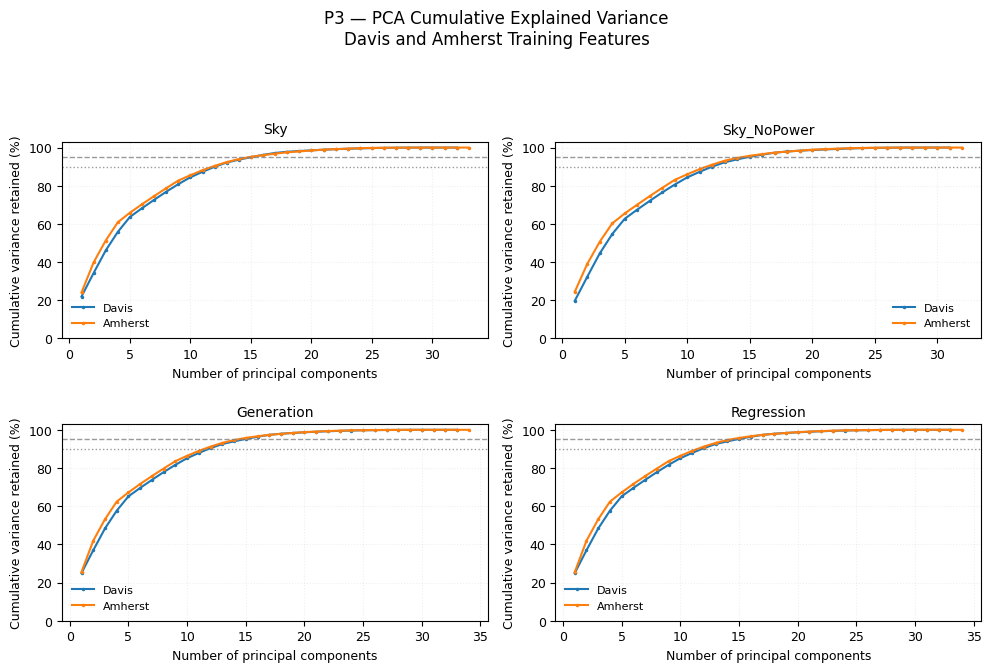

[PREVIEW] P3_PCA_Reconstruction_MSE.pdf


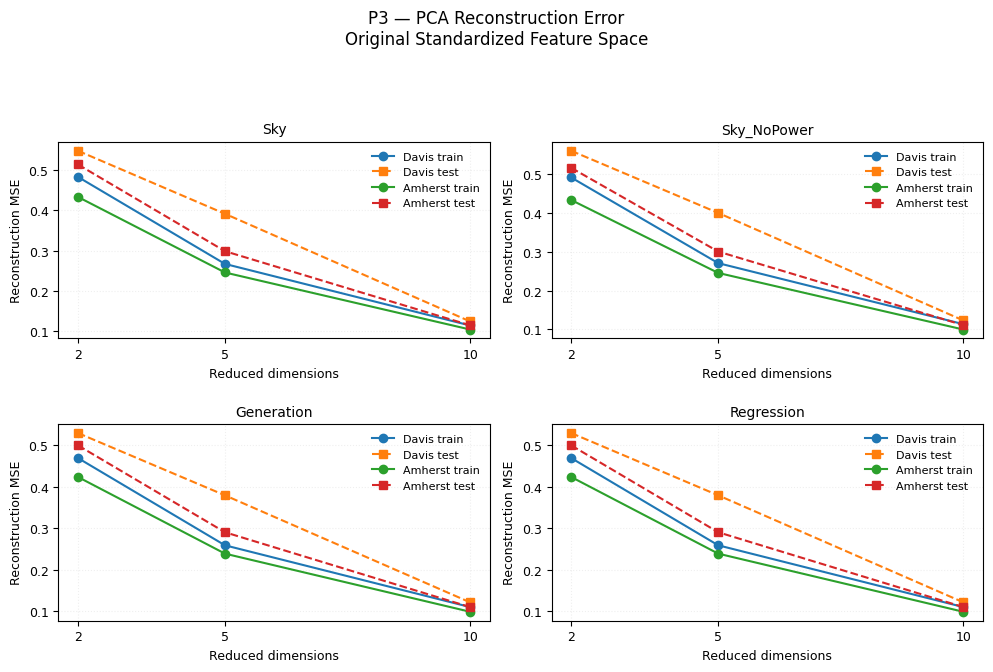


P3 — PCA INTRINSIC EVALUATION COMPLETED

PRIMARY DATASET RESULTS


,Dataset,Task,Reduced Dimensions,Variance Retained (%),Train Reconstruction MSE,Test Reconstruction MSE
0,Amherst_2018_2020,Sky,2,39.8498,0.4333,0.5138
1,Amherst_2018_2020,Sky,5,65.8767,0.2458,0.2987
2,Amherst_2018_2020,Sky,10,85.5149,0.1043,0.1147
3,Amherst_2018_2020,Sky_NoPower,2,39.0538,0.4337,0.5166
4,Amherst_2018_2020,Sky_NoPower,5,65.4846,0.2456,0.3007
5,Amherst_2018_2020,Sky_NoPower,10,85.9786,0.0998,0.1111
6,Amherst_2018_2020,Generation,2,41.9170,0.4232,0.4992
7,Amherst_2018_2020,Generation,5,67.2140,0.2389,0.2903
8,Amherst_2018_2020,Generation,10,86.3933,0.0991,0.1104
9,Amherst_2018_2020,Regression,2,41.9170,0.4232,0.4992



TRAINING-ONLY DIMENSIONALITY THRESHOLDS


,Dataset,Task,D_90,D_95
0,Amherst_2018_2020,Generation,12,15
1,Amherst_2018_2020,Regression,12,15
2,Amherst_2018_2020,Sky,12,15
3,Amherst_2018_2020,Sky_NoPower,12,15
4,Davis_2011_2016,Generation,12,15
5,Davis_2011_2016,Regression,12,15
6,Davis_2011_2016,Sky,13,16
7,Davis_2011_2016,Sky_NoPower,12,15



SAVED OUTPUTS
PCA metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/PCA_Intrinsic_Metrics.csv
Variance curves : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/PCA_Explained_Variance.csv
PCA models      : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models/PCA
Reduced features: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Embeddings/PCA

Intrinsic evaluations: 108
Saved PCA models     : 36
Saved representations: 108

Figures are in preview mode. Set P3_SAVE_FINAL_FIGURES=True and rerun this cell to export.

No supervised prediction models were trained.
PCA was fitted using training features only.
All original targets and split indices are preserved.


In [4]:

# ============================================================
# P3 — Cell 5: PCA Explained Variance and Reconstruction
# ============================================================

import os
import time
import joblib
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA


# ------------------------------------------------------------
# 1. PCA output directories and configuration
# ------------------------------------------------------------

P3_PCA_MODEL_DIR = P3_MODELS_DIR / "PCA"
P3_PCA_EMBEDDING_DIR = P3_EMBEDDINGS_DIR / "PCA"

for directory in (
    P3_PCA_MODEL_DIR,
    P3_PCA_EMBEDDING_DIR
):
    directory.mkdir(parents=True, exist_ok=True)

P3_PCA_RESULTS_PATH = (
    P3_RESULTS_DIR / "PCA_Intrinsic_Metrics.csv"
)

P3_PCA_VARIANCE_PATH = (
    P3_RESULTS_DIR / "PCA_Explained_Variance.csv"
)

P3_PCA_CONFIG = {
    "solver": "full",
    "dimensions": tuple(P3_DIMENSIONS),
    "variance_thresholds": (0.90, 0.95)
}

# PCA with the full SVD solver is deterministic.
# One representation per dataset/task is sufficient;
# downstream supervised experiments will use 3 seeds.

P3_PCA_MODELS = {}
P3_PCA_EMBEDDINGS = {}

pca_metric_rows = []
pca_variance_rows = []


# ------------------------------------------------------------
# 2. Fit full PCA and calculate retained variance
# ------------------------------------------------------------

for dataset_key in sorted(P3_PREPROCESSED):

    P3_PCA_MODELS[dataset_key] = {}
    P3_PCA_EMBEDDINGS[dataset_key] = {}

    for task in P3_TASK_FEATURES:

        start = time.perf_counter()

        prepared = P3_PREPROCESSED[
            dataset_key
        ][task]

        Z_train = np.asarray(
            prepared["X_train"],
            dtype=np.float64
        )

        Z_test = np.asarray(
            prepared["X_test"],
            dtype=np.float64
        )

        n_features = Z_train.shape[1]

        assert n_features >= max(P3_DIMENSIONS)

        # PCA is learned using training features only.
        pca = PCA(
            n_components=None,
            svd_solver=P3_PCA_CONFIG["solver"]
        )

        pca.fit(Z_train)

        train_components = pca.transform(Z_train)
        test_components = pca.transform(Z_test)

        explained_variance = (
            pca.explained_variance_ratio_
        )

        cumulative_variance = np.cumsum(
            explained_variance
        )

        assert np.isfinite(explained_variance).all()

        assert np.isclose(
            cumulative_variance[-1],
            1.0,
            atol=1e-5
        )

        # Determine dimensionality thresholds using
        # TRAINING statistics only.
        d_90 = int(
            np.searchsorted(
                cumulative_variance,
                0.90
            ) + 1
        )

        d_95 = int(
            np.searchsorted(
                cumulative_variance,
                0.95
            ) + 1
        )

        model_path = (
            P3_PCA_MODEL_DIR
            / f"{dataset_key}_{task}_PCA.joblib"
        )

        temporary_model = model_path.with_suffix(
            ".tmp"
        )

        joblib.dump(pca, temporary_model)

        os.replace(
            temporary_model,
            model_path
        )

        P3_PCA_MODELS[dataset_key][task] = pca
        P3_PCA_EMBEDDINGS[dataset_key][task] = {}

        # Save the full explained-variance curve.
        for component_number in range(
            1, len(cumulative_variance) + 1
        ):

            pca_variance_rows.append({
                "Dataset": dataset_key,
                "Task": task,
                "Component": component_number,
                "Explained Variance Ratio": float(
                    explained_variance[
                        component_number - 1
                    ]
                ),
                "Cumulative Explained Variance": float(
                    cumulative_variance[
                        component_number - 1
                    ]
                )
            })

        # ----------------------------------------------------
        # 3. Evaluate d = 2, 5, 10 components
        # ----------------------------------------------------

        for d in P3_DIMENSIONS:

            train_reduced = (
                train_components[:, :d]
                .astype(np.float32)
            )

            test_reduced = (
                test_components[:, :d]
                .astype(np.float32)
            )

            assert train_reduced.shape == (
                len(Z_train), d
            )

            assert test_reduced.shape == (
                len(Z_test), d
            )

            # Reconstruct the standardized original
            # features using only the first d components.
            train_reconstructed = (
                train_components[:, :d]
                @ pca.components_[:d, :]
                + pca.mean_
            )

            test_reconstructed = (
                test_components[:, :d]
                @ pca.components_[:d, :]
                + pca.mean_
            )

            train_mse = float(
                np.mean(
                    (Z_train - train_reconstructed) ** 2
                )
            )

            test_mse = float(
                np.mean(
                    (Z_test - test_reconstructed) ** 2
                )
            )

            retained_variance = float(
                cumulative_variance[d - 1]
            )

            assert train_mse >= 0
            assert test_mse >= 0

            # Store the reduced representation for later
            # supervised learning without refitting PCA.
            embedding_path = (
                P3_PCA_EMBEDDING_DIR
                / f"{dataset_key}_{task}_d{d}.npz"
            )

            temporary_embedding = (
                embedding_path.with_suffix(".tmp")
            )

            with open(
                temporary_embedding, "wb"
            ) as file:

                np.savez_compressed(
                    file,
                    X_train=train_reduced,
                    X_test=test_reduced,
                    train_rows=prepared["train_rows"],
                    test_rows=prepared["test_rows"],
                    dimension=np.int64(d),
                    retained_variance=retained_variance
                )

            os.replace(
                temporary_embedding,
                embedding_path
            )

            P3_PCA_EMBEDDINGS[
                dataset_key
            ][task][d] = {
                "X_train": train_reduced,
                "X_test": test_reduced,
                "path": embedding_path
            }

            pca_metric_rows.append({
                "Dataset": dataset_key,
                "Task": task,
                "Method": "PCA",
                "Original Dimensions": n_features,
                "Reduced Dimensions": d,
                "Train Samples": len(Z_train),
                "Test Samples": len(Z_test),
                "Retained Variance": retained_variance,
                "Train Reconstruction MSE": train_mse,
                "Test Reconstruction MSE": test_mse,
                "Components for 90% Variance": d_90,
                "Components for 95% Variance": d_95
            })

        elapsed = time.perf_counter() - start

        print(
            f"[PASS] {dataset_key:24s} | "
            f"{task:12s} | "
            f"{n_features:2d} input dims | "
            f"90% at d={d_90:2d} | "
            f"95% at d={d_95:2d} | "
            f"{elapsed:.2f}s",
            flush=True
        )


# ------------------------------------------------------------
# 4. Save and verify intrinsic PCA results
# ------------------------------------------------------------

P3_PCA_METRICS = pd.DataFrame(
    pca_metric_rows
)

P3_PCA_VARIANCE = pd.DataFrame(
    pca_variance_rows
)

expected_evaluations = (
    len(P3_DATASETS)
    * len(P3_TASK_FEATURES)
    * len(P3_DIMENSIONS)
)

assert expected_evaluations == 108

assert len(P3_PCA_METRICS) == (
    expected_evaluations
)

assert not P3_PCA_METRICS.duplicated(
    ["Dataset", "Task", "Reduced Dimensions"]
).any()

# Reconstruction error on the training set cannot
# increase as additional principal components are used.
for _, group in P3_PCA_METRICS.groupby(
    ["Dataset", "Task"]
):

    ordered = group.sort_values(
        "Reduced Dimensions"
    )

    mse = ordered[
        "Train Reconstruction MSE"
    ].to_numpy()

    assert np.all(np.diff(mse) <= 1e-7)

    variance = ordered[
        "Retained Variance"
    ].to_numpy()

    assert np.all(np.diff(variance) >= -1e-7)

P3_PCA_METRICS.to_csv(
    P3_PCA_RESULTS_PATH,
    index=False
)

P3_PCA_VARIANCE.to_csv(
    P3_PCA_VARIANCE_PATH,
    index=False
)


# ------------------------------------------------------------
# 5. Prepare figure formatting
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


def p3_finalize_pca_figure(fig, filename):

    if P3_SAVE_FINAL_FIGURES:

        output_path = P3_FIGURES_DIR / filename

        fig.savefig(
            output_path,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {filename}")

    else:

        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)


P3_PCA_PRIMARY_DATASETS = {
    "Davis": "Davis_2011_2016",
    "Amherst": "Amherst_2018_2020"
}

P3_PCA_PLOT_TASKS = (
    "Sky",
    "Sky_NoPower",
    "Generation",
    "Regression"
)


# ------------------------------------------------------------
# 6. Figure 1: PCA cumulative explained variance
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, task in zip(
    axes.ravel(),
    P3_PCA_PLOT_TASKS
):

    for city, dataset_key in (
        P3_PCA_PRIMARY_DATASETS.items()
    ):

        curve = P3_PCA_VARIANCE[
            (P3_PCA_VARIANCE["Dataset"] == dataset_key)
            & (P3_PCA_VARIANCE["Task"] == task)
        ].sort_values("Component")

        ax.plot(
            curve["Component"],
            100 * curve[
                "Cumulative Explained Variance"
            ],
            marker=".",
            markersize=3,
            linewidth=1.5,
            label=city
        )

    ax.axhline(
        90,
        color="gray",
        linestyle=":",
        linewidth=1,
        alpha=0.8
    )

    ax.axhline(
        95,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.8
    )

    ax.set_title(task)
    ax.set_xlabel("Number of principal components")
    ax.set_ylabel("Cumulative variance retained (%)")
    ax.set_ylim(0, 103)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — PCA Cumulative Explained Variance\n"
    "Davis and Amherst Training Features",
    fontsize=12
)

fig.tight_layout(
    rect=(0, 0, 1, 0.91),
    h_pad=2.0
)

p3_finalize_pca_figure(
    fig,
    "P3_PCA_Cumulative_Explained_Variance.pdf"
)


# ------------------------------------------------------------
# 7. Figure 2: Reconstruction error versus dimension
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, task in zip(
    axes.ravel(),
    P3_PCA_PLOT_TASKS
):

    for city, dataset_key in (
        P3_PCA_PRIMARY_DATASETS.items()
    ):

        curve = P3_PCA_METRICS[
            (P3_PCA_METRICS["Dataset"] == dataset_key)
            & (P3_PCA_METRICS["Task"] == task)
        ].sort_values("Reduced Dimensions")

        ax.plot(
            curve["Reduced Dimensions"],
            curve["Train Reconstruction MSE"],
            marker="o",
            linewidth=1.5,
            label=f"{city} train"
        )

        ax.plot(
            curve["Reduced Dimensions"],
            curve["Test Reconstruction MSE"],
            marker="s",
            linestyle="--",
            linewidth=1.5,
            label=f"{city} test"
        )

    ax.set_title(task)
    ax.set_xlabel("Reduced dimensions")
    ax.set_ylabel("Reconstruction MSE")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — PCA Reconstruction Error\n"
    "Original Standardized Feature Space",
    fontsize=12
)

fig.tight_layout(
    rect=(0, 0, 1, 0.91),
    h_pad=2.0
)

p3_finalize_pca_figure(
    fig,
    "P3_PCA_Reconstruction_MSE.pdf"
)


# ------------------------------------------------------------
# 8. Summarize Davis and Amherst PCA quality
# ------------------------------------------------------------

primary_metrics = P3_PCA_METRICS[
    P3_PCA_METRICS["Dataset"].isin(
        P3_PRIMARY_KEYS
    )
].copy()

primary_metrics["Variance Retained (%)"] = (
    100 * primary_metrics["Retained Variance"]
)

print("\n" + "=" * 75)
print("P3 — PCA INTRINSIC EVALUATION COMPLETED")
print("=" * 75)

print("\nPRIMARY DATASET RESULTS")

display(
    primary_metrics[
        [
            "Dataset",
            "Task",
            "Reduced Dimensions",
            "Variance Retained (%)",
            "Train Reconstruction MSE",
            "Test Reconstruction MSE"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nTRAINING-ONLY DIMENSIONALITY THRESHOLDS")

threshold_summary = (
    P3_PCA_METRICS.groupby(
        ["Dataset", "Task"],
        as_index=False
    )
    .agg(
        D_90=(
            "Components for 90% Variance",
            "first"
        ),
        D_95=(
            "Components for 95% Variance",
            "first"
        )
    )
)

display(
    threshold_summary[
        threshold_summary["Dataset"].isin(
            P3_PRIMARY_KEYS
        )
    ].reset_index(drop=True)
)

print("\nSAVED OUTPUTS")
print(f"PCA metrics     : {P3_PCA_RESULTS_PATH}")
print(f"Variance curves : {P3_PCA_VARIANCE_PATH}")
print(f"PCA models      : {P3_PCA_MODEL_DIR}")
print(f"Reduced features: {P3_PCA_EMBEDDING_DIR}")

print(
    f"\nIntrinsic evaluations: "
    f"{len(P3_PCA_METRICS)}"
)

print(
    f"Saved PCA models     : "
    f"{len(list(P3_PCA_MODEL_DIR.glob('*.joblib')))}"
)

print(
    f"Saved representations: "
    f"{len(list(P3_PCA_EMBEDDING_DIR.glob('*.npz')))}"
)

if P3_SAVE_FINAL_FIGURES:
    print("\nBoth PCA PDF figures were exported.")
else:
    print(
        "\nFigures are in preview mode. "
        "Set P3_SAVE_FINAL_FIGURES=True "
        "and rerun this cell to export."
    )

print("\nNo supervised prediction models were trained.")
print("PCA was fitted using training features only.")
print("All original targets and split indices are preserved.")


P3 — NYSTRÖM-APPROXIMATED KERNEL PCA
Kernel                  : RBF
Nyström landmarks       : 192
Reduced dimensions      : (2, 5, 10)
Reconstruction decoder  : Ridge
Random seed             : 42
GPU required            : No
Final figure export     : False
[PASS] Amherst_2018_2020        | Sky          | d=10 kernel variance= 57.33% | 0.7s
[PASS] Amherst_2018_2020        | Sky_NoPower  | d=10 kernel variance= 57.38% | 0.4s
[PASS] Amherst_2018_2020        | Generation   | d=10 kernel variance= 57.47% | 0.6s
[PASS] Amherst_2018_2020        | Regression   | d=10 kernel variance= 57.47% | 1.5s
[PASS] Davis_2011_2016          | Sky          | d=10 kernel variance= 57.44% | 1.9s
[PASS] Davis_2011_2016          | Sky_NoPower  | d=10 kernel variance= 57.48% | 1.1s
[PASS] Davis_2011_2016          | Generation   | d=10 kernel variance= 57.47% | 1.0s
[PASS] Davis_2011_2016          | Regression   | d=10 kernel variance= 57.47% | 0.7s
[PASS] Davis_2014_2016          | Sky          | d=10 kernel var

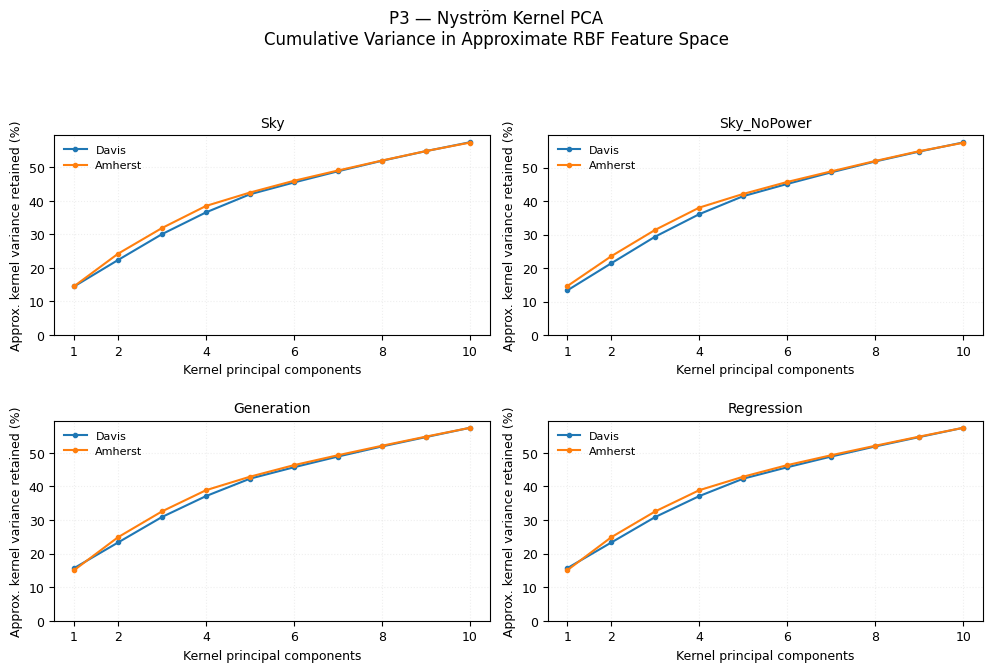

[PREVIEW] P3_KPCA_Preimage_Reconstruction_MSE.pdf


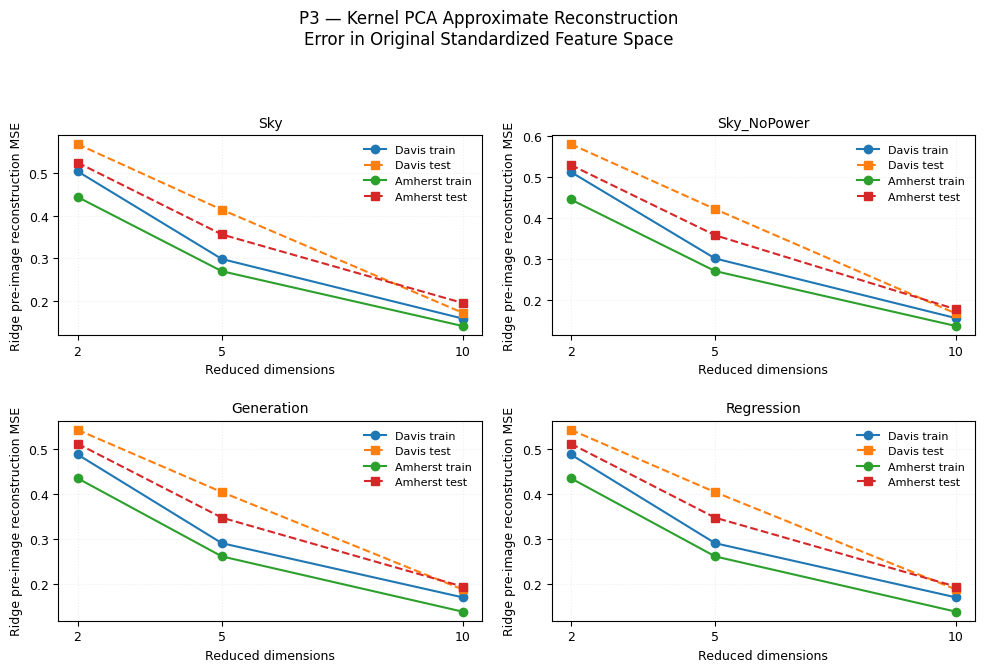


P3 — KERNEL PCA INTRINSIC EVALUATION COMPLETED

DAVIS AND AMHERST RESULTS


,Dataset,Task,Reduced Dimensions,Kernel Variance (%),Train Reconstruction MSE,Test Reconstruction MSE
0,Amherst_2018_2020,Sky,2,24.2337,0.4443,0.5252
1,Amherst_2018_2020,Sky,5,42.4605,0.2696,0.3561
2,Amherst_2018_2020,Sky,10,57.3343,0.1408,0.1951
3,Amherst_2018_2020,Sky_NoPower,2,23.5375,0.4452,0.5297
4,Amherst_2018_2020,Sky_NoPower,5,42.1182,0.2702,0.3579
5,Amherst_2018_2020,Sky_NoPower,10,57.3765,0.1360,0.1770
6,Amherst_2018_2020,Generation,2,24.8781,0.4352,0.5118
7,Amherst_2018_2020,Generation,5,42.9057,0.2617,0.3477
8,Amherst_2018_2020,Generation,10,57.4697,0.1392,0.1949
9,Amherst_2018_2020,Regression,2,24.8781,0.4352,0.5118



EXPERIMENT VERIFICATION
Intrinsic evaluations : 108
Kernel variance rows  : 360
Saved KPCA models     : 36
Saved representations: 108

SAVED FILES
Metrics        : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/KPCA_Intrinsic_Metrics.csv
Kernel variance: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/KPCA_Kernel_Variance.csv
Models         : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models/Kernel_PCA
Embeddings     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Embeddings/Kernel_PCA

Both Kernel PCA figures are in preview mode.

No supervised models were trained.
All kernel landmarks came from training data.
No test labels were used for representation learning.


In [5]:

# ============================================================
# P3 — Cell 6: Nyström-Approximated RBF Kernel PCA
# ============================================================

import os
import json
import time
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.kernel_approximation import Nystroem
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge

from IPython.display import display


# ------------------------------------------------------------
# 1. Configuration and output directories
# ------------------------------------------------------------

P3_KPCA_CONFIG = {
    "method": "Nystroem_Approximate_RBF_KPCA",
    "version": 1,
    "landmarks": 192,
    "kernel": "rbf",
    "gamma_rule": "1 / encoded_feature_count",
    "pca_solver": "randomized",
    "decoder": "Ridge",
    "decoder_alpha": 1.0,
    "reducer_seed": 42,
    "dimensions": list(P3_DIMENSIONS)
}

P3_KPCA_CONFIG_ID = json.dumps(
    P3_KPCA_CONFIG,
    sort_keys=True
)

P3_KPCA_MODEL_DIR = (
    P3_MODELS_DIR / "Kernel_PCA"
)

P3_KPCA_EMBEDDING_DIR = (
    P3_EMBEDDINGS_DIR / "Kernel_PCA"
)

P3_KPCA_METRICS_PATH = (
    P3_RESULTS_DIR / "KPCA_Intrinsic_Metrics.csv"
)

P3_KPCA_SPECTRUM_PATH = (
    P3_RESULTS_DIR / "KPCA_Kernel_Variance.csv"
)

for directory in (
    P3_KPCA_MODEL_DIR,
    P3_KPCA_EMBEDDING_DIR
):
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# 2. Resume safely from existing saved results
# ------------------------------------------------------------

if P3_KPCA_METRICS_PATH.is_file():

    kpca_records = pd.read_csv(
        P3_KPCA_METRICS_PATH
    ).to_dict("records")

    for record in kpca_records:
        assert record["Config ID"] == P3_KPCA_CONFIG_ID

else:
    kpca_records = []


if P3_KPCA_SPECTRUM_PATH.is_file():

    spectrum_records = pd.read_csv(
        P3_KPCA_SPECTRUM_PATH
    ).to_dict("records")

else:
    spectrum_records = []


def p3_kpca_save_csv(records, path):

    temporary = path.with_suffix(".tmp")

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(
        temporary,
        path
    )


# Saved file references for later downstream experiments.
P3_KPCA_MODELS = {}
P3_KPCA_EMBEDDINGS = {}


# ------------------------------------------------------------
# 3. Fit nonlinear representations on training data only
# ------------------------------------------------------------

print("P3 — NYSTRÖM-APPROXIMATED KERNEL PCA")
print("=" * 75)

print(f"Kernel                  : RBF")
print(f"Nyström landmarks       : {P3_KPCA_CONFIG['landmarks']}")
print(f"Reduced dimensions      : {P3_DIMENSIONS}")
print(f"Reconstruction decoder  : Ridge")
print(f"Random seed             : {P3_KPCA_CONFIG['reducer_seed']}")
print(f"GPU required            : No")
print(f"Final figure export     : {P3_SAVE_FINAL_FIGURES}")


for dataset_key in sorted(P3_PREPROCESSED):

    P3_KPCA_MODELS[dataset_key] = {}
    P3_KPCA_EMBEDDINGS[dataset_key] = {}

    for task in P3_TASK_FEATURES:

        start = time.perf_counter()

        model_path = (
            P3_KPCA_MODEL_DIR
            / f"{dataset_key}_{task}_KPCA.joblib"
        )

        embedding_paths = {
            d: (
                P3_KPCA_EMBEDDING_DIR
                / f"{dataset_key}_{task}_d{d}.npz"
            )
            for d in P3_DIMENSIONS
        }

        P3_KPCA_MODELS[
            dataset_key
        ][task] = model_path

        P3_KPCA_EMBEDDINGS[
            dataset_key
        ][task] = embedding_paths

        existing_dimensions = {
            int(record["Reduced Dimensions"])
            for record in kpca_records
            if (
                record["Dataset"] == dataset_key
                and record["Task"] == task
            )
        }

        existing_spectrum = [
            record
            for record in spectrum_records
            if (
                record["Dataset"] == dataset_key
                and record["Task"] == task
            )
        ]

        cached = (
            model_path.is_file()
            and all(
                path.is_file()
                for path in embedding_paths.values()
            )
            and existing_dimensions == set(P3_DIMENSIONS)
            and len(existing_spectrum) == max(P3_DIMENSIONS)
        )

        if cached:

            print(
                f"[CACHED] {dataset_key:24s} | {task}",
                flush=True
            )

            continue

        prepared = P3_PREPROCESSED[
            dataset_key
        ][task]

        X_train = np.asarray(
            prepared["X_train"],
            dtype=np.float32
        )

        X_test = np.asarray(
            prepared["X_test"],
            dtype=np.float32
        )

        assert np.isfinite(X_train).all()
        assert np.isfinite(X_test).all()

        n_train, original_dim = X_train.shape

        n_landmarks = min(
            P3_KPCA_CONFIG["landmarks"],
            n_train
        )

        gamma = 1.0 / original_dim

        # ----------------------------------------------------
        # A. Approximate the RBF kernel with Nyström
        #    landmarks selected from TRAINING features.
        # ----------------------------------------------------

        kernel_map = Nystroem(
            kernel="rbf",
            gamma=gamma,
            n_components=n_landmarks,
            random_state=P3_KPCA_CONFIG[
                "reducer_seed"
            ]
        )

        H_train = kernel_map.fit_transform(
            X_train
        )

        H_test = kernel_map.transform(
            X_test
        )

        assert H_train.shape == (
            n_train, n_landmarks
        )

        assert H_test.shape == (
            len(X_test), n_landmarks
        )

        assert np.isfinite(H_train).all()
        assert np.isfinite(H_test).all()

        # ----------------------------------------------------
        # B. Apply centered PCA in the approximate
        #    nonlinear RBF feature space.
        #
        # This approximates Kernel PCA without constructing
        # an n_train-by-n_train kernel matrix.
        # ----------------------------------------------------

        kernel_pca = PCA(
            n_components=max(P3_DIMENSIONS),
            svd_solver="randomized",
            random_state=P3_KPCA_CONFIG[
                "reducer_seed"
            ]
        )

        full_train_embedding = (
            kernel_pca.fit_transform(H_train)
        )

        full_test_embedding = (
            kernel_pca.transform(H_test)
        )

        kernel_variance = (
            kernel_pca.explained_variance_ratio_
        )

        cumulative_kernel_variance = (
            np.cumsum(kernel_variance)
        )

        assert np.isfinite(kernel_variance).all()

        assert np.all(
            np.diff(cumulative_kernel_variance) >= -1e-8
        )

        assert cumulative_kernel_variance[-1] <= (
            1.0 + 1e-6
        )

        # ----------------------------------------------------
        # C. Save the reusable nonlinear transformation
        # ----------------------------------------------------

        pipeline = {
            "method": "Nystroem_Approximate_RBF_KPCA",
            "kernel_map": kernel_map,
            "pca": kernel_pca,
            "gamma": gamma,
            "original_dimensions": original_dim,
            "config": P3_KPCA_CONFIG
        }

        temporary_model = (
            model_path.with_suffix(".tmp")
        )

        joblib.dump(
            pipeline,
            temporary_model
        )

        os.replace(
            temporary_model,
            model_path
        )

        # ----------------------------------------------------
        # D. Save the approximate kernel variance curve
        # ----------------------------------------------------

        spectrum_records = [
            record
            for record in spectrum_records
            if not (
                record["Dataset"] == dataset_key
                and record["Task"] == task
            )
        ]

        for component in range(
            1, max(P3_DIMENSIONS) + 1
        ):

            spectrum_records.append({
                "Dataset": dataset_key,
                "Task": task,
                "Component": component,
                "Kernel Variance Ratio": float(
                    kernel_variance[component - 1]
                ),
                "Cumulative Kernel Variance": float(
                    cumulative_kernel_variance[
                        component - 1
                    ]
                )
            })

        # ----------------------------------------------------
        # E. Evaluate representations at d = 2, 5, 10
        # ----------------------------------------------------

        new_metric_rows = []

        for d in P3_DIMENSIONS:

            Z_train = np.asarray(
                full_train_embedding[:, :d],
                dtype=np.float32
            )

            Z_test = np.asarray(
                full_test_embedding[:, :d],
                dtype=np.float32
            )

            # Approximate pre-image reconstruction:
            # A Ridge decoder maps the nonlinear reduced
            # representation back to the original encoded
            # and standardized input-feature space.
            #
            # The decoder is trained exclusively on
            # training features, not supervised labels.

            decoder = Ridge(
                alpha=P3_KPCA_CONFIG[
                    "decoder_alpha"
                ]
            )

            decoder.fit(
                Z_train,
                X_train
            )

            X_train_reconstructed = (
                decoder.predict(Z_train)
            )

            X_test_reconstructed = (
                decoder.predict(Z_test)
            )

            train_mse = float(
                np.mean(
                    (
                        X_train.astype(np.float64)
                        - X_train_reconstructed
                    ) ** 2
                )
            )

            test_mse = float(
                np.mean(
                    (
                        X_test.astype(np.float64)
                        - X_test_reconstructed
                    ) ** 2
                )
            )

            assert np.isfinite(train_mse)
            assert np.isfinite(test_mse)

            assert train_mse >= 0
            assert test_mse >= 0

            embedding_path = embedding_paths[d]

            temporary_embedding = (
                embedding_path.with_suffix(".tmp")
            )

            with open(
                temporary_embedding,
                "wb"
            ) as file:

                np.savez_compressed(
                    file,
                    X_train=Z_train,
                    X_test=Z_test,
                    train_rows=prepared["train_rows"],
                    test_rows=prepared["test_rows"],
                    dimension=np.int64(d),
                    retained_kernel_variance=float(
                        cumulative_kernel_variance[d - 1]
                    )
                )

            os.replace(
                temporary_embedding,
                embedding_path
            )

            new_metric_rows.append({
                "Dataset": dataset_key,
                "Task": task,
                "Method": (
                    "Nyström Approximate Kernel PCA"
                ),
                "Original Dimensions": original_dim,
                "Reduced Dimensions": int(d),
                "Train Samples": len(X_train),
                "Test Samples": len(X_test),
                "Nyström Landmarks": n_landmarks,
                "RBF Gamma": gamma,
                "Retained Kernel Variance": float(
                    cumulative_kernel_variance[d - 1]
                ),
                "Train Reconstruction MSE": train_mse,
                "Test Reconstruction MSE": test_mse,
                "Decoder": "Ridge pre-image approximation",
                "Config ID": P3_KPCA_CONFIG_ID
            })

        # Replace incomplete prior results for the
        # current dataset/task to allow safe resumption.
        kpca_records = [
            record
            for record in kpca_records
            if not (
                record["Dataset"] == dataset_key
                and record["Task"] == task
            )
        ]

        kpca_records.extend(new_metric_rows)

        p3_kpca_save_csv(
            kpca_records,
            P3_KPCA_METRICS_PATH
        )

        p3_kpca_save_csv(
            spectrum_records,
            P3_KPCA_SPECTRUM_PATH
        )

        elapsed = time.perf_counter() - start

        variance_10 = (
            cumulative_kernel_variance[9] * 100.0
        )

        print(
            f"[PASS] {dataset_key:24s} | "
            f"{task:12s} | "
            f"d=10 kernel variance={variance_10:6.2f}% | "
            f"{elapsed:.1f}s",
            flush=True
        )


# ------------------------------------------------------------
# 4. Verify the complete experiment inventory
# ------------------------------------------------------------

P3_KPCA_METRICS = pd.read_csv(
    P3_KPCA_METRICS_PATH
)

P3_KPCA_SPECTRUM = pd.read_csv(
    P3_KPCA_SPECTRUM_PATH
)

expected_metrics = (
    len(P3_DATASETS)
    * len(P3_TASK_FEATURES)
    * len(P3_DIMENSIONS)
)

expected_spectrum = (
    len(P3_DATASETS)
    * len(P3_TASK_FEATURES)
    * max(P3_DIMENSIONS)
)

assert expected_metrics == 108

assert len(P3_KPCA_METRICS) == expected_metrics

assert len(P3_KPCA_SPECTRUM) == expected_spectrum

assert not P3_KPCA_METRICS.duplicated(
    ["Dataset", "Task", "Reduced Dimensions"]
).any()

assert not P3_KPCA_SPECTRUM.duplicated(
    ["Dataset", "Task", "Component"]
).any()

assert len(
    list(P3_KPCA_MODEL_DIR.glob("*.joblib"))
) == 36

assert len(
    list(P3_KPCA_EMBEDDING_DIR.glob("*.npz"))
) == 108

for _, group in P3_KPCA_METRICS.groupby(
    ["Dataset", "Task"]
):

    ordered = group.sort_values(
        "Reduced Dimensions"
    )

    variance = ordered[
        "Retained Kernel Variance"
    ].to_numpy()

    assert np.all(
        np.diff(variance) >= -1e-8
    )

    # A larger embedding permits the Ridge decoder
    # to attain equal or lower training error, apart
    # from small floating-point differences.
    errors = ordered[
        "Train Reconstruction MSE"
    ].to_numpy()

    assert np.all(
        np.diff(errors) <= 2e-5
    )


# ------------------------------------------------------------
# 5. Figure helper: preview or save vector PDF
# ------------------------------------------------------------

def p3_finalize_kpca_figure(fig, filename):

    fig.tight_layout(
        rect=(0, 0, 1, 0.92),
        h_pad=2.0
    )

    if P3_SAVE_FINAL_FIGURES:

        fig.savefig(
            P3_FIGURES_DIR / filename,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {filename}")

    else:
        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)


P3_KPCA_PRIMARY_DATASETS = {
    "Davis": "Davis_2011_2016",
    "Amherst": "Amherst_2018_2020"
}


# ------------------------------------------------------------
# 6. Figure 1: Approximate kernel variance retained
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, task in zip(
    axes.ravel(),
    P3_TASK_FEATURES
):

    for city, dataset_key in (
        P3_KPCA_PRIMARY_DATASETS.items()
    ):

        subset = P3_KPCA_SPECTRUM[
            (P3_KPCA_SPECTRUM["Dataset"] == dataset_key)
            & (P3_KPCA_SPECTRUM["Task"] == task)
        ].sort_values("Component")

        ax.plot(
            subset["Component"],
            100 * subset[
                "Cumulative Kernel Variance"
            ],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=city
        )

    ax.set_title(task)
    ax.set_xlabel("Kernel principal components")
    ax.set_ylabel("Approx. kernel variance retained (%)")
    ax.set_xticks((1, 2, 4, 6, 8, 10))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — Nyström Kernel PCA\n"
    "Cumulative Variance in Approximate RBF Feature Space",
    fontsize=12
)

p3_finalize_kpca_figure(
    fig,
    "P3_KPCA_Approximate_Kernel_Variance.pdf"
)


# ------------------------------------------------------------
# 7. Figure 2: Reconstruction MSE versus dimension
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, task in zip(
    axes.ravel(),
    P3_TASK_FEATURES
):

    for city, dataset_key in (
        P3_KPCA_PRIMARY_DATASETS.items()
    ):

        subset = P3_KPCA_METRICS[
            (P3_KPCA_METRICS["Dataset"] == dataset_key)
            & (P3_KPCA_METRICS["Task"] == task)
        ].sort_values("Reduced Dimensions")

        ax.plot(
            subset["Reduced Dimensions"],
            subset["Train Reconstruction MSE"],
            marker="o",
            linewidth=1.5,
            label=f"{city} train"
        )

        ax.plot(
            subset["Reduced Dimensions"],
            subset["Test Reconstruction MSE"],
            marker="s",
            linestyle="--",
            linewidth=1.5,
            label=f"{city} test"
        )

    ax.set_title(task)
    ax.set_xlabel("Reduced dimensions")
    ax.set_ylabel("Ridge pre-image reconstruction MSE")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — Kernel PCA Approximate Reconstruction\n"
    "Error in Original Standardized Feature Space",
    fontsize=12
)

p3_finalize_kpca_figure(
    fig,
    "P3_KPCA_Preimage_Reconstruction_MSE.pdf"
)


# ------------------------------------------------------------
# 8. Display the main results
# ------------------------------------------------------------

primary_results = P3_KPCA_METRICS[
    P3_KPCA_METRICS["Dataset"].isin(
        P3_PRIMARY_KEYS
    )
].copy()

primary_results["Kernel Variance (%)"] = (
    100 * primary_results[
        "Retained Kernel Variance"
    ]
)

print("\n" + "=" * 75)
print("P3 — KERNEL PCA INTRINSIC EVALUATION COMPLETED")
print("=" * 75)

print("\nDAVIS AND AMHERST RESULTS")

display(
    primary_results[
        [
            "Dataset",
            "Task",
            "Reduced Dimensions",
            "Kernel Variance (%)",
            "Train Reconstruction MSE",
            "Test Reconstruction MSE"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nEXPERIMENT VERIFICATION")
print(f"Intrinsic evaluations : {len(P3_KPCA_METRICS)}")
print(f"Kernel variance rows  : {len(P3_KPCA_SPECTRUM)}")
print(
    f"Saved KPCA models     : "
    f"{len(list(P3_KPCA_MODEL_DIR.glob('*.joblib')))}"
)
print(
    f"Saved representations: "
    f"{len(list(P3_KPCA_EMBEDDING_DIR.glob('*.npz')))}"
)

print("\nSAVED FILES")
print(f"Metrics        : {P3_KPCA_METRICS_PATH}")
print(f"Kernel variance: {P3_KPCA_SPECTRUM_PATH}")
print(f"Models         : {P3_KPCA_MODEL_DIR}")
print(f"Embeddings     : {P3_KPCA_EMBEDDING_DIR}")

if P3_SAVE_FINAL_FIGURES:
    print("\nBoth Kernel PCA figures exported.")
else:
    print("\nBoth Kernel PCA figures are in preview mode.")

print("\nNo supervised models were trained.")
print("All kernel landmarks came from training data.")
print("No test labels were used for representation learning.")


P3 — UNSUPERVISED NEURAL AUTOENCODER
Device                       : cuda
Bottleneck dimensions        : (2, 5, 10)
Random seeds                 : (42, 123, 2026)
Epochs per model             : 35
Batch size                   : 1024
Unique AE training runs      : 243
Total saved representations  : 324
Existing metric records      : 0
[001/243] Amherst_2018_2020        | Sky          | d= 2 | seed=  42 | Train MSE=0.3495 | Test MSE=0.4223
[002/243] Amherst_2018_2020        | Sky          | d= 2 | seed= 123 | Train MSE=0.3475 | Test MSE=0.4089
[003/243] Amherst_2018_2020        | Sky          | d= 2 | seed=2026 | Train MSE=0.3518 | Test MSE=0.4323
[004/243] Amherst_2018_2020        | Sky          | d= 5 | seed=  42 | Train MSE=0.1748 | Test MSE=0.2740
[005/243] Amherst_2018_2020        | Sky          | d= 5 | seed= 123 | Train MSE=0.1752 | Test MSE=0.2387
[006/243] Amherst_2018_2020        | Sky          | d= 5 | seed=2026 | Train MSE=0.1702 | Test MSE=0.2568
[007/243] Amherst_2018_2020  

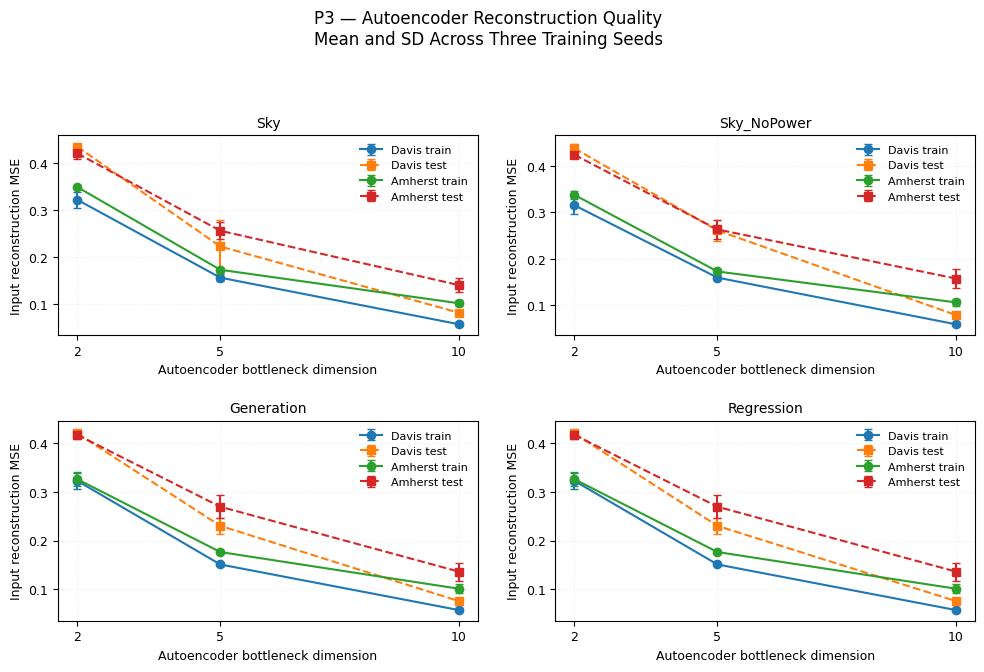

[PREVIEW] P3_PCA_KPCA_AE_Reconstruction_Comparison.pdf


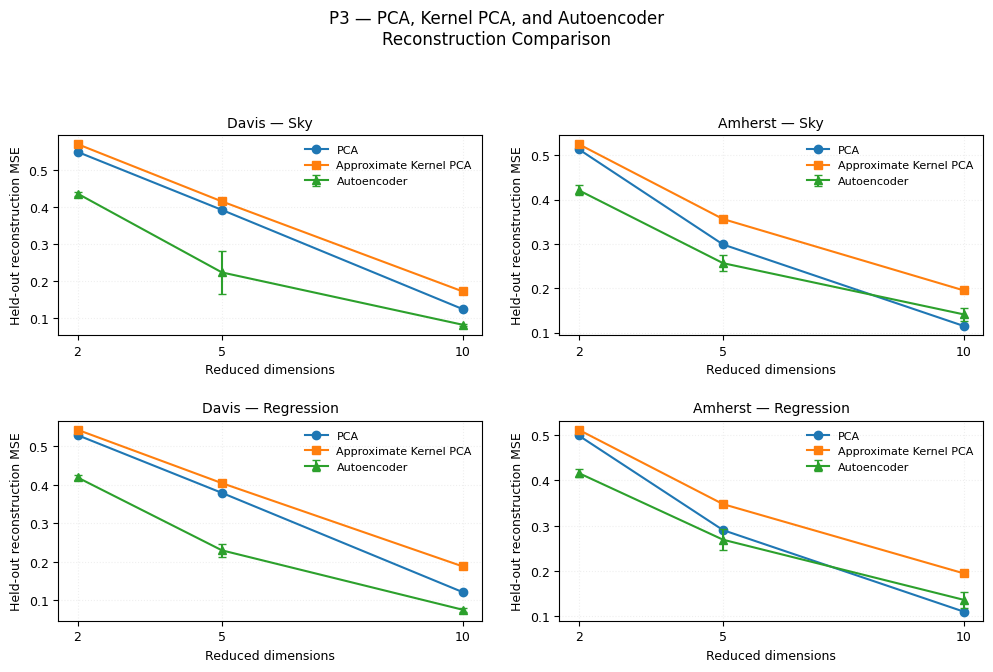


P3 — AUTOENCODER INTRINSIC EVALUATION COMPLETED

DAVIS AND AMHERST RESULTS


,Dataset,Task,Reduced Dimensions,Train_MSE_Mean,Test_MSE_Mean,Test_MSE_SD
0,Amherst_2018_2020,Generation,2,0.3255,0.4163,0.0096
1,Amherst_2018_2020,Generation,5,0.1764,0.2692,0.0231
2,Amherst_2018_2020,Generation,10,0.1014,0.1365,0.0184
3,Amherst_2018_2020,Regression,2,0.3255,0.4163,0.0096
4,Amherst_2018_2020,Regression,5,0.1764,0.2692,0.0231
5,Amherst_2018_2020,Regression,10,0.1014,0.1365,0.0184
6,Amherst_2018_2020,Sky,2,0.3496,0.4212,0.0117
7,Amherst_2018_2020,Sky,5,0.1734,0.2565,0.0177
8,Amherst_2018_2020,Sky,10,0.1022,0.1409,0.0152
9,Amherst_2018_2020,Sky_NoPower,2,0.3374,0.4235,0.0024



VERIFICATION
Neural-network fits     : 243
Intrinsic evaluations  : 324
Three-seed summaries   : 108
Saved checkpoints      : 243
Saved representations  : 324

SAVED FILES
Metrics  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/AE_Intrinsic_Metrics.csv
Summary  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/AE_Intrinsic_Summary.csv
Models   : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models/Autoencoder
Features : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Embeddings/Autoencoder

Both AE figures are in preview mode.

All autoencoders were trained without task labels.
No held-out test features were used for fitting.
Three independent AE initialization seeds evaluated.


In [6]:

# ============================================================
# P3 — Cell 7: Unsupervised PyTorch Autoencoder
# ============================================================

import os
import json
import time
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from IPython.display import display


# ------------------------------------------------------------
# 1. Experimental configuration
# ------------------------------------------------------------

P3_AE_CONFIG = {
    "version": "P3_AE_v1",
    "hidden_dimensions": [64, 32],
    "epochs": 35,
    "batch_size": 1024,
    "learning_rate": 0.001,
    "weight_decay": 0.00001,
    "loss": "MSE",
    "dimensions": list(P3_DIMENSIONS),
    "seeds": list(P3_SEEDS)
}

P3_AE_CONFIG_ID = json.dumps(
    P3_AE_CONFIG,
    sort_keys=True
)

P3_AE_MODEL_DIR = P3_MODELS_DIR / "Autoencoder"
P3_AE_EMBEDDING_DIR = P3_EMBEDDINGS_DIR / "Autoencoder"

P3_AE_METRICS_PATH = (
    P3_RESULTS_DIR / "AE_Intrinsic_Metrics.csv"
)

for folder in (
    P3_AE_MODEL_DIR,
    P3_AE_EMBEDDING_DIR
):
    folder.mkdir(parents=True, exist_ok=True)

# Generation and Regression use identical features.
# The Regression representation is reused for Generation.
P3_AE_TRAIN_TASKS = (
    "Sky",
    "Sky_NoPower",
    "Regression"
)

P3_AE_ALL_TASKS = tuple(P3_TASK_FEATURES)


# ------------------------------------------------------------
# 2. Reproducibility
# ------------------------------------------------------------

def p3_set_ae_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# 3. Neural encoder-decoder architecture
# ------------------------------------------------------------

class P3Autoencoder(nn.Module):

    def __init__(self, input_dim, latent_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction

    def encode(self, x):
        return self.encoder(x)


# ------------------------------------------------------------
# 4. Train an autoencoder on training features only
# ------------------------------------------------------------

def p3_train_autoencoder(
    X_train,
    latent_dim,
    seed
):
    """
    Minimize unsupervised input reconstruction MSE.

    All chronological training observations are used.
    Epoch count and hyperparameters are fixed in advance.

    No classification labels, regression targets, or
    held-out test observations are used for optimization.
    """

    p3_set_ae_seed(seed)

    X_train = np.asarray(
        X_train,
        dtype=np.float32
    )

    n_samples, input_dim = X_train.shape

    model = P3Autoencoder(
        input_dim=input_dim,
        latent_dim=latent_dim
    ).to(P3_DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P3_AE_CONFIG["learning_rate"],
        weight_decay=P3_AE_CONFIG["weight_decay"]
    )

    # The feature matrix is small enough to reside on
    # the Tesla T4 GPU, avoiding repeated host transfers.
    X_tensor = torch.from_numpy(
        X_train
    ).to(P3_DEVICE)

    shuffle_generator = (
        torch.Generator().manual_seed(seed)
    )

    final_epoch_mse = None

    for epoch in range(
        P3_AE_CONFIG["epochs"]
    ):

        model.train()

        permutation = torch.randperm(
            n_samples,
            generator=shuffle_generator
        ).to(P3_DEVICE)

        total_squared_error = 0.0

        for positions in permutation.split(
            P3_AE_CONFIG["batch_size"]
        ):

            batch = X_tensor[positions]

            optimizer.zero_grad(
                set_to_none=True
            )

            reconstruction = model(batch)

            loss = nn.functional.mse_loss(
                reconstruction,
                batch
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

            total_squared_error += (
                float(loss.detach().item())
                * len(positions)
            )

        final_epoch_mse = (
            total_squared_error / n_samples
        )

    model.eval()

    return model, final_epoch_mse


# ------------------------------------------------------------
# 5. Encode and reconstruct observations in batches
# ------------------------------------------------------------

def p3_evaluate_autoencoder(model, X):
    """
    Return the bottleneck representation and input-space
    reconstruction MSE.

    Evaluation does not update model parameters.
    """

    X = np.asarray(
        X,
        dtype=np.float32
    )

    embeddings = []
    squared_error = 0.0

    model.eval()

    with torch.no_grad():

        for start in range(
            0,
            len(X),
            2048
        ):

            batch_array = X[
                start:start + 2048
            ]

            batch = torch.from_numpy(
                batch_array
            ).to(P3_DEVICE)

            z = model.encode(batch)

            reconstruction = model.decoder(z)

            embeddings.append(
                z.cpu().numpy()
            )

            squared_error += float(
                (
                    (batch - reconstruction) ** 2
                ).sum().item()
            )

    Z = np.concatenate(
        embeddings,
        axis=0
    ).astype(np.float32)

    mse = (
        squared_error
        / (X.shape[0] * X.shape[1])
    )

    assert len(Z) == len(X)
    assert np.isfinite(Z).all()
    assert np.isfinite(mse)

    return Z, float(mse)


# ------------------------------------------------------------
# 6. Atomic output helpers
# ------------------------------------------------------------

def p3_ae_model_path(dataset, task, d, seed):

    return P3_AE_MODEL_DIR / (
        f"{dataset}_{task}_d{d}_seed{seed}.pt"
    )


def p3_ae_embedding_path(dataset, task, d, seed):

    return P3_AE_EMBEDDING_DIR / (
        f"{dataset}_{task}_d{d}_seed{seed}.npz"
    )


def p3_ae_save_metrics(records):

    temporary = (
        P3_AE_METRICS_PATH.with_suffix(".tmp")
    )

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(
        temporary,
        P3_AE_METRICS_PATH
    )


def p3_ae_save_embedding(
    path,
    Z_train,
    Z_test,
    prepared,
    d,
    seed
):

    temporary = path.with_suffix(".tmp")

    with open(temporary, "wb") as file:

        np.savez_compressed(
            file,
            X_train=Z_train,
            X_test=Z_test,
            train_rows=prepared["train_rows"],
            test_rows=prepared["test_rows"],
            dimension=np.int64(d),
            seed=np.int64(seed)
        )

    os.replace(temporary, path)


def p3_ae_key(record):

    return (
        str(record["Dataset"]),
        str(record["Task"]),
        int(record["Reduced Dimensions"]),
        int(record["Seed"])
    )


# ------------------------------------------------------------
# 7. Load completed results for resumable execution
# ------------------------------------------------------------

if P3_AE_METRICS_PATH.is_file():

    ae_records = pd.read_csv(
        P3_AE_METRICS_PATH
    ).to_dict("records")

    for record in ae_records:

        assert record["Config ID"] == P3_AE_CONFIG_ID, (
            "Existing AE results use a different "
            "configuration."
        )

else:
    ae_records = []

ae_completed = {
    p3_ae_key(record)
    for record in ae_records
}

P3_AE_EMBEDDINGS = {}

expected_unique_training_runs = (
    len(P3_DATASETS)
    * len(P3_AE_TRAIN_TASKS)
    * len(P3_DIMENSIONS)
    * len(P3_SEEDS)
)

expected_total_representations = (
    len(P3_DATASETS)
    * len(P3_AE_ALL_TASKS)
    * len(P3_DIMENSIONS)
    * len(P3_SEEDS)
)

assert expected_unique_training_runs == 243
assert expected_total_representations == 324

completed_training = 0

print("P3 — UNSUPERVISED NEURAL AUTOENCODER")
print("=" * 75)

print(f"Device                       : {P3_DEVICE}")
print(f"Bottleneck dimensions        : {P3_DIMENSIONS}")
print(f"Random seeds                 : {P3_SEEDS}")
print(f"Epochs per model             : {P3_AE_CONFIG['epochs']}")
print(f"Batch size                   : {P3_AE_CONFIG['batch_size']}")
print(f"Unique AE training runs      : {expected_unique_training_runs}")
print(f"Total saved representations  : {expected_total_representations}")
print(f"Existing metric records      : {len(ae_records)}")


# ------------------------------------------------------------
# 8. Train and save all unique representations
# ------------------------------------------------------------

for dataset_key in sorted(P3_PREPROCESSED):

    P3_AE_EMBEDDINGS[dataset_key] = {}

    for task in P3_AE_TRAIN_TASKS:

        P3_AE_EMBEDDINGS[dataset_key][task] = {}

        prepared = P3_PREPROCESSED[
            dataset_key
        ][task]

        X_train = prepared["X_train"]
        X_test = prepared["X_test"]

        for d in P3_DIMENSIONS:

            P3_AE_EMBEDDINGS[
                dataset_key
            ][task][d] = {}

            for seed in P3_SEEDS:

                key = (
                    dataset_key,
                    task,
                    int(d),
                    int(seed)
                )

                model_path = p3_ae_model_path(
                    dataset_key, task, d, seed
                )

                embedding_path = p3_ae_embedding_path(
                    dataset_key, task, d, seed
                )

                P3_AE_EMBEDDINGS[
                    dataset_key
                ][task][d][seed] = embedding_path

                cached = (
                    key in ae_completed
                    and model_path.is_file()
                    and embedding_path.is_file()
                )

                if cached:

                    completed_training += 1

                    continue

                start = time.perf_counter()

                model, last_epoch_mse = (
                    p3_train_autoencoder(
                        X_train,
                        latent_dim=d,
                        seed=seed
                    )
                )

                Z_train, train_mse = (
                    p3_evaluate_autoencoder(
                        model,
                        X_train
                    )
                )

                Z_test, test_mse = (
                    p3_evaluate_autoencoder(
                        model,
                        X_test
                    )
                )

                assert Z_train.shape == (
                    len(X_train),
                    d
                )

                assert Z_test.shape == (
                    len(X_test),
                    d
                )

                # Save trained encoder and decoder.
                temporary_model = (
                    model_path.with_suffix(".tmp")
                )

                torch.save({
                    "state_dict": model.state_dict(),
                    "input_dim": X_train.shape[1],
                    "latent_dim": int(d),
                    "seed": int(seed),
                    "config": P3_AE_CONFIG
                }, temporary_model)

                os.replace(
                    temporary_model,
                    model_path
                )

                # Save both training and test embeddings.
                p3_ae_save_embedding(
                    embedding_path,
                    Z_train,
                    Z_test,
                    prepared,
                    d,
                    seed
                )

                elapsed = (
                    time.perf_counter() - start
                )

                # Replace incomplete previous records.
                ae_records = [
                    row for row in ae_records
                    if p3_ae_key(row) != key
                ]

                ae_records.append({
                    "Dataset": dataset_key,
                    "Task": task,
                    "Method": "Autoencoder",
                    "Original Dimensions": X_train.shape[1],
                    "Reduced Dimensions": int(d),
                    "Train Samples": len(X_train),
                    "Test Samples": len(X_test),
                    "Seed": int(seed),
                    "Epochs": P3_AE_CONFIG["epochs"],
                    "Final Epoch Training Loss": (
                        last_epoch_mse
                    ),
                    "Train Reconstruction MSE": train_mse,
                    "Test Reconstruction MSE": test_mse,
                    "Training Time (s)": elapsed,
                    "Shared Representation": False,
                    "Config ID": P3_AE_CONFIG_ID
                })

                p3_ae_save_metrics(ae_records)

                ae_completed.add(key)

                completed_training += 1

                print(
                    f"[{completed_training:03d}/"
                    f"{expected_unique_training_runs}] "
                    f"{dataset_key:24s} | "
                    f"{task:12s} | "
                    f"d={d:2d} | seed={seed:4d} | "
                    f"Train MSE={train_mse:.4f} | "
                    f"Test MSE={test_mse:.4f}",
                    flush=True
                )


# ------------------------------------------------------------
# 9. Reuse Regression embeddings for Generation
# ------------------------------------------------------------

# Both tasks have identical predictors and row selections,
# so their unsupervised feature representations coincide.

for dataset_key in sorted(P3_PREPROCESSED):

    regression_data = P3_PREPROCESSED[
        dataset_key
    ]["Regression"]

    generation_data = P3_PREPROCESSED[
        dataset_key
    ]["Generation"]

    for field in (
        "X_train",
        "X_test",
        "train_rows",
        "test_rows"
    ):

        np.testing.assert_array_equal(
            regression_data[field],
            generation_data[field]
        )

    P3_AE_EMBEDDINGS[
        dataset_key
    ]["Generation"] = {}

    for d in P3_DIMENSIONS:

        P3_AE_EMBEDDINGS[
            dataset_key
        ]["Generation"][d] = {}

        for seed in P3_SEEDS:

            source_path = p3_ae_embedding_path(
                dataset_key,
                "Regression",
                d,
                seed
            )

            destination_path = p3_ae_embedding_path(
                dataset_key,
                "Generation",
                d,
                seed
            )

            if not destination_path.is_file():

                temporary_path = (
                    destination_path.with_suffix(".tmp")
                )

                shutil.copyfile(
                    source_path,
                    temporary_path
                )

                os.replace(
                    temporary_path,
                    destination_path
                )

            P3_AE_EMBEDDINGS[
                dataset_key
            ]["Generation"][d][seed] = destination_path

            source_key = (
                dataset_key,
                "Regression",
                int(d),
                int(seed)
            )

            destination_key = (
                dataset_key,
                "Generation",
                int(d),
                int(seed)
            )

            source_record = next(
                record for record in ae_records
                if p3_ae_key(record) == source_key
            )

            # Update the copied metadata even when
            # resuming a previously interrupted run.
            copied_record = {
                **source_record,
                "Task": "Generation",
                "Shared Representation": True
            }

            ae_records = [
                record for record in ae_records
                if p3_ae_key(record) != destination_key
            ]

            ae_records.append(copied_record)

    p3_ae_save_metrics(ae_records)


# ------------------------------------------------------------
# 10. Verify all model and embedding outputs
# ------------------------------------------------------------

P3_AE_METRICS = pd.read_csv(
    P3_AE_METRICS_PATH
)

assert len(P3_AE_METRICS) == (
    expected_total_representations
)

assert not P3_AE_METRICS.duplicated(
    [
        "Dataset",
        "Task",
        "Reduced Dimensions",
        "Seed"
    ]
).any()

assert len(
    list(P3_AE_MODEL_DIR.glob("*.pt"))
) == expected_unique_training_runs

assert len(
    list(P3_AE_EMBEDDING_DIR.glob("*.npz"))
) == expected_total_representations

assert np.isfinite(
    P3_AE_METRICS[
        [
            "Train Reconstruction MSE",
            "Test Reconstruction MSE"
        ]
    ].to_numpy(dtype=float)
).all()

assert (
    P3_AE_METRICS[
        "Train Reconstruction MSE"
    ] >= 0
).all()

assert (
    P3_AE_METRICS[
        "Test Reconstruction MSE"
    ] >= 0
).all()


# ------------------------------------------------------------
# 11. Summarize intrinsic performance across three seeds
# ------------------------------------------------------------

P3_AE_SUMMARY = (
    P3_AE_METRICS.groupby(
        [
            "Dataset",
            "Task",
            "Reduced Dimensions"
        ],
        as_index=False
    )
    .agg(
        Train_MSE_Mean=(
            "Train Reconstruction MSE",
            "mean"
        ),
        Train_MSE_SD=(
            "Train Reconstruction MSE",
            "std"
        ),
        Test_MSE_Mean=(
            "Test Reconstruction MSE",
            "mean"
        ),
        Test_MSE_SD=(
            "Test Reconstruction MSE",
            "std"
        ),
        Runs=("Seed", "count")
    )
)

assert len(P3_AE_SUMMARY) == 108
assert (P3_AE_SUMMARY["Runs"] == 3).all()

P3_AE_SUMMARY.to_csv(
    P3_RESULTS_DIR / "AE_Intrinsic_Summary.csv",
    index=False
)


# ------------------------------------------------------------
# 12. Figure helper: preview or export PDF
# ------------------------------------------------------------

def p3_finalize_ae_figure(fig, filename):

    fig.tight_layout(
        rect=(0, 0, 1, 0.92),
        h_pad=2.0,
        w_pad=1.7
    )

    if P3_SAVE_FINAL_FIGURES:

        fig.savefig(
            P3_FIGURES_DIR / filename,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {filename}")

    else:

        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 13. Figure 1: AE reconstruction MSE versus dimension
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, task in zip(
    axes.ravel(),
    P3_AE_ALL_TASKS
):

    for city, dataset_key in (
        ("Davis", "Davis_2011_2016"),
        ("Amherst", "Amherst_2018_2020")
    ):

        subset = P3_AE_SUMMARY[
            (P3_AE_SUMMARY["Dataset"] == dataset_key)
            & (P3_AE_SUMMARY["Task"] == task)
        ].sort_values("Reduced Dimensions")

        ax.errorbar(
            subset["Reduced Dimensions"],
            subset["Train_MSE_Mean"],
            yerr=subset["Train_MSE_SD"],
            marker="o",
            capsize=3,
            label=f"{city} train"
        )

        ax.errorbar(
            subset["Reduced Dimensions"],
            subset["Test_MSE_Mean"],
            yerr=subset["Test_MSE_SD"],
            marker="s",
            linestyle="--",
            capsize=3,
            label=f"{city} test"
        )

    ax.set_title(task)
    ax.set_xlabel("Autoencoder bottleneck dimension")
    ax.set_ylabel("Input reconstruction MSE")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — Autoencoder Reconstruction Quality\n"
    "Mean and SD Across Three Training Seeds",
    fontsize=12
)

p3_finalize_ae_figure(
    fig,
    "P3_AE_Reconstruction_MSE.pdf"
)


# ------------------------------------------------------------
# 14. Figure 2: Compare all three reconstruction methods
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, (city, dataset_key) in zip(
    axes.ravel(),
    (
        ("Davis", "Davis_2011_2016"),
        ("Amherst", "Amherst_2018_2020"),
        ("Davis", "Davis_2011_2016"),
        ("Amherst", "Amherst_2018_2020")
    )
):

    task = (
        "Sky"
        if ax in (axes[0, 0], axes[0, 1])
        else "Regression"
    )

    pca_subset = P3_PCA_METRICS[
        (P3_PCA_METRICS["Dataset"] == dataset_key)
        & (P3_PCA_METRICS["Task"] == task)
    ].sort_values("Reduced Dimensions")

    kpca_subset = P3_KPCA_METRICS[
        (P3_KPCA_METRICS["Dataset"] == dataset_key)
        & (P3_KPCA_METRICS["Task"] == task)
    ].sort_values("Reduced Dimensions")

    ae_subset = P3_AE_SUMMARY[
        (P3_AE_SUMMARY["Dataset"] == dataset_key)
        & (P3_AE_SUMMARY["Task"] == task)
    ].sort_values("Reduced Dimensions")

    ax.plot(
        pca_subset["Reduced Dimensions"],
        pca_subset["Test Reconstruction MSE"],
        marker="o",
        label="PCA"
    )

    ax.plot(
        kpca_subset["Reduced Dimensions"],
        kpca_subset["Test Reconstruction MSE"],
        marker="s",
        label="Approximate Kernel PCA"
    )

    ax.errorbar(
        ae_subset["Reduced Dimensions"],
        ae_subset["Test_MSE_Mean"],
        yerr=ae_subset["Test_MSE_SD"],
        marker="^",
        capsize=3,
        label="Autoencoder"
    )

    ax.set_title(f"{city} — {task}")
    ax.set_xlabel("Reduced dimensions")
    ax.set_ylabel("Held-out reconstruction MSE")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — PCA, Kernel PCA, and Autoencoder\n"
    "Reconstruction Comparison",
    fontsize=12
)

p3_finalize_ae_figure(
    fig,
    "P3_PCA_KPCA_AE_Reconstruction_Comparison.pdf"
)


# ------------------------------------------------------------
# 15. Display the final results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P3 — AUTOENCODER INTRINSIC EVALUATION COMPLETED")
print("=" * 75)

print("\nDAVIS AND AMHERST RESULTS")

display(
    P3_AE_SUMMARY[
        P3_AE_SUMMARY["Dataset"].isin(
            P3_PRIMARY_KEYS
        )
    ][
        [
            "Dataset",
            "Task",
            "Reduced Dimensions",
            "Train_MSE_Mean",
            "Test_MSE_Mean",
            "Test_MSE_SD"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nVERIFICATION")
print(
    f"Neural-network fits     : "
    f"{expected_unique_training_runs}"
)
print(
    f"Intrinsic evaluations  : "
    f"{len(P3_AE_METRICS)}"
)
print(
    f"Three-seed summaries   : "
    f"{len(P3_AE_SUMMARY)}"
)
print(
    f"Saved checkpoints      : "
    f"{len(list(P3_AE_MODEL_DIR.glob('*.pt')))}"
)
print(
    f"Saved representations  : "
    f"{len(list(P3_AE_EMBEDDING_DIR.glob('*.npz')))}"
)

print("\nSAVED FILES")
print(f"Metrics  : {P3_AE_METRICS_PATH}")
print(
    f"Summary  : "
    f"{P3_RESULTS_DIR / 'AE_Intrinsic_Summary.csv'}"
)
print(f"Models   : {P3_AE_MODEL_DIR}")
print(f"Features : {P3_AE_EMBEDDING_DIR}")

if P3_SAVE_FINAL_FIGURES:
    print("\nBoth AE figures were exported.")
else:
    print("\nBoth AE figures are in preview mode.")

print("\nAll autoencoders were trained without task labels.")
print("No held-out test features were used for fitting.")
print("Three independent AE initialization seeds evaluated.")


P3 — UNSUPERVISED UMAP
Reduced dimensions    : (2, 5, 10)
Neighbors             : 25
Minimum distance      : 0.1
Training sample cap   : 6000
Random state          : 42
Unique UMAP fits      : 81
Total representations : 108
UMAP device           : CPU
[01/81] Amherst_2018_2020        | Sky          | d= 2 | Train MSE=0.5604 | Test MSE=0.6558 | 40.9s
[02/81] Amherst_2018_2020        | Sky          | d= 5 | Train MSE=0.4193 | Test MSE=0.5200 | 10.9s
[03/81] Amherst_2018_2020        | Sky          | d=10 | Train MSE=0.3365 | Test MSE=0.4145 | 13.1s
[04/81] Amherst_2018_2020        | Sky_NoPower  | d= 2 | Train MSE=0.5438 | Test MSE=0.6385 | 10.7s
[05/81] Amherst_2018_2020        | Sky_NoPower  | d= 5 | Train MSE=0.4446 | Test MSE=0.5568 | 9.7s
[06/81] Amherst_2018_2020        | Sky_NoPower  | d=10 | Train MSE=0.3253 | Test MSE=0.4221 | 12.4s
[07/81] Amherst_2018_2020        | Regression   | d= 2 | Train MSE=0.5659 | Test MSE=0.6586 | 10.1s
[08/81] Amherst_2018_2020        | Regression   |

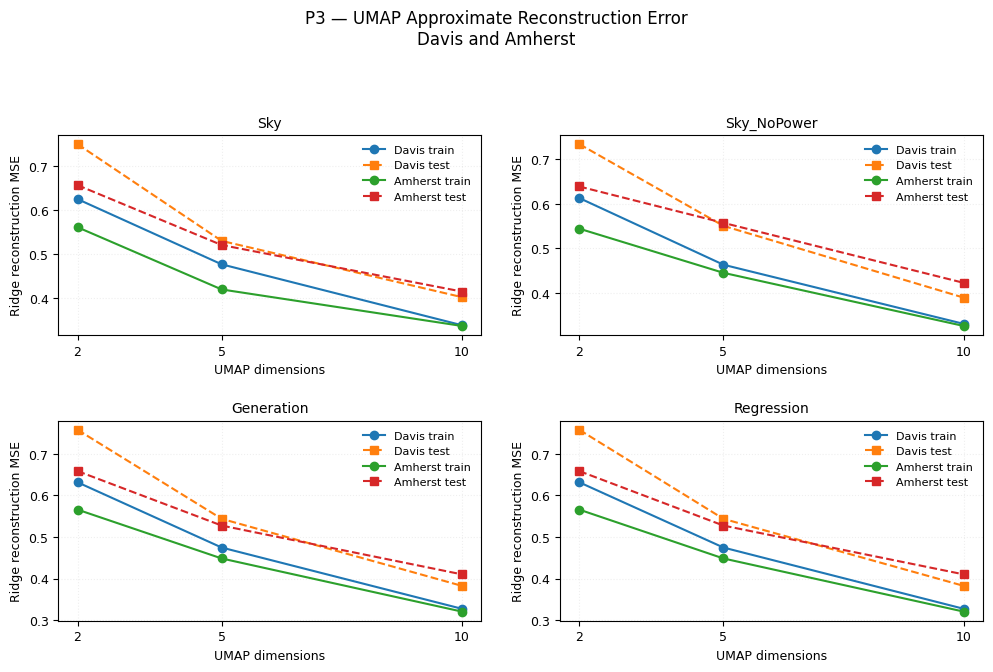

[PREVIEW] P3_Four_Methods_Reconstruction_Comparison.pdf


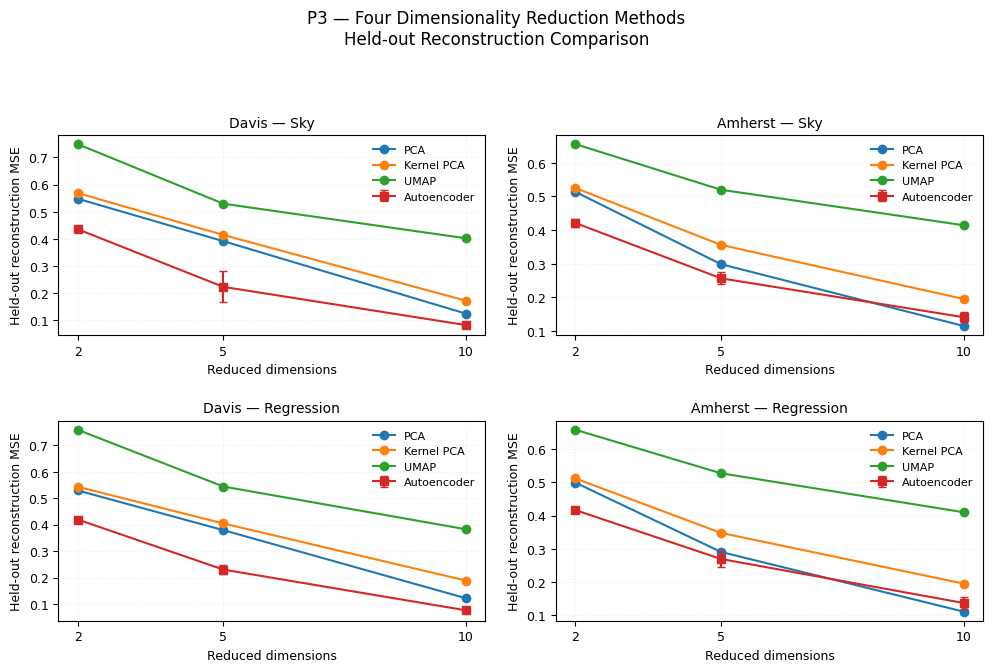


P3 — UMAP REPRESENTATION LEARNING COMPLETED

DAVIS AND AMHERST INTRINSIC RESULTS


,Dataset,Task,Reduced Dimensions,Fit Training Samples,Train Reconstruction MSE,Test Reconstruction MSE
0,Amherst_2018_2020,Generation,2,6000,0.5659,0.6586
1,Amherst_2018_2020,Generation,5,6000,0.4483,0.5275
2,Amherst_2018_2020,Generation,10,6000,0.3204,0.4100
3,Amherst_2018_2020,Regression,2,6000,0.5659,0.6586
4,Amherst_2018_2020,Regression,5,6000,0.4483,0.5275
5,Amherst_2018_2020,Regression,10,6000,0.3204,0.4100
6,Amherst_2018_2020,Sky,2,6000,0.5604,0.6558
7,Amherst_2018_2020,Sky,5,6000,0.4193,0.5200
8,Amherst_2018_2020,Sky,10,6000,0.3365,0.4145
9,Amherst_2018_2020,Sky_NoPower,2,6000,0.5438,0.6385



EXPERIMENT COUNTS
Unique UMAP fits    : 81
Representations     : 108
Saved UMAP models  : 81
Saved embeddings   : 108

SAVED OUTPUTS
Metrics  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/UMAP_Intrinsic_Metrics.csv
Models   : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models/UMAP
Features : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Embeddings/UMAP

Both UMAP figures are in preview mode.

UMAP was fitted using training features only.
Held-out test observations were transformed only.
No supervised targets were used to train UMAP.


In [7]:

# ============================================================
# P3 — Cell 8: UMAP Nonlinear Dimensionality Reduction
# ============================================================

import os
import sys
import json
import time
import shutil
import subprocess
from importlib.util import find_spec

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from IPython.display import display


# ------------------------------------------------------------
# 1. Ensure UMAP is available
# ------------------------------------------------------------

if find_spec("umap") is None:
    print("Installing umap-learn...")
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "umap-learn"
    ])

from umap import UMAP


# ------------------------------------------------------------
# 2. Configuration and output directories
# ------------------------------------------------------------

P3_UMAP_CONFIG = {
    "version": "P3_UMAP_v1",
    "dimensions": list(P3_DIMENSIONS),
    "n_neighbors": 25,
    "min_dist": 0.1,
    "metric": "euclidean",
    "fit_sample_cap": 6000,
    "n_epochs": 150,
    "random_state": 42,
    "transform_seed": 42,
    "decoder": "Ridge",
    "decoder_alpha": 1.0
}

P3_UMAP_CONFIG_ID = json.dumps(
    P3_UMAP_CONFIG,
    sort_keys=True
)

P3_UMAP_MODEL_DIR = P3_MODELS_DIR / "UMAP"
P3_UMAP_EMBEDDING_DIR = P3_EMBEDDINGS_DIR / "UMAP"
P3_UMAP_SUBSET_DIR = P3_MANIFESTS_DIR / "UMAP_Fit_Subsets"

P3_UMAP_METRICS_PATH = (
    P3_RESULTS_DIR / "UMAP_Intrinsic_Metrics.csv"
)

P3_UMAP_SUMMARY_PATH = (
    P3_RESULTS_DIR / "UMAP_Intrinsic_Summary.csv"
)

for folder in (
    P3_UMAP_MODEL_DIR,
    P3_UMAP_EMBEDDING_DIR,
    P3_UMAP_SUBSET_DIR
):
    folder.mkdir(parents=True, exist_ok=True)

# Generation and Regression share the same feature
# matrices and chronological row selections.
P3_UMAP_TRAIN_TASKS = (
    "Sky",
    "Sky_NoPower",
    "Regression"
)

P3_UMAP_EMBEDDINGS = {}

EXPECTED_UMAP_FITS = (
    len(P3_DATASETS)
    * len(P3_UMAP_TRAIN_TASKS)
    * len(P3_DIMENSIONS)
)

EXPECTED_UMAP_REPRESENTATIONS = (
    len(P3_DATASETS)
    * len(P3_TASK_FEATURES)
    * len(P3_DIMENSIONS)
)

assert EXPECTED_UMAP_FITS == 81
assert EXPECTED_UMAP_REPRESENTATIONS == 108


# ------------------------------------------------------------
# 3. Incremental saving and resumption
# ------------------------------------------------------------

def p3_umap_model_path(dataset, task, d):
    return P3_UMAP_MODEL_DIR / (
        f"{dataset}_{task}_d{d}.joblib"
    )


def p3_umap_embedding_path(dataset, task, d):
    return P3_UMAP_EMBEDDING_DIR / (
        f"{dataset}_{task}_d{d}.npz"
    )


def p3_umap_save_records(records):

    temporary = P3_UMAP_METRICS_PATH.with_suffix(
        ".tmp"
    )

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(
        temporary,
        P3_UMAP_METRICS_PATH
    )


def p3_umap_key(record):

    return (
        str(record["Dataset"]),
        str(record["Task"]),
        int(record["Reduced Dimensions"])
    )


if P3_UMAP_METRICS_PATH.is_file():

    umap_records = pd.read_csv(
        P3_UMAP_METRICS_PATH
    ).to_dict("records")

    for record in umap_records:
        assert record["Config ID"] == P3_UMAP_CONFIG_ID, (
            "Saved UMAP results use a different configuration."
        )

else:
    umap_records = []


# ------------------------------------------------------------
# 4. Train nonlinear UMAP representations
# ------------------------------------------------------------

print("P3 — UNSUPERVISED UMAP")
print("=" * 75)

print(f"Reduced dimensions    : {P3_DIMENSIONS}")
print(f"Neighbors             : {P3_UMAP_CONFIG['n_neighbors']}")
print(f"Minimum distance      : {P3_UMAP_CONFIG['min_dist']}")
print(f"Training sample cap   : {P3_UMAP_CONFIG['fit_sample_cap']}")
print(f"Random state          : {P3_UMAP_CONFIG['random_state']}")
print(f"Unique UMAP fits      : {EXPECTED_UMAP_FITS}")
print(f"Total representations : {EXPECTED_UMAP_REPRESENTATIONS}")
print("UMAP device           : CPU")

completed_fits = 0

for dataset_key in sorted(P3_PREPROCESSED):

    P3_UMAP_EMBEDDINGS[dataset_key] = {}

    for task in P3_UMAP_TRAIN_TASKS:

        P3_UMAP_EMBEDDINGS[
            dataset_key
        ][task] = {}

        prepared = P3_PREPROCESSED[
            dataset_key
        ][task]

        X_train = np.asarray(
            prepared["X_train"],
            dtype=np.float32
        )

        X_test = np.asarray(
            prepared["X_test"],
            dtype=np.float32
        )

        assert np.isfinite(X_train).all()
        assert np.isfinite(X_test).all()

        # Sample ONLY from chronological training rows.
        # Reuse the same sample for all dimensions.
        rng = np.random.default_rng(
            P3_UMAP_CONFIG["random_state"]
        )

        subset_size = min(
            len(X_train),
            P3_UMAP_CONFIG["fit_sample_cap"]
        )

        fit_positions = np.sort(
            rng.choice(
                len(X_train),
                size=subset_size,
                replace=False
            )
        )

        X_fit = X_train[fit_positions]

        subset_path = (
            P3_UMAP_SUBSET_DIR
            / f"{dataset_key}_{task}_positions.npz"
        )

        with open(
            subset_path.with_suffix(".tmp"),
            "wb"
        ) as file:

            np.savez_compressed(
                file,
                train_positions=fit_positions,
                original_train_rows=prepared[
                    "train_rows"
                ][fit_positions],
                seed=P3_UMAP_CONFIG["random_state"]
            )

        os.replace(
            subset_path.with_suffix(".tmp"),
            subset_path
        )

        for d in P3_DIMENSIONS:

            model_path = p3_umap_model_path(
                dataset_key, task, d
            )

            embedding_path = p3_umap_embedding_path(
                dataset_key, task, d
            )

            P3_UMAP_EMBEDDINGS[
                dataset_key
            ][task][d] = embedding_path

            key = (
                dataset_key,
                task,
                int(d)
            )

            previous = [
                record for record in umap_records
                if p3_umap_key(record) == key
            ]

            cached = (
                len(previous) == 1
                and model_path.is_file()
                and embedding_path.is_file()
            )

            if cached:

                completed_fits += 1

                print(
                    f"[CACHED {completed_fits:02d}/"
                    f"{EXPECTED_UMAP_FITS}] "
                    f"{dataset_key} | {task} | d={d}",
                    flush=True
                )

                continue

            start = time.perf_counter()

            # ------------------------------------------------
            # A. Fit UMAP using training features only
            # ------------------------------------------------

            reducer = UMAP(
                n_components=d,
                n_neighbors=P3_UMAP_CONFIG[
                    "n_neighbors"
                ],
                min_dist=P3_UMAP_CONFIG[
                    "min_dist"
                ],
                metric=P3_UMAP_CONFIG["metric"],
                random_state=P3_UMAP_CONFIG[
                    "random_state"
                ],
                transform_seed=P3_UMAP_CONFIG[
                    "transform_seed"
                ],
                n_epochs=P3_UMAP_CONFIG[
                    "n_epochs"
                ],
                n_jobs=1,
                low_memory=True,
                verbose=False
            )

            reducer.fit(X_fit)

            # ------------------------------------------------
            # B. Apply the learned mapping to full partitions
            # ------------------------------------------------

            Z_train = np.asarray(
                reducer.transform(X_train),
                dtype=np.float32
            )

            Z_test = np.asarray(
                reducer.transform(X_test),
                dtype=np.float32
            )

            assert Z_train.shape == (
                len(X_train), d
            )

            assert Z_test.shape == (
                len(X_test), d
            )

            assert np.isfinite(Z_train).all()
            assert np.isfinite(Z_test).all()

            # ------------------------------------------------
            # C. Fit a training-only Ridge pre-image decoder
            #
            # This measures approximate reconstruction
            # quality. It is NOT an exact UMAP inverse.
            # ------------------------------------------------

            decoder = Ridge(
                alpha=P3_UMAP_CONFIG[
                    "decoder_alpha"
                ]
            )

            decoder.fit(
                Z_train,
                X_train
            )

            reconstructed_train = (
                decoder.predict(Z_train)
            )

            reconstructed_test = (
                decoder.predict(Z_test)
            )

            train_mse = float(
                np.mean(
                    (
                        X_train.astype(np.float64)
                        - reconstructed_train
                    ) ** 2
                )
            )

            test_mse = float(
                np.mean(
                    (
                        X_test.astype(np.float64)
                        - reconstructed_test
                    ) ** 2
                )
            )

            assert np.isfinite(train_mse)
            assert np.isfinite(test_mse)

            # ------------------------------------------------
            # D. Save the fitted nonlinear reducer
            # ------------------------------------------------

            temporary_model = (
                model_path.with_suffix(".tmp")
            )

            joblib.dump(
                {
                    "reducer": reducer,
                    "decoder": decoder,
                    "config": P3_UMAP_CONFIG,
                    "fit_positions": fit_positions
                },
                temporary_model
            )

            os.replace(
                temporary_model,
                model_path
            )

            # ------------------------------------------------
            # E. Save transformed training and test features
            # ------------------------------------------------

            temporary_embedding = (
                embedding_path.with_suffix(".tmp")
            )

            with open(
                temporary_embedding,
                "wb"
            ) as file:

                np.savez_compressed(
                    file,
                    X_train=Z_train,
                    X_test=Z_test,
                    train_rows=prepared["train_rows"],
                    test_rows=prepared["test_rows"],
                    dimension=np.int64(d)
                )

            os.replace(
                temporary_embedding,
                embedding_path
            )

            # ------------------------------------------------
            # F. Save metrics immediately
            # ------------------------------------------------

            elapsed = time.perf_counter() - start

            umap_records = [
                record for record in umap_records
                if p3_umap_key(record) != key
            ]

            umap_records.append({
                "Dataset": dataset_key,
                "Task": task,
                "Method": "UMAP",
                "Original Dimensions": X_train.shape[1],
                "Reduced Dimensions": int(d),
                "Train Samples": len(X_train),
                "Test Samples": len(X_test),
                "Fit Training Samples": len(X_fit),
                "Train Reconstruction MSE": train_mse,
                "Test Reconstruction MSE": test_mse,
                "Training Time (s)": elapsed,
                "Decoder": "Ridge pre-image approximation",
                "Shared Representation": False,
                "Config ID": P3_UMAP_CONFIG_ID
            })

            p3_umap_save_records(umap_records)

            completed_fits += 1

            print(
                f"[{completed_fits:02d}/"
                f"{EXPECTED_UMAP_FITS}] "
                f"{dataset_key:24s} | "
                f"{task:12s} | d={d:2d} | "
                f"Train MSE={train_mse:.4f} | "
                f"Test MSE={test_mse:.4f} | "
                f"{elapsed:.1f}s",
                flush=True
            )


# ------------------------------------------------------------
# 5. Reuse Regression UMAP features for Generation
# ------------------------------------------------------------

for dataset_key in sorted(P3_PREPROCESSED):

    regression_data = P3_PREPROCESSED[
        dataset_key
    ]["Regression"]

    generation_data = P3_PREPROCESSED[
        dataset_key
    ]["Generation"]

    for field in (
        "X_train",
        "X_test",
        "train_rows",
        "test_rows"
    ):

        np.testing.assert_array_equal(
            regression_data[field],
            generation_data[field]
        )

    P3_UMAP_EMBEDDINGS[
        dataset_key
    ]["Generation"] = {}

    for d in P3_DIMENSIONS:

        source_path = p3_umap_embedding_path(
            dataset_key, "Regression", d
        )

        destination_path = p3_umap_embedding_path(
            dataset_key, "Generation", d
        )

        if not destination_path.is_file():

            temporary = destination_path.with_suffix(
                ".tmp"
            )

            shutil.copyfile(
                source_path,
                temporary
            )

            os.replace(
                temporary,
                destination_path
            )

        P3_UMAP_EMBEDDINGS[
            dataset_key
        ]["Generation"][d] = destination_path

        source_key = (
            dataset_key,
            "Regression",
            int(d)
        )

        destination_key = (
            dataset_key,
            "Generation",
            int(d)
        )

        source_record = next(
            record for record in umap_records
            if p3_umap_key(record) == source_key
        )

        copied_record = {
            **source_record,
            "Task": "Generation",
            "Shared Representation": True
        }

        umap_records = [
            record for record in umap_records
            if p3_umap_key(record) != destination_key
        ]

        umap_records.append(copied_record)

    p3_umap_save_records(umap_records)


# ------------------------------------------------------------
# 6. Verify saved results and representations
# ------------------------------------------------------------

P3_UMAP_METRICS = pd.read_csv(
    P3_UMAP_METRICS_PATH
)

assert len(P3_UMAP_METRICS) == (
    EXPECTED_UMAP_REPRESENTATIONS
)

assert not P3_UMAP_METRICS.duplicated(
    ["Dataset", "Task", "Reduced Dimensions"]
).any()

assert len(
    list(P3_UMAP_MODEL_DIR.glob("*.joblib"))
) == EXPECTED_UMAP_FITS

assert len(
    list(P3_UMAP_EMBEDDING_DIR.glob("*.npz"))
) == EXPECTED_UMAP_REPRESENTATIONS

assert np.isfinite(
    P3_UMAP_METRICS[
        [
            "Train Reconstruction MSE",
            "Test Reconstruction MSE"
        ]
    ].to_numpy(dtype=float)
).all()

assert (
    P3_UMAP_METRICS[
        "Train Reconstruction MSE"
    ] >= 0
).all()

assert (
    P3_UMAP_METRICS[
        "Test Reconstruction MSE"
    ] >= 0
).all()

P3_UMAP_METRICS.sort_values(
    [
        "Dataset",
        "Task",
        "Reduced Dimensions"
    ],
    inplace=True
)

P3_UMAP_METRICS.to_csv(
    P3_UMAP_METRICS_PATH,
    index=False
)

P3_UMAP_SUMMARY = P3_UMAP_METRICS.copy()

P3_UMAP_SUMMARY.to_csv(
    P3_UMAP_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 7. Figure helper
# ------------------------------------------------------------

def p3_finalize_umap_figure(fig, filename):

    fig.tight_layout(
        rect=(0, 0, 1, 0.92),
        h_pad=2.0,
        w_pad=1.8
    )

    if P3_SAVE_FINAL_FIGURES:

        fig.savefig(
            P3_FIGURES_DIR / filename,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {filename}")

    else:
        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 8. Figure 1: UMAP reconstruction error
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

for ax, task in zip(
    axes.ravel(),
    P3_TASK_FEATURES
):

    for city, dataset_key in (
        ("Davis", "Davis_2011_2016"),
        ("Amherst", "Amherst_2018_2020")
    ):

        subset = P3_UMAP_METRICS[
            (P3_UMAP_METRICS["Dataset"] == dataset_key)
            & (P3_UMAP_METRICS["Task"] == task)
        ].sort_values("Reduced Dimensions")

        ax.plot(
            subset["Reduced Dimensions"],
            subset["Train Reconstruction MSE"],
            marker="o",
            label=f"{city} train"
        )

        ax.plot(
            subset["Reduced Dimensions"],
            subset["Test Reconstruction MSE"],
            marker="s",
            linestyle="--",
            label=f"{city} test"
        )

    ax.set_title(task)
    ax.set_xlabel("UMAP dimensions")
    ax.set_ylabel("Ridge reconstruction MSE")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — UMAP Approximate Reconstruction Error\n"
    "Davis and Amherst",
    fontsize=12
)

p3_finalize_umap_figure(
    fig,
    "P3_UMAP_Reconstruction_MSE.pdf"
)


# ------------------------------------------------------------
# 9. Figure 2: Compare all four reduction methods
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 6.8)
)

plot_settings = (
    ("Davis", "Davis_2011_2016", "Sky"),
    ("Amherst", "Amherst_2018_2020", "Sky"),
    ("Davis", "Davis_2011_2016", "Regression"),
    ("Amherst", "Amherst_2018_2020", "Regression")
)

for ax, (city, dataset_key, task) in zip(
    axes.ravel(),
    plot_settings
):

    for method, results in (
        ("PCA", P3_PCA_METRICS),
        ("Kernel PCA", P3_KPCA_METRICS),
        ("UMAP", P3_UMAP_METRICS)
    ):

        subset = results[
            (results["Dataset"] == dataset_key)
            & (results["Task"] == task)
        ].sort_values("Reduced Dimensions")

        ax.plot(
            subset["Reduced Dimensions"],
            subset["Test Reconstruction MSE"],
            marker="o",
            label=method
        )

    ae_subset = P3_AE_SUMMARY[
        (P3_AE_SUMMARY["Dataset"] == dataset_key)
        & (P3_AE_SUMMARY["Task"] == task)
    ].sort_values("Reduced Dimensions")

    ax.errorbar(
        ae_subset["Reduced Dimensions"],
        ae_subset["Test_MSE_Mean"],
        yerr=ae_subset["Test_MSE_SD"],
        marker="s",
        capsize=3,
        label="Autoencoder"
    )

    ax.set_title(f"{city} — {task}")
    ax.set_xlabel("Reduced dimensions")
    ax.set_ylabel("Held-out reconstruction MSE")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.2, linestyle=":")
    ax.legend(frameon=False)

fig.suptitle(
    "P3 — Four Dimensionality Reduction Methods\n"
    "Held-out Reconstruction Comparison",
    fontsize=12
)

p3_finalize_umap_figure(
    fig,
    "P3_Four_Methods_Reconstruction_Comparison.pdf"
)


# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P3 — UMAP REPRESENTATION LEARNING COMPLETED")
print("=" * 75)

primary_results = P3_UMAP_METRICS[
    P3_UMAP_METRICS["Dataset"].isin(
        P3_PRIMARY_KEYS
    )
]

print("\nDAVIS AND AMHERST INTRINSIC RESULTS")

display(
    primary_results[
        [
            "Dataset",
            "Task",
            "Reduced Dimensions",
            "Fit Training Samples",
            "Train Reconstruction MSE",
            "Test Reconstruction MSE"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nEXPERIMENT COUNTS")
print(f"Unique UMAP fits    : {EXPECTED_UMAP_FITS}")
print(f"Representations     : {len(P3_UMAP_METRICS)}")
print(
    f"Saved UMAP models  : "
    f"{len(list(P3_UMAP_MODEL_DIR.glob('*.joblib')))}"
)
print(
    f"Saved embeddings   : "
    f"{len(list(P3_UMAP_EMBEDDING_DIR.glob('*.npz')))}"
)

print("\nSAVED OUTPUTS")
print(f"Metrics  : {P3_UMAP_METRICS_PATH}")
print(f"Models   : {P3_UMAP_MODEL_DIR}")
print(f"Features : {P3_UMAP_EMBEDDING_DIR}")

if P3_SAVE_FINAL_FIGURES:
    print("\nBoth UMAP figures were exported.")
else:
    print("\nBoth UMAP figures are in preview mode.")

print("\nUMAP was fitted using training features only.")
print("Held-out test observations were transformed only.")
print("No supervised targets were used to train UMAP.")


In [8]:

# ============================================================
# P3 — Cell 9: Original-Feature Supervised Baselines
# ============================================================

import os
import json
import time
import random
import joblib

import numpy as np
import pandas as pd
import torch

from torch import nn
from IPython.display import display

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from xgboost import XGBClassifier, XGBRegressor


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

P3_DOWNSTREAM_CONFIG = {
    "version": "P3_Downstream_v1",
    "seeds": list(P3_SEEDS),
    "mlp_classification_epochs": 45,
    "mlp_regression_epochs": 55,
    "mlp_batch_size": 512,
    "mlp_learning_rate": 0.001,
    "random_forest_trees": 160,
    "xgboost_trees": 200
}

P3_DOWNSTREAM_CONFIG_ID = json.dumps(
    P3_DOWNSTREAM_CONFIG,
    sort_keys=True
)

P3_RAW_MODEL_DIR = P3_MODELS_DIR / "Raw_Baselines"
P3_RAW_PREDICTION_DIR = P3_PREDICTIONS_DIR / "Raw_Baselines"

P3_RAW_METRICS_PATH = (
    P3_RESULTS_DIR / "Raw_Feature_Baseline_Metrics.csv"
)

P3_RAW_SUMMARY_PATH = (
    P3_RESULTS_DIR / "Raw_Feature_Baseline_Summary.csv"
)

for folder in (
    P3_RAW_MODEL_DIR,
    P3_RAW_PREDICTION_DIR
):
    folder.mkdir(parents=True, exist_ok=True)

P3_BASELINE_DATASETS = tuple(P3_PRIMARY_KEYS)
P3_BASELINE_TASKS = tuple(P3_TASK_FEATURES)

P3_ALL_CLASSIFICATION_TASKS = (
    "Sky",
    "Sky_NoPower",
    "Generation"
)


# ------------------------------------------------------------
# 2. Common scoring functions
# ------------------------------------------------------------

def p3_score_classification(y_true, y_pred):

    return {
        "Accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "Macro_F1": float(
            f1_score(
                y_true,
                y_pred,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )
        )
    }


def p3_score_regression(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    rmse = float(
        np.sqrt(mean_squared_error(y_true, y_pred))
    )

    mae = float(
        mean_absolute_error(y_true, y_pred)
    )

    # Test-target range is used for reporting only.
    # No model fitting or tuning uses this range.
    target_range = float(np.ptp(y_true))

    nrmse = (
        100.0 * rmse / target_range
        if target_range > 0
        else np.nan
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "nRMSE": nrmse,
        "R2": float(
            r2_score(y_true, y_pred)
        )
    }


# ------------------------------------------------------------
# 3. Shared classical model definitions
# ------------------------------------------------------------

def p3_create_downstream_model(task, model_name, seed):

    classification = (
        task in P3_ALL_CLASSIFICATION_TASKS
    )

    if classification:

        if model_name == "Logistic Regression":
            return LogisticRegression(
                C=1.0,
                max_iter=1500,
                random_state=seed
            )

        if model_name == "SVM (RBF)":
            return SVC(
                kernel="rbf",
                C=3.0,
                gamma="scale",
                cache_size=500
            )

        if model_name == "Random Forest":
            return RandomForestClassifier(
                n_estimators=P3_DOWNSTREAM_CONFIG[
                    "random_forest_trees"
                ],
                max_features="sqrt",
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=seed
            )

        if model_name == "XGBoost":
            return XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                n_estimators=P3_DOWNSTREAM_CONFIG[
                    "xgboost_trees"
                ],
                max_depth=4,
                learning_rate=0.06,
                subsample=0.9,
                colsample_bytree=0.9,
                tree_method="hist",
                eval_metric="mlogloss",
                n_jobs=4,
                random_state=seed
            )

    else:

        if model_name == "Ridge":
            return Ridge(
                alpha=10.0
            )

        if model_name == "SVR (RBF)":
            return TransformedTargetRegressor(
                regressor=SVR(
                    kernel="rbf",
                    C=15.0,
                    epsilon=0.1,
                    gamma="scale",
                    cache_size=500
                ),
                transformer=StandardScaler()
            )

        if model_name == "Random Forest":
            return RandomForestRegressor(
                n_estimators=P3_DOWNSTREAM_CONFIG[
                    "random_forest_trees"
                ],
                max_features=0.8,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=seed
            )

        if model_name == "XGBoost":
            return XGBRegressor(
                objective="reg:squarederror",
                n_estimators=P3_DOWNSTREAM_CONFIG[
                    "xgboost_trees"
                ],
                max_depth=4,
                learning_rate=0.06,
                subsample=0.9,
                colsample_bytree=0.9,
                tree_method="hist",
                n_jobs=4,
                random_state=seed
            )

    raise ValueError(
        f"Unsupported task/model combination: "
        f"{task}, {model_name}"
    )


# ------------------------------------------------------------
# 4. Shared PyTorch MLP
# ------------------------------------------------------------

class P3DownstreamMLP(nn.Module):

    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, x):
        return self.network(x)


def p3_fit_predict_mlp(
    X_train,
    y_train,
    X_test,
    task,
    seed
):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    classification = (
        task in P3_ALL_CLASSIFICATION_TASKS
    )

    X_train = np.asarray(
        X_train,
        dtype=np.float32
    )

    X_test = np.asarray(
        X_test,
        dtype=np.float32
    )

    if classification:
        y_train = np.asarray(
            y_train,
            dtype=np.int64
        )
        output_dim = 3
        epochs = P3_DOWNSTREAM_CONFIG[
            "mlp_classification_epochs"
        ]
        target_mean = None
        target_std = None

    else:
        y_train = np.asarray(
            y_train,
            dtype=np.float32
        )
        output_dim = 1
        epochs = P3_DOWNSTREAM_CONFIG[
            "mlp_regression_epochs"
        ]

        # Regression-target standardization uses
        # training targets exclusively.
        target_mean = float(y_train.mean())
        target_std = float(y_train.std())

        if target_std < 1e-8:
            target_std = 1.0

        y_train = (
            (y_train - target_mean) / target_std
        )

    model = P3DownstreamMLP(
        X_train.shape[1],
        output_dim
    ).to(P3_DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P3_DOWNSTREAM_CONFIG[
            "mlp_learning_rate"
        ],
        weight_decay=1e-4
    )

    X_tensor = torch.as_tensor(
        X_train,
        device=P3_DEVICE
    )

    if classification:

        y_tensor = torch.as_tensor(
            y_train,
            dtype=torch.long,
            device=P3_DEVICE
        )

        counts = np.bincount(
            y_train,
            minlength=3
        )

        assert np.all(counts > 0)

        weights = (
            len(y_train) / (3.0 * counts)
        ).astype(np.float32)

        criterion = nn.CrossEntropyLoss(
            weight=torch.as_tensor(
                weights,
                device=P3_DEVICE
            )
        )

    else:

        y_tensor = torch.as_tensor(
            y_train.reshape(-1, 1),
            dtype=torch.float32,
            device=P3_DEVICE
        )

        criterion = nn.MSELoss()

    shuffle_generator = (
        torch.Generator().manual_seed(seed)
    )

    for epoch in range(epochs):

        model.train()

        permutation = torch.randperm(
            len(X_train),
            generator=shuffle_generator
        )

        for positions in permutation.split(
            P3_DOWNSTREAM_CONFIG[
                "mlp_batch_size"
            ]
        ):

            positions = positions.to(P3_DEVICE)

            batch_x = X_tensor[positions]
            batch_y = y_tensor[positions]

            optimizer.zero_grad(
                set_to_none=True
            )

            output = model(batch_x)

            loss = criterion(
                output,
                batch_y
            )

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

    # --------------------------------------------------------
    # Predict unseen test observations
    # --------------------------------------------------------

    model.eval()

    predictions = []

    with torch.no_grad():

        for start in range(0, len(X_test), 2048):

            batch = torch.as_tensor(
                X_test[start:start + 2048],
                device=P3_DEVICE
            )

            output = model(batch)

            if classification:

                pred = (
                    output.argmax(dim=1)
                    .cpu()
                    .numpy()
                )

            else:

                pred = (
                    output.squeeze(1)
                    .cpu()
                    .numpy()
                )

            predictions.append(pred)

    y_pred = np.concatenate(predictions)

    if not classification:

        y_pred = (
            y_pred * target_std + target_mean
        )

    checkpoint = {
        "state_dict": {
            name: tensor.detach().cpu().clone()
            for name, tensor in model.state_dict().items()
        },
        "input_dim": int(X_train.shape[1]),
        "output_dim": int(output_dim),
        "task": task,
        "seed": int(seed),
        "target_mean": target_mean,
        "target_std": target_std,
        "config": P3_DOWNSTREAM_CONFIG
    }

    return y_pred, checkpoint


# ------------------------------------------------------------
# 5. Reusable training and prediction function
# ------------------------------------------------------------

def p3_train_predict_downstream(
    X_train,
    y_train,
    X_test,
    task,
    model_name,
    seed
):
    """
    Train one supervised model using its permitted
    training features and labels.

    This function will also be used in subsequent cells
    to evaluate PCA, Kernel PCA, AE, and UMAP fairly.
    """

    X_train = np.asarray(
        X_train,
        dtype=np.float32
    )

    X_test = np.asarray(
        X_test,
        dtype=np.float32
    )

    assert X_train.shape[1] == X_test.shape[1]
    assert len(X_train) == len(y_train)
    assert np.isfinite(X_train).all()
    assert np.isfinite(X_test).all()

    if model_name == "MLP (PyTorch)":

        predictions, checkpoint = (
            p3_fit_predict_mlp(
                X_train,
                y_train,
                X_test,
                task,
                seed
            )
        )

        return (
            predictions,
            checkpoint,
            "pytorch"
        )

    model = p3_create_downstream_model(
        task,
        model_name,
        seed
    )

    if task in P3_ALL_CLASSIFICATION_TASKS:

        # Balanced training weights compensate for
        # the unequal sky-condition class frequencies.
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )

    else:

        model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    return predictions, model, "sklearn"


# ------------------------------------------------------------
# 6. Incremental result-saving helpers
# ------------------------------------------------------------

def p3_raw_model_path(dataset, task, model_name, seed):

    model_slug = (
        model_name.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    extension = (
        ".pt"
        if model_name == "MLP (PyTorch)"
        else ".joblib"
    )

    return P3_RAW_MODEL_DIR / (
        f"{dataset}_{task}_{model_slug}_seed{seed}"
        f"{extension}"
    )


def p3_raw_prediction_path(
    dataset,
    task,
    model_name,
    seed
):

    model_slug = (
        model_name.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    return P3_RAW_PREDICTION_DIR / (
        f"{dataset}_{task}_{model_slug}_seed{seed}.npz"
    )


def p3_raw_record_key(record):

    return (
        str(record["Dataset"]),
        str(record["Task"]),
        str(record["Model"]),
        int(record["Seed"])
    )


def p3_raw_save_results(records):

    temporary = (
        P3_RAW_METRICS_PATH.with_suffix(".tmp")
    )

    pd.DataFrame(records).to_csv(
        temporary,
        index=False
    )

    os.replace(
        temporary,
        P3_RAW_METRICS_PATH
    )


# ------------------------------------------------------------
# 7. Resume existing baseline evaluations
# ------------------------------------------------------------

if P3_RAW_METRICS_PATH.is_file():

    raw_records = pd.read_csv(
        P3_RAW_METRICS_PATH
    ).to_dict("records")

    for record in raw_records:

        assert (
            record["Config ID"]
            == P3_DOWNSTREAM_CONFIG_ID
        ), "Existing baselines use a different configuration."

else:

    raw_records = []


expected_evaluations = (
    len(P3_BASELINE_DATASETS)
    * len(P3_BASELINE_TASKS)
    * 5
    * len(P3_SEEDS)
)

assert expected_evaluations == 120

finished = 0

print("P3 — ORIGINAL-FEATURE SUPERVISED BASELINES")
print("=" * 75)

print(f"Datasets             : {P3_BASELINE_DATASETS}")
print(f"Tasks                : {P3_BASELINE_TASKS}")
print(f"Seeds                : {P3_SEEDS}")
print(f"Compute device       : {P3_DEVICE}")
print(f"Expected evaluations : {expected_evaluations}")
print(f"Previously saved     : {len(raw_records)}")


# ------------------------------------------------------------
# 8. Train all models on the original encoded features
# ------------------------------------------------------------

for dataset_key in P3_BASELINE_DATASETS:

    for task in P3_BASELINE_TASKS:

        prepared = P3_PREPROCESSED[
            dataset_key
        ][task]

        X_train = prepared["X_train"]
        X_test = prepared["X_test"]
        y_train = prepared["y_train"]
        y_test = prepared["y_test"]

        if task in P3_ALL_CLASSIFICATION_TASKS:

            models = P3_CLASSIFICATION_MODELS

        else:

            models = P3_REGRESSION_MODELS

        row_ids = P3_DATASETS[
            dataset_key
        ]["tasks"][task]["test_row_index"]

        for model_name in models:

            for seed in P3_SEEDS:

                key = (
                    dataset_key,
                    task,
                    model_name,
                    int(seed)
                )

                model_path = p3_raw_model_path(
                    dataset_key,
                    task,
                    model_name,
                    seed
                )

                prediction_path = (
                    p3_raw_prediction_path(
                        dataset_key,
                        task,
                        model_name,
                        seed
                    )
                )

                previous_records = [
                    record for record in raw_records
                    if p3_raw_record_key(record) == key
                ]

                cached = (
                    len(previous_records) == 1
                    and model_path.is_file()
                    and prediction_path.is_file()
                )

                if cached:

                    finished += 1

                    print(
                        f"[CACHED {finished:03d}/"
                        f"{expected_evaluations}] "
                        f"{dataset_key} | {task} | "
                        f"{model_name} | seed={seed}",
                        flush=True
                    )

                    continue

                start = time.perf_counter()

                (
                    y_pred,
                    trained_model,
                    model_type
                ) = p3_train_predict_downstream(
                    X_train,
                    y_train,
                    X_test,
                    task,
                    model_name,
                    seed
                )

                if task in P3_ALL_CLASSIFICATION_TASKS:

                    y_pred = np.asarray(
                        y_pred,
                        dtype=np.int64
                    )

                    scores = p3_score_classification(
                        y_test,
                        y_pred
                    )

                else:

                    y_pred = np.asarray(
                        y_pred,
                        dtype=np.float64
                    )

                    scores = p3_score_regression(
                        y_test,
                        y_pred
                    )

                assert len(y_pred) == len(y_test)
                assert np.isfinite(y_pred).all()

                # --------------------------------------------
                # Save trained model
                # --------------------------------------------

                temporary_model = (
                    model_path.with_suffix(".tmp")
                )

                if model_type == "pytorch":

                    torch.save(
                        trained_model,
                        temporary_model
                    )

                else:

                    joblib.dump(
                        trained_model,
                        temporary_model
                    )

                os.replace(
                    temporary_model,
                    model_path
                )

                # --------------------------------------------
                # Save predictions and test row alignment
                # --------------------------------------------

                temporary_prediction = (
                    prediction_path.with_suffix(".tmp")
                )

                with open(
                    temporary_prediction,
                    "wb"
                ) as file:

                    np.savez_compressed(
                        file,
                        row_index=row_ids,
                        y_true=y_test,
                        y_pred=y_pred
                    )

                os.replace(
                    temporary_prediction,
                    prediction_path
                )

                elapsed = time.perf_counter() - start

                record = {
                    "Dataset": dataset_key,
                    "Task": task,
                    "Representation": "Original Features",
                    "Model": model_name,
                    "Seed": int(seed),
                    "Input Dimensions": int(
                        X_train.shape[1]
                    ),
                    "Train Samples": len(y_train),
                    "Test Samples": len(y_test),
                    "Training and Evaluation Time (s)": (
                        elapsed
                    ),
                    "Config ID": P3_DOWNSTREAM_CONFIG_ID,
                    **scores
                }

                raw_records = [
                    row for row in raw_records
                    if p3_raw_record_key(row) != key
                ]

                raw_records.append(record)

                p3_raw_save_results(raw_records)

                finished += 1

                main_metric = (
                    f"Balanced Accuracy="
                    f"{scores['Balanced_Accuracy']:.4f}"
                    if task in P3_ALL_CLASSIFICATION_TASKS
                    else
                    f"RMSE={scores['RMSE']:.3f} kW"
                )

                print(
                    f"[{finished:03d}/{expected_evaluations}] "
                    f"{dataset_key:20s} | "
                    f"{task:12s} | "
                    f"{model_name:20s} | "
                    f"seed={seed:4d} | "
                    f"{main_metric}",
                    flush=True
                )


# ------------------------------------------------------------
# 9. Validate the complete baseline inventory
# ------------------------------------------------------------

P3_RAW_RESULTS = pd.read_csv(
    P3_RAW_METRICS_PATH
)

assert len(P3_RAW_RESULTS) == expected_evaluations

assert not P3_RAW_RESULTS.duplicated(
    ["Dataset", "Task", "Model", "Seed"]
).any()

assert len(
    list(P3_RAW_PREDICTION_DIR.glob("*.npz"))
) == expected_evaluations

assert len(
    list(P3_RAW_MODEL_DIR.glob("*.pt"))
) == 24

assert len(
    list(P3_RAW_MODEL_DIR.glob("*.joblib"))
) == 96

# Every configuration must contain all three seeds.
seed_counts = P3_RAW_RESULTS.groupby(
    ["Dataset", "Task", "Model"]
)["Seed"].nunique()

assert (seed_counts == 3).all()


# ------------------------------------------------------------
# 10. Build three-seed summaries
# ------------------------------------------------------------

summary_rows = []

for (
    dataset_key,
    task,
    model_name
), group in P3_RAW_RESULTS.groupby(
    ["Dataset", "Task", "Model"]
):

    record = {
        "Dataset": dataset_key,
        "Task": task,
        "Model": model_name,
        "Representation": "Original Features",
        "Runs": len(group)
    }

    if task in P3_ALL_CLASSIFICATION_TASKS:

        metrics = (
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1"
        )

    else:

        metrics = (
            "RMSE",
            "MAE",
            "nRMSE",
            "R2"
        )

    for metric in metrics:

        values = group[metric].to_numpy(
            dtype=float
        )

        record[f"{metric}_Mean"] = float(
            values.mean()
        )

        record[f"{metric}_SD"] = float(
            values.std(ddof=1)
        )

    summary_rows.append(record)


P3_RAW_SUMMARY = pd.DataFrame(
    summary_rows
)

assert len(P3_RAW_SUMMARY) == 40

P3_RAW_SUMMARY.to_csv(
    P3_RAW_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 11. Display classification results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("P3 — ORIGINAL-FEATURE BASELINES COMPLETED")
print("=" * 75)

print("\nCLASSIFICATION — THREE-SEED SUMMARY")

classification_summary = P3_RAW_SUMMARY[
    P3_RAW_SUMMARY["Task"].isin(
        P3_ALL_CLASSIFICATION_TASKS
    )
].copy()

display(
    classification_summary[
        [
            "Dataset",
            "Task",
            "Model",
            "Balanced_Accuracy_Mean",
            "Balanced_Accuracy_SD",
            "Macro_F1_Mean",
            "Accuracy_Mean"
        ]
    ].sort_values(
        ["Dataset", "Task", "Balanced_Accuracy_Mean"],
        ascending=[True, True, False]
    ).round(4).reset_index(drop=True)
)


# ------------------------------------------------------------
# 12. Display regression results
# ------------------------------------------------------------

print("\nREGRESSION — THREE-SEED SUMMARY")

regression_summary = P3_RAW_SUMMARY[
    P3_RAW_SUMMARY["Task"] == "Regression"
].copy()

display(
    regression_summary[
        [
            "Dataset",
            "Model",
            "RMSE_Mean",
            "RMSE_SD",
            "MAE_Mean",
            "nRMSE_Mean",
            "R2_Mean"
        ]
    ].sort_values(
        ["Dataset", "RMSE_Mean"]
    ).round(4).reset_index(drop=True)
)


# ------------------------------------------------------------
# 13. Final verification
# ------------------------------------------------------------

print("\nVERIFICATION")
print(f"Model evaluations  : {len(P3_RAW_RESULTS)}")
print(f"Three-seed summaries: {len(P3_RAW_SUMMARY)}")

print(
    f"Saved predictions  : "
    f"{len(list(P3_RAW_PREDICTION_DIR.glob('*.npz')))}"
)

print(
    f"Saved models       : "
    f"{len(list(P3_RAW_MODEL_DIR.iterdir()))}"
)

print("\nSAVED FILES")
print(f"Metrics     : {P3_RAW_METRICS_PATH}")
print(f"Summary     : {P3_RAW_SUMMARY_PATH}")
print(f"Predictions : {P3_RAW_PREDICTION_DIR}")
print(f"Models      : {P3_RAW_MODEL_DIR}")

print("\nAll baseline evaluations completed.")
print("No dimensionality reduction models were refitted.")
print("All supervised models used training labels only.")
print("Held-out test observations were used for evaluation.")


P3 — ORIGINAL-FEATURE SUPERVISED BASELINES
Datasets             : ('Davis_2011_2016', 'Amherst_2018_2020')
Tasks                : ('Sky', 'Sky_NoPower', 'Generation', 'Regression')
Seeds                : (42, 123, 2026)
Compute device       : cuda
Expected evaluations : 120
Previously saved     : 0
[001/120] Davis_2011_2016      | Sky          | Logistic Regression  | seed=  42 | Balanced Accuracy=0.9844
[002/120] Davis_2011_2016      | Sky          | Logistic Regression  | seed= 123 | Balanced Accuracy=0.9844
[003/120] Davis_2011_2016      | Sky          | Logistic Regression  | seed=2026 | Balanced Accuracy=0.9844
[004/120] Davis_2011_2016      | Sky          | SVM (RBF)            | seed=  42 | Balanced Accuracy=0.9752
[005/120] Davis_2011_2016      | Sky          | SVM (RBF)            | seed= 123 | Balanced Accuracy=0.9752
[006/120] Davis_2011_2016      | Sky          | SVM (RBF)            | seed=2026 | Balanced Accuracy=0.9752
[007/120] Davis_2011_2016      | Sky          | Rand

,Dataset,Task,Model,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,Macro_F1_Mean,Accuracy_Mean
0,Amherst_2018_2020,Generation,Random Forest,0.7606,0.0009,0.7592,0.7544
1,Amherst_2018_2020,Generation,XGBoost,0.7585,0.0022,0.7571,0.7529
2,Amherst_2018_2020,Generation,MLP (PyTorch),0.7448,0.0079,0.7459,0.7403
3,Amherst_2018_2020,Generation,Logistic Regression,0.7433,0.0000,0.7427,0.7384
4,Amherst_2018_2020,Generation,SVM (RBF),0.7369,0.0000,0.7366,0.7309
5,Amherst_2018_2020,Sky,XGBoost,0.9898,0.0001,0.9890,0.9904
6,Amherst_2018_2020,Sky,Logistic Regression,0.9851,0.0000,0.9836,0.9855
7,Amherst_2018_2020,Sky,Random Forest,0.9833,0.0002,0.9805,0.9824
8,Amherst_2018_2020,Sky,MLP (PyTorch),0.9777,0.0055,0.9776,0.9808
9,Amherst_2018_2020,Sky,SVM (RBF),0.9636,0.0000,0.9620,0.9676



REGRESSION — THREE-SEED SUMMARY


,Dataset,Model,RMSE_Mean,RMSE_SD,MAE_Mean,nRMSE_Mean,R2_Mean
0,Amherst_2018_2020,XGBoost,19.9743,0.0807,13.5031,15.7030,0.7312
1,Amherst_2018_2020,Random Forest,20.1658,0.0468,13.5598,15.8537,0.7260
2,Amherst_2018_2020,MLP (PyTorch),20.7141,0.0797,14.5328,16.2847,0.7109
3,Amherst_2018_2020,Ridge,20.7251,0.0000,14.6055,16.2933,0.7106
4,Amherst_2018_2020,SVR (RBF),27.0706,0.0000,20.7096,21.2819,0.5062
5,Davis_2011_2016,MLP (PyTorch),14.9268,0.1046,8.7095,5.9050,0.9543
6,Davis_2011_2016,XGBoost,14.9277,0.0508,8.1711,5.9053,0.9543
7,Davis_2011_2016,Random Forest,15.2194,0.0239,7.8845,6.0207,0.9525
8,Davis_2011_2016,Ridge,16.9308,0.0000,9.7667,6.6977,0.9412
9,Davis_2011_2016,SVR (RBF),17.3600,0.0000,11.4256,6.8675,0.9382



VERIFICATION
Model evaluations  : 120
Three-seed summaries: 40
Saved predictions  : 120
Saved models       : 120

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Raw_Feature_Baseline_Metrics.csv
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Raw_Feature_Baseline_Summary.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Predictions/Raw_Baselines
Models      : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Models/Raw_Baselines

All baseline evaluations completed.
No dimensionality reduction models were refitted.
All supervised models used training labels only.
Held-out test observations were used for evaluation.


In [9]:

# ============================================================
# P3 — Cell 10: Sky-Condition Proxy Leakage Audit
# ============================================================

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

audit_records = []

for dataset_key in P3_PRIMARY_KEYS:

    dataset = P3_DATASETS[dataset_key]

    sky_task = dataset["tasks"]["Sky_NoPower"]

    # Exact test rows used by the Sky-NoPower classifier.
    test_positions = sky_task["test_rows"]

    df = dataset["data"].iloc[
        test_positions
    ].copy()

    y_true = np.asarray(
        sky_task["y_test"],
        dtype=int
    )

    # --------------------------------------------------------
    # 1. Reconstruct GHI from its physical components
    # --------------------------------------------------------

    zenith_radians = np.deg2rad(
        df["Solar Zenith Angle"].to_numpy(
            dtype=float
        )
    )

    cosine_zenith = np.clip(
        np.cos(zenith_radians),
        0.0,
        None
    )

    ghi_proxy = (
        df["DHI"].to_numpy(dtype=float)
        + df["DNI"].to_numpy(dtype=float)
        * cosine_zenith
    )

    clearsky_ghi_proxy = (
        df["Clearsky DHI"].to_numpy(dtype=float)
        + df["Clearsky DNI"].to_numpy(dtype=float)
        * cosine_zenith
    )

    # --------------------------------------------------------
    # 2. Reconstruct the clear-sky index
    # --------------------------------------------------------

    valid_proxy = (
        np.isfinite(ghi_proxy)
        & np.isfinite(clearsky_ghi_proxy)
        & (clearsky_ghi_proxy > 0)
    )

    proxy_csi = np.full(
        len(df),
        np.nan,
        dtype=float
    )

    np.divide(
        ghi_proxy,
        clearsky_ghi_proxy,
        out=proxy_csi,
        where=valid_proxy
    )

    valid_proxy &= np.isfinite(proxy_csi)

    assert valid_proxy.sum() > 0

    proxy_labels = np.full(
        len(df),
        -1,
        dtype=int
    )

    proxy_labels[valid_proxy] = np.digitize(
        proxy_csi[valid_proxy],
        bins=P3_SKY_THRESHOLDS
    )

    # --------------------------------------------------------
    # 3. Compare with actual held-out sky labels
    # --------------------------------------------------------

    actual_ghi = df["GHI"].to_numpy(
        dtype=float
    )

    actual_clearsky_ghi = df[
        "Clearsky GHI"
    ].to_numpy(dtype=float)

    covered_truth = y_true[valid_proxy]

    covered_predictions = (
        proxy_labels[valid_proxy]
    )

    record = {
        "Dataset": dataset_key,
        "Test Samples": len(df),
        "Covered Samples": int(
            valid_proxy.sum()
        ),
        "Coverage (%)": float(
            100 * valid_proxy.mean()
        ),
        "Reconstructed GHI MAE": float(
            np.mean(
                np.abs(
                    actual_ghi[valid_proxy]
                    - ghi_proxy[valid_proxy]
                )
            )
        ),
        "Reconstructed Clearsky GHI MAE": float(
            np.mean(
                np.abs(
                    actual_clearsky_ghi[valid_proxy]
                    - clearsky_ghi_proxy[valid_proxy]
                )
            )
        ),
        "Proxy Sky Accuracy": float(
            accuracy_score(
                covered_truth,
                covered_predictions
            )
        ),
        "Proxy Sky Balanced Accuracy": float(
            balanced_accuracy_score(
                covered_truth,
                covered_predictions
            )
        ),
        "Proxy Sky Macro F1": float(
            f1_score(
                covered_truth,
                covered_predictions,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )
        )
    }

    audit_records.append(record)


# ------------------------------------------------------------
# 4. Save the audit
# ------------------------------------------------------------

P3_SKY_LEAKAGE_AUDIT = pd.DataFrame(
    audit_records
)

audit_path = (
    P3_RESULTS_DIR
    / "P3_Sky_Proxy_Leakage_Audit.csv"
)

P3_SKY_LEAKAGE_AUDIT.to_csv(
    audit_path,
    index=False
)


# ------------------------------------------------------------
# 5. Compare physical proxies with the learned baselines
# ------------------------------------------------------------

xgboost_baselines = P3_RAW_SUMMARY[
    (P3_RAW_SUMMARY["Task"] == "Sky_NoPower")
    & (P3_RAW_SUMMARY["Model"] == "XGBoost")
][
    [
        "Dataset",
        "Balanced_Accuracy_Mean"
    ]
].rename(
    columns={
        "Balanced_Accuracy_Mean":
        "XGBoost Balanced Accuracy"
    }
)

comparison = P3_SKY_LEAKAGE_AUDIT.merge(
    xgboost_baselines,
    on="Dataset",
    how="left",
    validate="one_to_one"
)


print("=" * 75)
print("P3 — SKY FEATURE-LEAKAGE DIAGNOSTIC")
print("=" * 75)

print(
    "\nPhysical reconstruction uses only "
    "the features available to Sky_NoPower."
)

print(
    "No supervised models or dimensionality "
    "reducers were trained."
)

display(
    comparison.round(5)
)

print("\nINTERPRETATION")

for _, row in comparison.iterrows():

    print(f"\n{row['Dataset']}")

    print(
        f"  Coverage: "
        f"{row['Coverage (%)']:.2f}%"
    )

    print(
        f"  Physical-proxy balanced accuracy: "
        f"{row['Proxy Sky Balanced Accuracy']:.4f}"
    )

    print(
        f"  Raw XGBoost balanced accuracy:     "
        f"{row['XGBoost Balanced Accuracy']:.4f}"
    )

    if row["Proxy Sky Balanced Accuracy"] >= 0.95:

        print(
            "  FINDING: Sky labels can be reconstructed "
            "with very high accuracy from the "
            "remaining irradiance features."
        )

    else:

        print(
            "  FINDING: Direct physical reconstruction "
            "does not fully explain the learned "
            "classifier's performance."
        )

print("\nSaved audit:", audit_path)

print("\nExisting results and model files remain unchanged.")


P3 — SKY FEATURE-LEAKAGE DIAGNOSTIC

Physical reconstruction uses only the features available to Sky_NoPower.
No supervised models or dimensionality reducers were trained.


,Dataset,Test Samples,Covered Samples,Coverage (%),Reconstructed GHI MAE,Reconstructed Clearsky GHI MAE,Proxy Sky Accuracy,Proxy Sky Balanced Accuracy,Proxy Sky Macro F1,XGBoost Balanced Accuracy
0,Davis_2011_2016,4823,4823,100.0,0.41608,0.44185,0.99896,0.99869,0.99856,0.99198
1,Amherst_2018_2020,2408,2408,100.0,0.30699,0.36250,0.99792,0.99777,0.99760,0.98962



INTERPRETATION

Davis_2011_2016
  Coverage: 100.00%
  Physical-proxy balanced accuracy: 0.9987
  Raw XGBoost balanced accuracy:     0.9920
  FINDING: Sky labels can be reconstructed with very high accuracy from the remaining irradiance features.

Amherst_2018_2020
  Coverage: 100.00%
  Physical-proxy balanced accuracy: 0.9978
  Raw XGBoost balanced accuracy:     0.9896
  FINDING: Sky labels can be reconstructed with very high accuracy from the remaining irradiance features.

Saved audit: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/P3_Sky_Proxy_Leakage_Audit.csv

Existing results and model files remain unchanged.


In [10]:

# ============================================================
# P3 — Cell 11: Downstream Models on Reduced Features
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd

from IPython.display import display


# ------------------------------------------------------------
# 1. Load previously saved reduced representations
# ------------------------------------------------------------

P3_REDUCED_FOLDERS = {
    "PCA": "PCA",
    "KPCA": "Kernel_PCA",
    "AE": "Autoencoder"
}


def p3_load_reduced_features(method, dataset, task, d, seed):
    """
    Load previously learned unsupervised representations.

    PCA and Kernel PCA are deterministic in this project.
    Autoencoder representations use their matching seed.
    """

    filename = f"{dataset}_{task}_d{d}"

    if method == "AE":
        filename += f"_seed{seed}"

    path = (
        P3_EMBEDDINGS_DIR
        / P3_REDUCED_FOLDERS[method]
        / f"{filename}.npz"
    )

    if not path.is_file():
        raise FileNotFoundError(path)

    with np.load(path) as saved:

        X_train = saved["X_train"].copy()
        X_test = saved["X_test"].copy()

        train_rows = saved["train_rows"]
        test_rows = saved["test_rows"]

    original = P3_PREPROCESSED[dataset][task]

    # Ensure identical samples and chronological splits.
    np.testing.assert_array_equal(
        train_rows, original["train_rows"]
    )

    np.testing.assert_array_equal(
        test_rows, original["test_rows"]
    )

    assert X_train.shape == (
        len(original["y_train"]), d
    )

    assert X_test.shape == (
        len(original["y_test"]), d
    )

    assert np.isfinite(X_train).all()
    assert np.isfinite(X_test).all()

    return X_train, X_test


# ------------------------------------------------------------
# 2. Reusable downstream experiment
# ------------------------------------------------------------

def p3_run_reduced_downstream(method):

    if method not in P3_REDUCED_FOLDERS:
        raise ValueError(f"Unknown method: {method}")

    metrics_path = (
        P3_RESULTS_DIR
        / f"{method}_Downstream_Metrics.csv"
    )

    summary_path = (
        P3_RESULTS_DIR
        / f"{method}_Downstream_Summary.csv"
    )

    comparison_path = (
        P3_RESULTS_DIR
        / f"{method}_vs_Raw_Summary.csv"
    )

    prediction_dir = (
        P3_PREDICTIONS_DIR / method
    )

    prediction_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Resume previously completed evaluations.
    if metrics_path.is_file():

        records = pd.read_csv(
            metrics_path
        ).to_dict("records")

        assert all(
            record["Config ID"]
            == P3_DOWNSTREAM_CONFIG_ID
            for record in records
        )

    else:
        records = []

    expected_runs = (
        len(P3_BASELINE_DATASETS)
        * len(P3_BASELINE_TASKS)
        * len(P3_DIMENSIONS)
        * 5
        * len(P3_SEEDS)
    )

    assert expected_runs == 360

    completed = 0

    print("=" * 75)
    print(f"P3 — {method} DOWNSTREAM EVALUATION")
    print("=" * 75)
    print(f"Datasets          : {P3_BASELINE_DATASETS}")
    print(f"Dimensions        : {P3_DIMENSIONS}")
    print(f"Seeds             : {P3_SEEDS}")
    print(f"Expected runs     : {expected_runs}")
    print(f"Previously saved  : {len(records)}")

    # --------------------------------------------------------
    # 3. Evaluate every dataset, task, dimension, model, seed
    # --------------------------------------------------------

    for dataset in P3_BASELINE_DATASETS:

        for task in P3_BASELINE_TASKS:

            original = P3_PREPROCESSED[
                dataset
            ][task]

            y_train = original["y_train"]
            y_test = original["y_test"]

            row_ids = P3_DATASETS[
                dataset
            ]["tasks"][task]["test_row_index"]

            classification = (
                task in P3_ALL_CLASSIFICATION_TASKS
            )

            models = (
                P3_CLASSIFICATION_MODELS
                if classification
                else P3_REGRESSION_MODELS
            )

            for d in P3_DIMENSIONS:

                for seed in P3_SEEDS:

                    X_train, X_test = (
                        p3_load_reduced_features(
                            method, dataset, task, d, seed
                        )
                    )

                    for model_name in models:

                        key = (
                            dataset,
                            task,
                            int(d),
                            model_name,
                            int(seed)
                        )

                        model_slug = (
                            model_name.replace(" ", "_")
                            .replace("(", "")
                            .replace(")", "")
                        )

                        prediction_path = (
                            prediction_dir
                            / (
                                f"{dataset}_{task}_d{d}_"
                                f"{model_slug}_seed{seed}.npz"
                            )
                        )

                        matches = [
                            record for record in records
                            if (
                                record["Dataset"],
                                record["Task"],
                                int(record["Reduced Dimensions"]),
                                record["Model"],
                                int(record["Seed"])
                            ) == key
                        ]

                        if (
                            len(matches) == 1
                            and prediction_path.is_file()
                        ):
                            completed += 1
                            continue

                        start = time.perf_counter()

                        # Same model function and hyperparameters
                        # used for the original-feature baselines.
                        y_pred, fitted_model, _ = (
                            p3_train_predict_downstream(
                                X_train,
                                y_train,
                                X_test,
                                task,
                                model_name,
                                seed
                            )
                        )

                        if classification:

                            y_pred = np.asarray(
                                y_pred, dtype=np.int64
                            )

                            scores = p3_score_classification(
                                y_test, y_pred
                            )

                            main_metric = (
                                f"Balanced Acc="
                                f"{scores['Balanced_Accuracy']:.4f}"
                            )

                        else:

                            y_pred = np.asarray(
                                y_pred, dtype=np.float64
                            )

                            scores = p3_score_regression(
                                y_test, y_pred
                            )

                            main_metric = (
                                f"RMSE={scores['RMSE']:.3f} kW"
                            )

                        assert len(y_pred) == len(y_test)
                        assert np.isfinite(y_pred).all()

                        # Save predictions and row alignment.
                        temp_path = (
                            prediction_path.with_suffix(".tmp")
                        )

                        with open(temp_path, "wb") as file:
                            np.savez_compressed(
                                file,
                                row_index=row_ids,
                                y_true=y_test,
                                y_pred=y_pred
                            )

                        os.replace(
                            temp_path,
                            prediction_path
                        )

                        record = {
                            "Dataset": dataset,
                            "Task": task,
                            "Representation": method,
                            "Reduced Dimensions": int(d),
                            "Model": model_name,
                            "Seed": int(seed),
                            "Train Samples": len(y_train),
                            "Test Samples": len(y_test),
                            "Time (s)": (
                                time.perf_counter() - start
                            ),
                            "Config ID": P3_DOWNSTREAM_CONFIG_ID,
                            **scores
                        }

                        records = [
                            row for row in records
                            if (
                                row["Dataset"],
                                row["Task"],
                                int(row["Reduced Dimensions"]),
                                row["Model"],
                                int(row["Seed"])
                            ) != key
                        ]

                        records.append(record)

                        # Incremental CSV checkpoint.
                        temporary_metrics = (
                            metrics_path.with_suffix(".tmp")
                        )

                        pd.DataFrame(records).to_csv(
                            temporary_metrics,
                            index=False
                        )

                        os.replace(
                            temporary_metrics,
                            metrics_path
                        )

                        completed += 1

                        print(
                            f"[{completed:03d}/{expected_runs}] "
                            f"{dataset:20s} | "
                            f"{task:12s} | "
                            f"d={d:2d} | "
                            f"{model_name:20s} | "
                            f"seed={seed:4d} | "
                            f"{main_metric}",
                            flush=True
                        )

                        del fitted_model
                        gc.collect()

    # --------------------------------------------------------
    # 4. Verify all expected evaluations
    # --------------------------------------------------------

    results = pd.read_csv(metrics_path)

    assert len(results) == expected_runs

    assert not results.duplicated(
        [
            "Dataset",
            "Task",
            "Reduced Dimensions",
            "Model",
            "Seed"
        ]
    ).any()

    assert len(
        list(prediction_dir.glob("*.npz"))
    ) == expected_runs

    # --------------------------------------------------------
    # 5. Calculate mean and SD across three seeds
    # --------------------------------------------------------

    group_columns = [
        "Dataset",
        "Task",
        "Reduced Dimensions",
        "Model"
    ]

    metric_columns = [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "RMSE",
        "MAE",
        "nRMSE",
        "R2"
    ]

    summary = (
        results.groupby(
            group_columns
        )[metric_columns]
        .agg(["mean", "std"])
    )

    summary.columns = [
        f"{metric}_{stat.capitalize()}"
        for metric, stat in summary.columns
    ]

    summary = summary.reset_index()

    assert len(summary) == 120

    summary.to_csv(
        summary_path,
        index=False
    )

    # --------------------------------------------------------
    # 6. Compare with original-feature baselines
    # --------------------------------------------------------

    raw_baselines = P3_RAW_SUMMARY[
        [
            "Dataset",
            "Task",
            "Model",
            "Balanced_Accuracy_Mean",
            "RMSE_Mean"
        ]
    ].rename(
        columns={
            "Balanced_Accuracy_Mean":
                "Raw_Balanced_Accuracy",
            "RMSE_Mean":
                "Raw_RMSE"
        }
    )

    comparison = summary.merge(
        raw_baselines,
        on=["Dataset", "Task", "Model"],
        how="left",
        validate="many_to_one"
    )

    # Positive improvement means the compressed
    # representation is better than the raw baseline.
    comparison["Balanced_Accuracy_Improvement"] = (
        comparison["Balanced_Accuracy_Mean"]
        - comparison["Raw_Balanced_Accuracy"]
    )

    comparison["RMSE_Improvement_kW"] = (
        comparison["Raw_RMSE"]
        - comparison["RMSE_Mean"]
    )

    comparison.to_csv(
        comparison_path,
        index=False
    )

    # --------------------------------------------------------
    # 7. Display compact results
    # --------------------------------------------------------

    print("\n" + "=" * 75)
    print(f"P3 — {method} EVALUATION COMPLETE")
    print("=" * 75)

    print("\nBEST CLASSIFICATION MODEL PER DATASET/TASK/DIMENSION")

    cls = comparison[
        comparison["Task"].isin(
            P3_ALL_CLASSIFICATION_TASKS
        )
    ].copy()

    cls = cls.sort_values(
        "Balanced_Accuracy_Mean",
        ascending=False
    ).drop_duplicates(
        ["Dataset", "Task", "Reduced Dimensions"]
    )

    display(
        cls[
            [
                "Dataset",
                "Task",
                "Reduced Dimensions",
                "Model",
                "Balanced_Accuracy_Mean",
                "Raw_Balanced_Accuracy",
                "Balanced_Accuracy_Improvement"
            ]
        ].sort_values(
            ["Dataset", "Task", "Reduced Dimensions"]
        ).round(4).reset_index(drop=True)
    )

    print("\nBEST REGRESSION MODEL PER DATASET/DIMENSION")

    reg = comparison[
        comparison["Task"] == "Regression"
    ].copy()

    reg = reg.sort_values(
        "RMSE_Mean",
        ascending=True
    ).drop_duplicates(
        ["Dataset", "Reduced Dimensions"]
    )

    display(
        reg[
            [
                "Dataset",
                "Reduced Dimensions",
                "Model",
                "RMSE_Mean",
                "Raw_RMSE",
                "RMSE_Improvement_kW"
            ]
        ].sort_values(
            ["Dataset", "Reduced Dimensions"]
        ).round(4).reset_index(drop=True)
    )

    print("\nEXPERIMENT COUNTS")
    print(f"Evaluations       : {len(results)}")
    print(f"Three-seed groups : {len(summary)}")

    print("\nSAVED FILES")
    print(f"Metrics     : {metrics_path}")
    print(f"Summary     : {summary_path}")
    print(f"Comparison  : {comparison_path}")
    print(f"Predictions : {prediction_dir}")

    return results, summary, comparison


# ------------------------------------------------------------
# 8. Run PCA downstream evaluation
# ------------------------------------------------------------

(
    P3_PCA_DOWNSTREAM_RESULTS,
    P3_PCA_DOWNSTREAM_SUMMARY,
    P3_PCA_DOWNSTREAM_COMPARISON
) = p3_run_reduced_downstream("PCA")


P3 — PCA DOWNSTREAM EVALUATION
Datasets          : ('Davis_2011_2016', 'Amherst_2018_2020')
Dimensions        : (2, 5, 10)
Seeds             : (42, 123, 2026)
Expected runs     : 360
Previously saved  : 0
[001/360] Davis_2011_2016      | Sky          | d= 2 | Logistic Regression  | seed=  42 | Balanced Acc=0.6692
[002/360] Davis_2011_2016      | Sky          | d= 2 | SVM (RBF)            | seed=  42 | Balanced Acc=0.6754
[003/360] Davis_2011_2016      | Sky          | d= 2 | Random Forest        | seed=  42 | Balanced Acc=0.6420
[004/360] Davis_2011_2016      | Sky          | d= 2 | XGBoost              | seed=  42 | Balanced Acc=0.6666
[005/360] Davis_2011_2016      | Sky          | d= 2 | MLP (PyTorch)        | seed=  42 | Balanced Acc=0.6708
[006/360] Davis_2011_2016      | Sky          | d= 2 | Logistic Regression  | seed= 123 | Balanced Acc=0.6692
[007/360] Davis_2011_2016      | Sky          | d= 2 | SVM (RBF)            | seed= 123 | Balanced Acc=0.6754
[008/360] Davis_2011_2016

,Dataset,Task,Reduced Dimensions,Model,Balanced_Accuracy_Mean,Raw_Balanced_Accuracy,Balanced_Accuracy_Improvement
0,Amherst_2018_2020,Generation,2,SVM (RBF),0.6763,0.7369,-0.0606
1,Amherst_2018_2020,Generation,5,SVM (RBF),0.7501,0.7369,0.0132
2,Amherst_2018_2020,Generation,10,XGBoost,0.7441,0.7585,-0.0145
3,Amherst_2018_2020,Sky,2,Logistic Regression,0.6145,0.9851,-0.3706
4,Amherst_2018_2020,Sky,5,SVM (RBF),0.7642,0.9636,-0.1994
5,Amherst_2018_2020,Sky,10,SVM (RBF),0.8819,0.9636,-0.0817
6,Amherst_2018_2020,Sky_NoPower,2,SVM (RBF),0.5275,0.9625,-0.4350
7,Amherst_2018_2020,Sky_NoPower,5,SVM (RBF),0.7538,0.9625,-0.2087
8,Amherst_2018_2020,Sky_NoPower,10,SVM (RBF),0.8760,0.9625,-0.0865
9,Davis_2011_2016,Generation,2,MLP (PyTorch),0.8615,0.9389,-0.0774



BEST REGRESSION MODEL PER DATASET/DIMENSION


,Dataset,Reduced Dimensions,Model,RMSE_Mean,Raw_RMSE,RMSE_Improvement_kW
0,Amherst_2018_2020,2,MLP (PyTorch),24.9560,20.7141,-4.2418
1,Amherst_2018_2020,5,MLP (PyTorch),20.4967,20.7141,0.2174
2,Amherst_2018_2020,10,MLP (PyTorch),20.6909,20.7141,0.0233
3,Davis_2011_2016,2,MLP (PyTorch),25.0328,14.9268,-10.1060
4,Davis_2011_2016,5,MLP (PyTorch),20.7922,14.9268,-5.8654
5,Davis_2011_2016,10,MLP (PyTorch),20.0091,14.9268,-5.0823



EXPERIMENT COUNTS
Evaluations       : 360
Three-seed groups : 120

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/PCA_Downstream_Metrics.csv
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/PCA_Downstream_Summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/PCA_vs_Raw_Summary.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Predictions/PCA


In [11]:

# ============================================================
# P3 — Cell 12: Kernel PCA Downstream Evaluation
# ============================================================

(
    P3_KPCA_DOWNSTREAM_RESULTS,
    P3_KPCA_DOWNSTREAM_SUMMARY,
    P3_KPCA_DOWNSTREAM_COMPARISON
) = p3_run_reduced_downstream("KPCA")


P3 — KPCA DOWNSTREAM EVALUATION
Datasets          : ('Davis_2011_2016', 'Amherst_2018_2020')
Dimensions        : (2, 5, 10)
Seeds             : (42, 123, 2026)
Expected runs     : 360
Previously saved  : 0
[001/360] Davis_2011_2016      | Sky          | d= 2 | Logistic Regression  | seed=  42 | Balanced Acc=0.5315
[002/360] Davis_2011_2016      | Sky          | d= 2 | SVM (RBF)            | seed=  42 | Balanced Acc=0.6142
[003/360] Davis_2011_2016      | Sky          | d= 2 | Random Forest        | seed=  42 | Balanced Acc=0.5436
[004/360] Davis_2011_2016      | Sky          | d= 2 | XGBoost              | seed=  42 | Balanced Acc=0.5954
[005/360] Davis_2011_2016      | Sky          | d= 2 | MLP (PyTorch)        | seed=  42 | Balanced Acc=0.6169
[006/360] Davis_2011_2016      | Sky          | d= 2 | Logistic Regression  | seed= 123 | Balanced Acc=0.5315
[007/360] Davis_2011_2016      | Sky          | d= 2 | SVM (RBF)            | seed= 123 | Balanced Acc=0.6142
[008/360] Davis_2011_201

,Dataset,Task,Reduced Dimensions,Model,Balanced_Accuracy_Mean,Raw_Balanced_Accuracy,Balanced_Accuracy_Improvement
0,Amherst_2018_2020,Generation,2,SVM (RBF),0.6971,0.7369,-0.0399
1,Amherst_2018_2020,Generation,5,XGBoost,0.7492,0.7585,-0.0094
2,Amherst_2018_2020,Generation,10,Random Forest,0.7556,0.7606,-0.0050
3,Amherst_2018_2020,Sky,2,Logistic Regression,0.6757,0.9851,-0.3095
4,Amherst_2018_2020,Sky,5,SVM (RBF),0.8204,0.9636,-0.1432
5,Amherst_2018_2020,Sky,10,MLP (PyTorch),0.8531,0.9777,-0.1246
6,Amherst_2018_2020,Sky_NoPower,2,SVM (RBF),0.5989,0.9625,-0.3636
7,Amherst_2018_2020,Sky_NoPower,5,SVM (RBF),0.7874,0.9625,-0.1750
8,Amherst_2018_2020,Sky_NoPower,10,SVM (RBF),0.8623,0.9625,-0.1002
9,Davis_2011_2016,Generation,2,XGBoost,0.8640,0.9441,-0.0801



BEST REGRESSION MODEL PER DATASET/DIMENSION


,Dataset,Reduced Dimensions,Model,RMSE_Mean,Raw_RMSE,RMSE_Improvement_kW
0,Amherst_2018_2020,2,MLP (PyTorch),23.3907,20.7141,-2.6766
1,Amherst_2018_2020,5,MLP (PyTorch),20.7375,20.7141,-0.0233
2,Amherst_2018_2020,10,MLP (PyTorch),20.2494,20.7141,0.4647
3,Davis_2011_2016,2,MLP (PyTorch),29.1803,14.9268,-14.2535
4,Davis_2011_2016,5,MLP (PyTorch),20.5745,14.9268,-5.6477
5,Davis_2011_2016,10,MLP (PyTorch),20.3561,14.9268,-5.4292



EXPERIMENT COUNTS
Evaluations       : 360
Three-seed groups : 120

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/KPCA_Downstream_Metrics.csv
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/KPCA_Downstream_Summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/KPCA_vs_Raw_Summary.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Predictions/KPCA


In [12]:

# ============================================================
# P3 — Cell 13: Autoencoder Downstream Evaluation
# ============================================================

(
    P3_AE_DOWNSTREAM_RESULTS,
    P3_AE_DOWNSTREAM_SUMMARY,
    P3_AE_DOWNSTREAM_COMPARISON
) = p3_run_reduced_downstream("AE")


P3 — AE DOWNSTREAM EVALUATION
Datasets          : ('Davis_2011_2016', 'Amherst_2018_2020')
Dimensions        : (2, 5, 10)
Seeds             : (42, 123, 2026)
Expected runs     : 360
Previously saved  : 0
[001/360] Davis_2011_2016      | Sky          | d= 2 | Logistic Regression  | seed=  42 | Balanced Acc=0.6496
[002/360] Davis_2011_2016      | Sky          | d= 2 | SVM (RBF)            | seed=  42 | Balanced Acc=0.7419
[003/360] Davis_2011_2016      | Sky          | d= 2 | Random Forest        | seed=  42 | Balanced Acc=0.7384
[004/360] Davis_2011_2016      | Sky          | d= 2 | XGBoost              | seed=  42 | Balanced Acc=0.7277
[005/360] Davis_2011_2016      | Sky          | d= 2 | MLP (PyTorch)        | seed=  42 | Balanced Acc=0.7410
[006/360] Davis_2011_2016      | Sky          | d= 2 | Logistic Regression  | seed= 123 | Balanced Acc=0.6098
[007/360] Davis_2011_2016      | Sky          | d= 2 | SVM (RBF)            | seed= 123 | Balanced Acc=0.8088
[008/360] Davis_2011_2016 

,Dataset,Task,Reduced Dimensions,Model,Balanced_Accuracy_Mean,Raw_Balanced_Accuracy,Balanced_Accuracy_Improvement
0,Amherst_2018_2020,Generation,2,MLP (PyTorch),0.6666,0.7448,-0.0782
1,Amherst_2018_2020,Generation,5,SVM (RBF),0.7429,0.7369,0.0059
2,Amherst_2018_2020,Generation,10,SVM (RBF),0.7529,0.7369,0.0160
3,Amherst_2018_2020,Sky,2,MLP (PyTorch),0.7163,0.9777,-0.2614
4,Amherst_2018_2020,Sky,5,SVM (RBF),0.8509,0.9636,-0.1127
5,Amherst_2018_2020,Sky,10,SVM (RBF),0.8423,0.9636,-0.1212
6,Amherst_2018_2020,Sky_NoPower,2,MLP (PyTorch),0.6358,0.9785,-0.3427
7,Amherst_2018_2020,Sky_NoPower,5,SVM (RBF),0.8069,0.9625,-0.1556
8,Amherst_2018_2020,Sky_NoPower,10,SVM (RBF),0.8397,0.9625,-0.1227
9,Davis_2011_2016,Generation,2,MLP (PyTorch),0.8399,0.9389,-0.0990



BEST REGRESSION MODEL PER DATASET/DIMENSION


,Dataset,Reduced Dimensions,Model,RMSE_Mean,Raw_RMSE,RMSE_Improvement_kW
0,Amherst_2018_2020,2,MLP (PyTorch),25.3857,20.7141,-4.6716
1,Amherst_2018_2020,5,MLP (PyTorch),20.7269,20.7141,-0.0128
2,Amherst_2018_2020,10,MLP (PyTorch),20.4463,20.7141,0.2678
3,Davis_2011_2016,2,MLP (PyTorch),24.7048,14.9268,-9.7779
4,Davis_2011_2016,5,MLP (PyTorch),19.0122,14.9268,-4.0853
5,Davis_2011_2016,10,SVR (RBF),17.8467,17.3600,-0.4867



EXPERIMENT COUNTS
Evaluations       : 360
Three-seed groups : 120

SAVED FILES
Metrics     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/AE_Downstream_Metrics.csv
Summary     : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/AE_Downstream_Summary.csv
Comparison  : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/AE_vs_Raw_Summary.csv
Predictions : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/Predictions/AE


P3 — DOWNSTREAM DIMENSIONALITY REDUCTION COMPARISON

10-DIMENSION RESULTS
Improvement > 0 means compression performed better.


,Dataset,Task,Method,Best Raw Score,Best Reduced Score,Improvement
0,Davis_2011_2016,Sky,PCA,0.9917,0.8166,-0.1751
1,Davis_2011_2016,Sky,Kernel PCA,0.9917,0.8199,-0.1718
2,Davis_2011_2016,Sky,Autoencoder,0.9917,0.8440,-0.1477
3,Davis_2011_2016,Sky_NoPower,PCA,0.9920,0.8102,-0.1818
4,Davis_2011_2016,Sky_NoPower,Kernel PCA,0.9920,0.8190,-0.1730
5,Davis_2011_2016,Sky_NoPower,Autoencoder,0.9920,0.8419,-0.1501
6,Davis_2011_2016,Generation,PCA,0.9450,0.8945,-0.0506
7,Davis_2011_2016,Generation,Kernel PCA,0.9450,0.8878,-0.0573
8,Davis_2011_2016,Generation,Autoencoder,0.9450,0.8877,-0.0573
9,Davis_2011_2016,Regression,PCA,14.9268,20.0091,-5.0823


[PREVIEW] P3_Classification_All_Methods.pdf


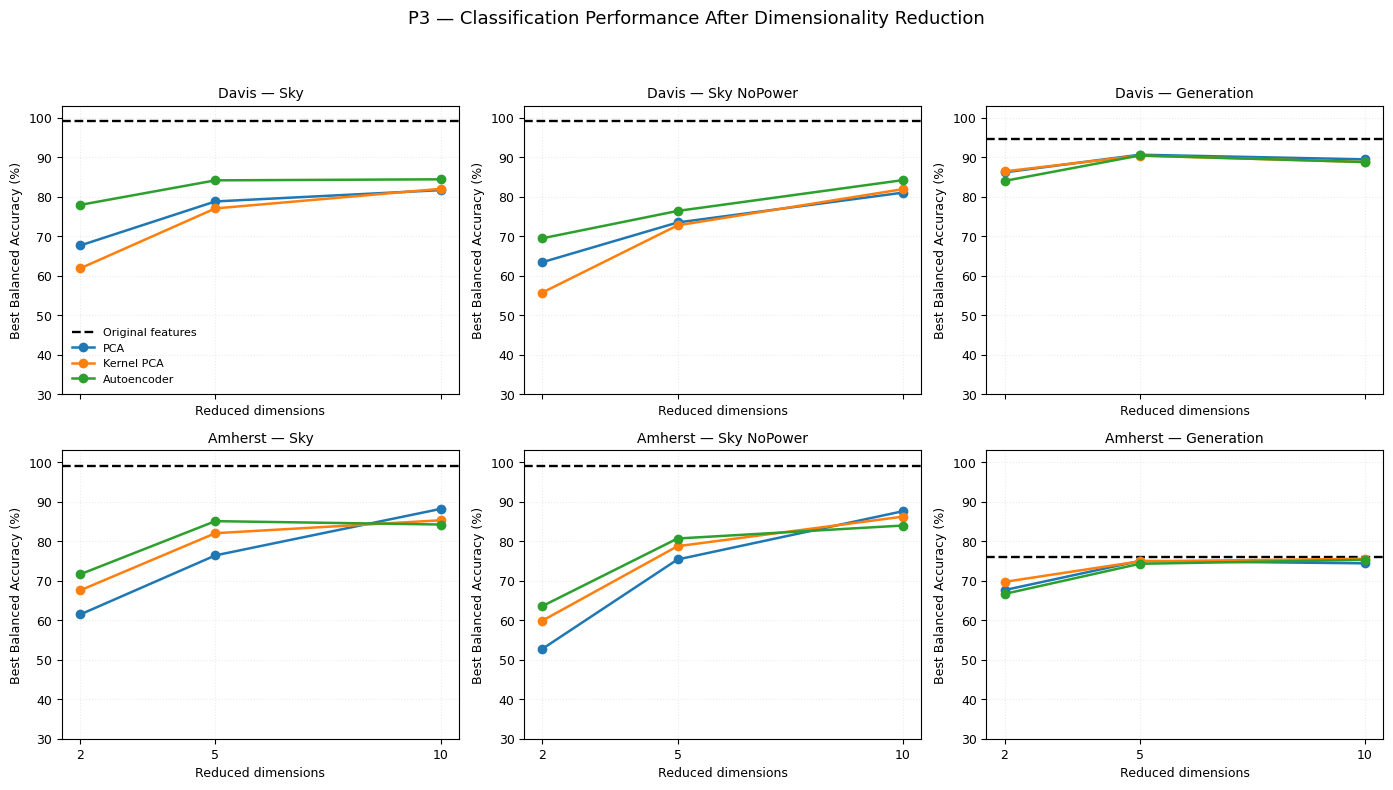

[PREVIEW] P3_Regression_All_Methods.pdf


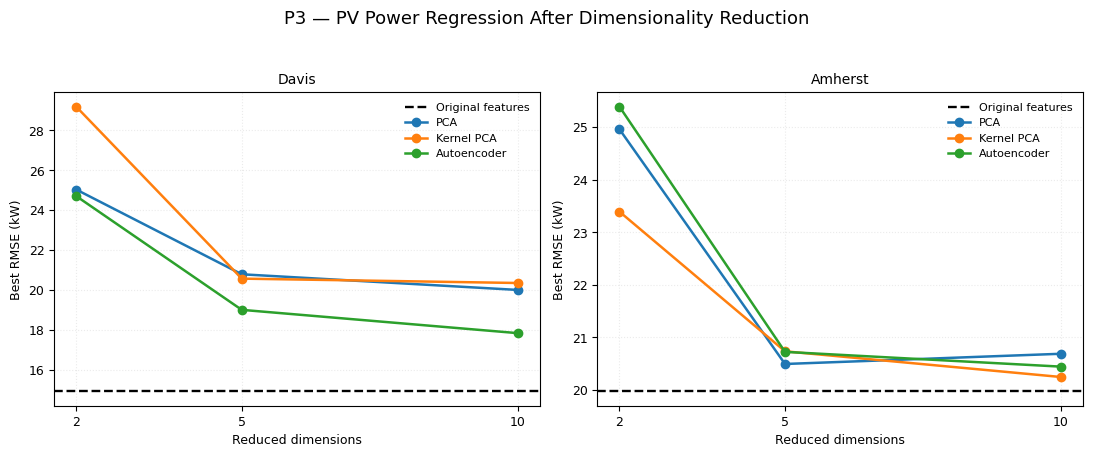


BEST REDUCED CONFIGURATION PER DATASET/TASK


,Dataset,Task,Method,Dimensions,Best Reduced Model,Best Reduced Score,Best Raw Score,Improvement
0,Amherst_2018_2020,Generation,Kernel PCA,10,Random Forest,0.7556,0.7606,-0.0050
1,Amherst_2018_2020,Regression,Kernel PCA,10,MLP (PyTorch),20.2494,19.9743,-0.2751
2,Amherst_2018_2020,Sky,PCA,10,SVM (RBF),0.8819,0.9898,-0.1079
3,Amherst_2018_2020,Sky_NoPower,PCA,10,SVM (RBF),0.8760,0.9896,-0.1136
4,Davis_2011_2016,Generation,PCA,5,SVM (RBF),0.9062,0.9450,-0.0388
5,Davis_2011_2016,Regression,Autoencoder,10,SVR (RBF),17.8467,14.9268,-2.9199
6,Davis_2011_2016,Sky,Autoencoder,10,SVM (RBF),0.8440,0.9917,-0.1477
7,Davis_2011_2016,Sky_NoPower,Autoencoder,10,SVM (RBF),0.8419,0.9920,-0.1501



SAVED RESULTS
Full comparison : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/P3_All_Methods_Downstream_Comparison.csv
Best settings   : /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/P3_Best_Reduced_Configurations.csv

All comparisons are based on held-out test results.
The plots summarize observed model performance.
No models or dimensionality reducers were retrained.


In [13]:

# ============================================================
# P3 — Cell 14: Dimensionality Reduction Comparison
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ------------------------------------------------------------
# 1. Collect previously completed downstream results
# ------------------------------------------------------------

P3_METHOD_SUMMARIES = {
    "PCA": P3_PCA_DOWNSTREAM_SUMMARY,
    "Kernel PCA": P3_KPCA_DOWNSTREAM_SUMMARY,
    "Autoencoder": P3_AE_DOWNSTREAM_SUMMARY
}

P3_COMPARISON_ROWS = []

for dataset in P3_BASELINE_DATASETS:

    for task in P3_BASELINE_TASKS:

        is_classification = (
            task in P3_ALL_CLASSIFICATION_TASKS
        )

        metric = (
            "Balanced_Accuracy_Mean"
            if is_classification
            else "RMSE_Mean"
        )

        # Best original-feature model for this task.
        raw_subset = P3_RAW_SUMMARY[
            (P3_RAW_SUMMARY["Dataset"] == dataset)
            & (P3_RAW_SUMMARY["Task"] == task)
        ]

        assert len(raw_subset) == 5

        raw_best = (
            raw_subset.loc[raw_subset[metric].idxmax()]
            if is_classification
            else raw_subset.loc[raw_subset[metric].idxmin()]
        )

        raw_score = float(raw_best[metric])

        for method, summary in P3_METHOD_SUMMARIES.items():

            for d in P3_DIMENSIONS:

                subset = summary[
                    (summary["Dataset"] == dataset)
                    & (summary["Task"] == task)
                    & (summary["Reduced Dimensions"] == d)
                ]

                assert len(subset) == 5

                # Best compressed-feature model.
                best = (
                    subset.loc[subset[metric].idxmax()]
                    if is_classification
                    else subset.loc[subset[metric].idxmin()]
                )

                reduced_score = float(best[metric])

                # Positive value means reduced features
                # outperformed the best raw-feature model.
                improvement = (
                    reduced_score - raw_score
                    if is_classification
                    else raw_score - reduced_score
                )

                P3_COMPARISON_ROWS.append({
                    "Dataset": dataset,
                    "Task": task,
                    "Method": method,
                    "Dimensions": int(d),
                    "Metric": (
                        "Balanced Accuracy"
                        if is_classification
                        else "RMSE (kW)"
                    ),
                    "Best Raw Model": raw_best["Model"],
                    "Best Raw Score": raw_score,
                    "Best Reduced Model": best["Model"],
                    "Best Reduced Score": reduced_score,
                    "Improvement": improvement
                })


P3_METHOD_COMPARISON = pd.DataFrame(
    P3_COMPARISON_ROWS
)

assert len(P3_METHOD_COMPARISON) == 72

assert not P3_METHOD_COMPARISON.duplicated(
    ["Dataset", "Task", "Method", "Dimensions"]
).any()


# ------------------------------------------------------------
# 2. Save comparison tables
# ------------------------------------------------------------

comparison_path = (
    P3_RESULTS_DIR
    / "P3_All_Methods_Downstream_Comparison.csv"
)

P3_METHOD_COMPARISON.to_csv(
    comparison_path,
    index=False
)

comparison_10d = P3_METHOD_COMPARISON[
    P3_METHOD_COMPARISON["Dimensions"] == 10
].copy()

comparison_10d.to_csv(
    P3_RESULTS_DIR
    / "P3_All_Methods_10D_Comparison.csv",
    index=False
)

print("=" * 75)
print("P3 — DOWNSTREAM DIMENSIONALITY REDUCTION COMPARISON")
print("=" * 75)

print("\n10-DIMENSION RESULTS")
print("Improvement > 0 means compression performed better.")

display(
    comparison_10d[
        [
            "Dataset",
            "Task",
            "Method",
            "Best Raw Score",
            "Best Reduced Score",
            "Improvement"
        ]
    ].round(4).reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Prepare plots
# ------------------------------------------------------------

P3_PLOT_CITIES = {
    "Davis": "Davis_2011_2016",
    "Amherst": "Amherst_2018_2020"
}

P3_METHOD_COLORS = {
    "PCA": "tab:blue",
    "Kernel PCA": "tab:orange",
    "Autoencoder": "tab:green"
}


def p3_save_or_preview(fig, filename):

    fig.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    if P3_SAVE_FINAL_FIGURES:

        fig.savefig(
            P3_FIGURES_DIR / filename,
            format="pdf",
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"[SAVED] {filename}")

    else:

        print(f"[PREVIEW] {filename}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 4. Figure 1: Classification performance
# ------------------------------------------------------------

classification_tasks = (
    "Sky",
    "Sky_NoPower",
    "Generation"
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8),
    sharex=True
)

for row_index, (city, dataset) in enumerate(
    P3_PLOT_CITIES.items()
):

    for column_index, task in enumerate(
        classification_tasks
    ):

        ax = axes[row_index, column_index]

        subset = P3_METHOD_COMPARISON[
            (P3_METHOD_COMPARISON["Dataset"] == dataset)
            & (P3_METHOD_COMPARISON["Task"] == task)
        ]

        raw_score = (
            subset["Best Raw Score"].iloc[0] * 100
        )

        ax.axhline(
            raw_score,
            color="black",
            linestyle="--",
            linewidth=1.7,
            label="Original features"
        )

        for method in P3_METHOD_SUMMARIES:

            method_rows = subset[
                subset["Method"] == method
            ].sort_values("Dimensions")

            ax.plot(
                method_rows["Dimensions"],
                100 * method_rows["Best Reduced Score"],
                marker="o",
                linewidth=1.8,
                color=P3_METHOD_COLORS[method],
                label=method
            )

        ax.set_title(
            f"{city} — {task.replace('_', ' ')}"
        )

        ax.set_xlabel("Reduced dimensions")

        ax.set_ylabel(
            "Best Balanced Accuracy (%)"
        )

        ax.set_xticks(P3_DIMENSIONS)
        ax.set_ylim(30, 103)
        ax.grid(alpha=0.25, linestyle=":")

        if row_index == 0 and column_index == 0:
            ax.legend(fontsize=8, frameon=False)


fig.suptitle(
    "P3 — Classification Performance After "
    "Dimensionality Reduction",
    fontsize=13
)

p3_save_or_preview(
    fig,
    "P3_Classification_All_Methods.pdf"
)


# ------------------------------------------------------------
# 5. Figure 2: Power regression performance
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.6)
)

for ax, (city, dataset) in zip(
    axes,
    P3_PLOT_CITIES.items()
):

    subset = P3_METHOD_COMPARISON[
        (P3_METHOD_COMPARISON["Dataset"] == dataset)
        & (P3_METHOD_COMPARISON["Task"] == "Regression")
    ]

    raw_rmse = float(
        subset["Best Raw Score"].iloc[0]
    )

    ax.axhline(
        raw_rmse,
        color="black",
        linestyle="--",
        linewidth=1.7,
        label="Original features"
    )

    for method in P3_METHOD_SUMMARIES:

        method_rows = subset[
            subset["Method"] == method
        ].sort_values("Dimensions")

        ax.plot(
            method_rows["Dimensions"],
            method_rows["Best Reduced Score"],
            marker="o",
            linewidth=1.8,
            color=P3_METHOD_COLORS[method],
            label=method
        )

    ax.set_title(city)
    ax.set_xlabel("Reduced dimensions")
    ax.set_ylabel("Best RMSE (kW)")
    ax.set_xticks(P3_DIMENSIONS)
    ax.grid(alpha=0.25, linestyle=":")
    ax.legend(fontsize=8, frameon=False)


fig.suptitle(
    "P3 — PV Power Regression After "
    "Dimensionality Reduction",
    fontsize=13
)

p3_save_or_preview(
    fig,
    "P3_Regression_All_Methods.pdf"
)


# ------------------------------------------------------------
# 6. Identify the best reduced representation
# ------------------------------------------------------------

best_rows = []

for (dataset, task), group in (
    P3_METHOD_COMPARISON.groupby(
        ["Dataset", "Task"]
    )
):

    # Improvement is positive when compression helps,
    # regardless of whether the metric is BA or RMSE.
    best_row = group.loc[
        group["Improvement"].idxmax()
    ]

    best_rows.append(best_row)


P3_BEST_REDUCED_SUMMARY = pd.DataFrame(
    best_rows
)

best_path = (
    P3_RESULTS_DIR
    / "P3_Best_Reduced_Configurations.csv"
)

P3_BEST_REDUCED_SUMMARY.to_csv(
    best_path,
    index=False
)

print("\nBEST REDUCED CONFIGURATION PER DATASET/TASK")

display(
    P3_BEST_REDUCED_SUMMARY[
        [
            "Dataset",
            "Task",
            "Method",
            "Dimensions",
            "Best Reduced Model",
            "Best Reduced Score",
            "Best Raw Score",
            "Improvement"
        ]
    ].round(4).reset_index(drop=True)
)

print("\nSAVED RESULTS")
print(f"Full comparison : {comparison_path}")
print(f"Best settings   : {best_path}")

print("\nAll comparisons are based on held-out test results.")
print("The plots summarize observed model performance.")
print("No models or dimensionality reducers were retrained.")


[t-SNE] Davis | Sky | 2500 training samples
[t-SNE] Davis | Generation | 2500 training samples


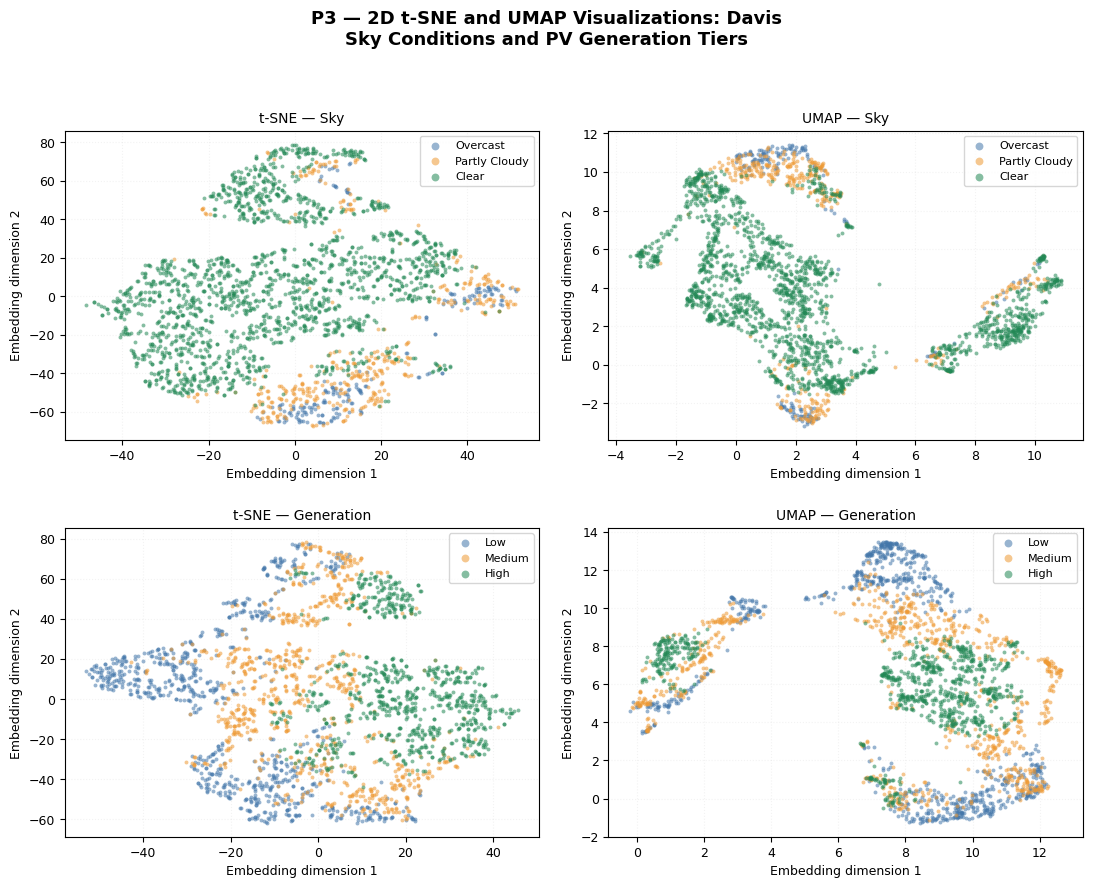

[SAVED] P3_2D_tSNE_UMAP_Davis.pdf
[SAVED] P3_2D_tSNE_UMAP_Davis.png
[t-SNE] Amherst | Sky | 2500 training samples
[t-SNE] Amherst | Generation | 2500 training samples


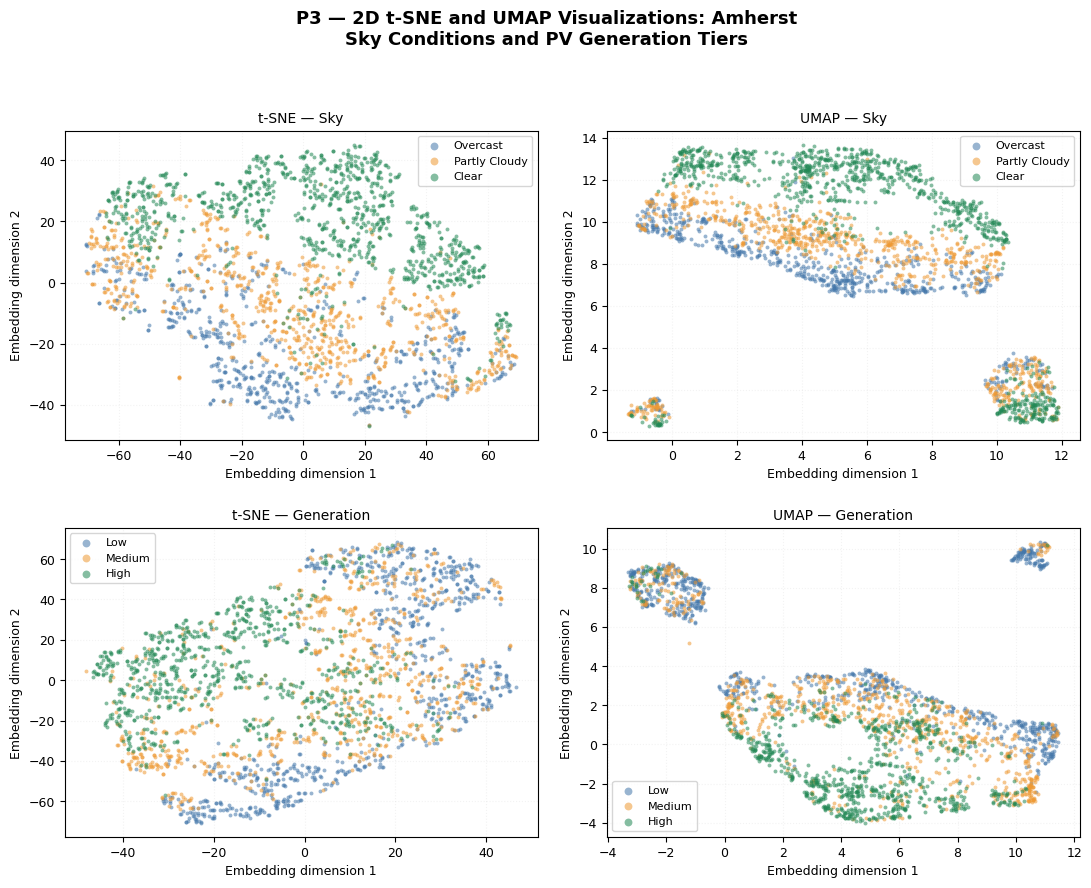

[SAVED] P3_2D_tSNE_UMAP_Amherst.pdf
[SAVED] P3_2D_tSNE_UMAP_Amherst.png

P3 — 2D VISUALIZATIONS COMPLETED


,Dataset,Task,Samples,Original Dimensions,Visualization Dimensions,t-SNE Perplexity,UMAP Neighbors,Seed
0,Davis_2011_2016,Sky,2500,32,2,30,25,42
1,Davis_2011_2016,Generation,2500,33,2,30,25,42
2,Amherst_2018_2020,Sky,2500,33,2,30,25,42
3,Amherst_2018_2020,Generation,2500,34,2,30,25,42



Figure directory: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P3
Audit file: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Results/P3/P3_2D_Visualization_Audit.csv

Four visualization files saved: 2 PDF + 2 PNG.
Only training observations were visualized.
No supervised prediction models were retrained.


In [14]:

# ============================================================
# P3 — Cell 15: 2D t-SNE and UMAP Visualizations
# ============================================================

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from IPython.display import display


# ------------------------------------------------------------
# 1. Visualization settings
# ------------------------------------------------------------

P3_VIS_DATASETS = {
    "Davis": "Davis_2011_2016",
    "Amherst": "Amherst_2018_2020"
}

P3_VIS_TASKS = ("Sky", "Generation")

P3_VIS_SAMPLE_SIZE = 2500
P3_VIS_SEED = 42

P3_VIS_COLORS = (
    "#4477AA",
    "#EE9933",
    "#228855"
)

P3_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

visualization_records = []


# ------------------------------------------------------------
# 2. Helper: Fit 2D t-SNE
# ------------------------------------------------------------

def p3_fit_tsne_2d(X):

    settings = {
        "n_components": 2,
        "perplexity": 30,
        "learning_rate": "auto",
        "init": "pca",
        "random_state": P3_VIS_SEED,
        "method": "barnes_hut"
    }

    # Support different scikit-learn versions.
    if "max_iter" in inspect.signature(TSNE).parameters:
        settings["max_iter"] = 1000
    else:
        settings["n_iter"] = 1000

    reducer = TSNE(**settings)

    return reducer.fit_transform(X)


# ------------------------------------------------------------
# 3. Helper: Plot class-colored embeddings
# ------------------------------------------------------------

def p3_plot_embedding(ax, Z, labels, class_names, title):

    for class_id, class_name in enumerate(class_names):

        mask = labels == class_id

        ax.scatter(
            Z[mask, 0],
            Z[mask, 1],
            s=8,
            alpha=0.55,
            color=P3_VIS_COLORS[class_id],
            label=class_name,
            linewidths=0,
            rasterized=True
        )

    ax.set_title(title)
    ax.set_xlabel("Embedding dimension 1")
    ax.set_ylabel("Embedding dimension 2")
    ax.legend(
        loc="best",
        fontsize=8,
        frameon=True,
        markerscale=2
    )

    ax.grid(
        alpha=0.15,
        linestyle=":"
    )


# ------------------------------------------------------------
# 4. Generate plots for each city
# ------------------------------------------------------------

for city, dataset_key in P3_VIS_DATASETS.items():

    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 9)
    )

    for row, task in enumerate(P3_VIS_TASKS):

        prepared = P3_PREPROCESSED[
            dataset_key
        ][task]

        X_train = np.asarray(
            prepared["X_train"],
            dtype=np.float32
        )

        y_train = np.asarray(
            prepared["y_train"],
            dtype=int
        )

        # ----------------------------------------------------
        # A. Select a reproducible stratified training subset
        # ----------------------------------------------------

        sample_size = min(
            P3_VIS_SAMPLE_SIZE,
            len(X_train)
        )

        selected_positions, _ = train_test_split(
            np.arange(len(X_train)),
            train_size=sample_size,
            stratify=y_train,
            random_state=P3_VIS_SEED
        )

        selected_positions = np.sort(
            selected_positions
        )

        X_sample = X_train[selected_positions]
        y_sample = y_train[selected_positions]

        assert len(X_sample) == sample_size

        # ----------------------------------------------------
        # B. Compute t-SNE from standardized training features
        # ----------------------------------------------------

        print(
            f"[t-SNE] {city} | {task} | "
            f"{sample_size} training samples",
            flush=True
        )

        Z_tsne = p3_fit_tsne_2d(X_sample)

        assert Z_tsne.shape == (
            sample_size, 2
        )

        assert np.isfinite(Z_tsne).all()

        # ----------------------------------------------------
        # C. Load the previously fitted 2D UMAP embedding
        # ----------------------------------------------------

        umap_path = (
            P3_UMAP_EMBEDDING_DIR
            / f"{dataset_key}_{task}_d2.npz"
        )

        with np.load(umap_path) as saved:

            Z_umap_full = saved["X_train"].copy()

            np.testing.assert_array_equal(
                saved["train_rows"],
                prepared["train_rows"]
            )

        assert Z_umap_full.shape == (
            len(X_train), 2
        )

        Z_umap = Z_umap_full[selected_positions]

        assert np.isfinite(Z_umap).all()

        # ----------------------------------------------------
        # D. Plot identical observations with both techniques
        # ----------------------------------------------------

        class_names = P3_CLASS_NAMES[task]

        p3_plot_embedding(
            axes[row, 0],
            Z_tsne,
            y_sample,
            class_names,
            f"t-SNE — {task}"
        )

        p3_plot_embedding(
            axes[row, 1],
            Z_umap,
            y_sample,
            class_names,
            f"UMAP — {task}"
        )

        visualization_records.append({
            "Dataset": dataset_key,
            "Task": task,
            "Samples": sample_size,
            "Original Dimensions": X_train.shape[1],
            "Visualization Dimensions": 2,
            "t-SNE Perplexity": 30,
            "UMAP Neighbors": 25,
            "Seed": P3_VIS_SEED
        })

    # --------------------------------------------------------
    # E. Save both PDF and PNG figures
    # --------------------------------------------------------

    fig.suptitle(
        f"P3 — 2D t-SNE and UMAP Visualizations: {city}\n"
        "Sky Conditions and PV Generation Tiers",
        fontsize=13,
        fontweight="bold"
    )

    fig.tight_layout(
        rect=(0, 0, 1, 0.94),
        h_pad=2.2,
        w_pad=1.8
    )

    pdf_path = (
        P3_FIGURES_DIR
        / f"P3_2D_tSNE_UMAP_{city}.pdf"
    )

    png_path = (
        P3_FIGURES_DIR
        / f"P3_2D_tSNE_UMAP_{city}.png"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        png_path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {pdf_path.name}")
    print(f"[SAVED] {png_path.name}")


# ------------------------------------------------------------
# 5. Save visualization audit
# ------------------------------------------------------------

P3_VISUALIZATION_AUDIT = pd.DataFrame(
    visualization_records
)

audit_path = (
    P3_RESULTS_DIR
    / "P3_2D_Visualization_Audit.csv"
)

P3_VISUALIZATION_AUDIT.to_csv(
    audit_path,
    index=False
)

print("\n" + "=" * 75)
print("P3 — 2D VISUALIZATIONS COMPLETED")
print("=" * 75)

display(P3_VISUALIZATION_AUDIT)

print(f"\nFigure directory: {P3_FIGURES_DIR}")
print(f"Audit file: {audit_path}")
print("\nFour visualization files saved: 2 PDF + 2 PNG.")
print("Only training observations were visualized.")
print("No supervised prediction models were retrained.")


[SAVED] P3_Final_PCA_Explained_Variance.pdf


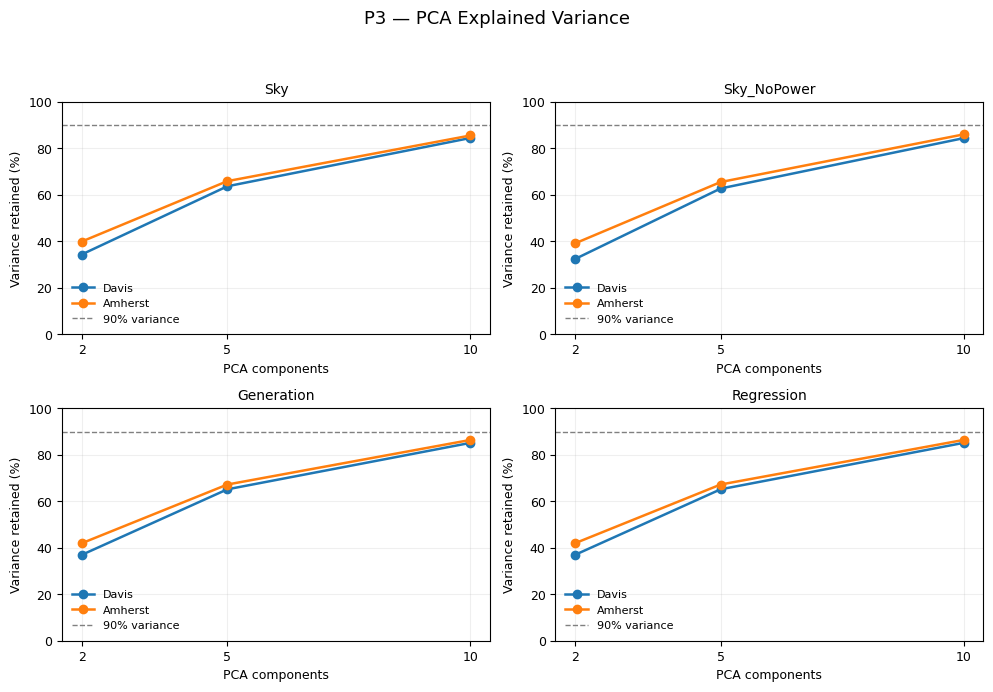

[SAVED] P3_Final_Reconstruction_Comparison.pdf


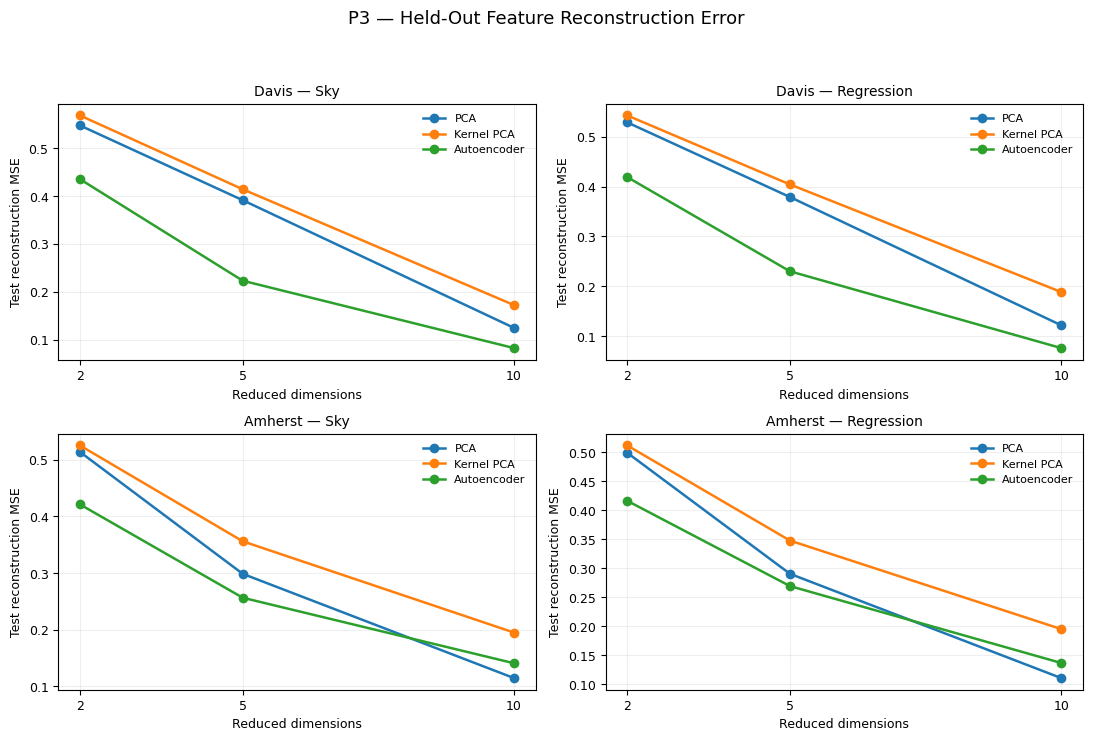

[SAVED] P3_Classification_All_Methods.pdf


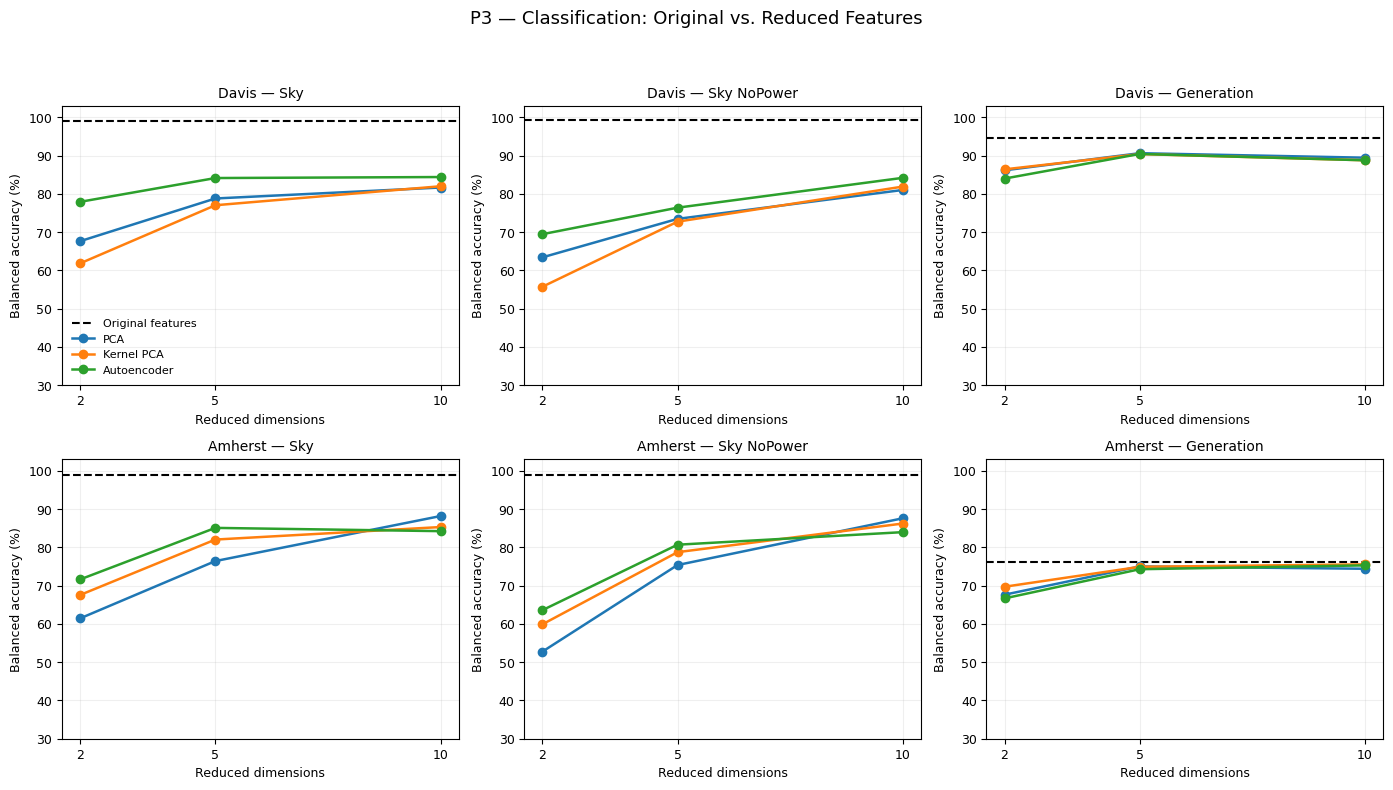

[SAVED] P3_Regression_All_Methods.pdf


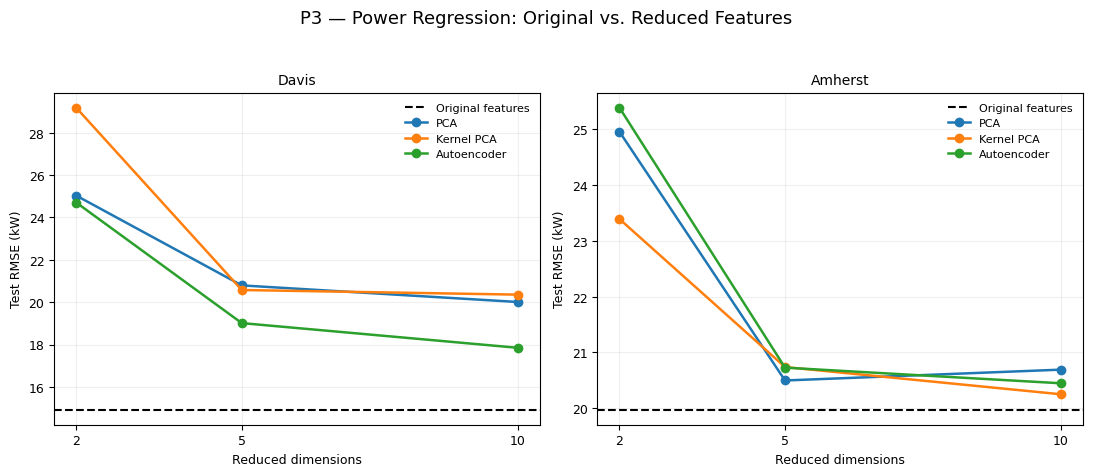


P3 — FINAL FIGURE EXPORT COMPLETE

Final comparison PDFs:
  P3_Final_PCA_Explained_Variance.pdf
  P3_Final_Reconstruction_Comparison.pdf
  P3_Classification_All_Methods.pdf
  P3_Regression_All_Methods.pdf

2D visualization PDFs:
  [FOUND] P3_2D_tSNE_UMAP_Davis.pdf
  [FOUND] P3_2D_tSNE_UMAP_Amherst.pdf

Verified PDFs: 6
Output directory: /content/drive/MyDrive/Colab Notebooks/ML_ECE_571_Project/Code_base_v2/Figures/P3

No models were retrained.
All final comparison figures were exported.


In [15]:

# ============================================================
# P3 — Cell 16: Export Final Results and Figures
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ------------------------------------------------------------
# 1. Load saved experimental results
# ------------------------------------------------------------

P3_SAVE_FINAL_FIGURES = True

P3_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.read_csv(
    P3_RESULTS_DIR /
    "P3_All_Methods_Downstream_Comparison.csv"
)

pca_metrics = pd.read_csv(
    P3_RESULTS_DIR / "PCA_Intrinsic_Metrics.csv"
)

kpca_metrics = pd.read_csv(
    P3_RESULTS_DIR / "KPCA_Intrinsic_Metrics.csv"
)

ae_summary = pd.read_csv(
    P3_RESULTS_DIR / "AE_Intrinsic_Summary.csv"
)

cities = {
    "Davis": "Davis_2011_2016",
    "Amherst": "Amherst_2018_2020"
}

methods = ("PCA", "Kernel PCA", "Autoencoder")
dimensions = (2, 5, 10)

exported_figures = []


def p3_export_figure(fig, filename):

    path = P3_FIGURES_DIR / filename

    fig.tight_layout(
        rect=(0, 0, 1, 0.94)
    )

    fig.savefig(
        path,
        format="pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    exported_figures.append(path)

    print(f"[SAVED] {filename}")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 2. PCA explained variance
# ------------------------------------------------------------

variance_column = next(
    column
    for column in pca_metrics.columns
    if "variance" in column.lower()
    and (
        "retained" in column.lower()
        or "cumulative" in column.lower()
    )
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 7)
)

for ax, task in zip(
    axes.flat,
    ("Sky", "Sky_NoPower", "Generation", "Regression")
):

    for city, dataset in cities.items():

        subset = pca_metrics[
            (pca_metrics["Dataset"] == dataset)
            & (pca_metrics["Task"] == task)
        ].sort_values("Reduced Dimensions")

        values = subset[
            variance_column
        ].to_numpy(dtype=float)

        if np.nanmax(values) <= 1.01:
            values = 100 * values

        ax.plot(
            subset["Reduced Dimensions"],
            values,
            marker="o",
            linewidth=1.8,
            label=city
        )

    ax.axhline(
        90,
        linestyle="--",
        color="gray",
        linewidth=1,
        label="90% variance"
    )

    ax.set_title(task)
    ax.set_xlabel("PCA components")
    ax.set_ylabel("Variance retained (%)")
    ax.set_xticks(dimensions)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    "P3 — PCA Explained Variance",
    fontsize=13
)

p3_export_figure(
    fig,
    "P3_Final_PCA_Explained_Variance.pdf"
)


# ------------------------------------------------------------
# 3. Reconstruction error comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7.5)
)

for row, (city, dataset) in enumerate(cities.items()):

    for col, task in enumerate(("Sky", "Regression")):

        ax = axes[row, col]

        for method, data, metric in (
            (
                "PCA",
                pca_metrics,
                "Test Reconstruction MSE"
            ),
            (
                "Kernel PCA",
                kpca_metrics,
                "Test Reconstruction MSE"
            ),
            (
                "Autoencoder",
                ae_summary,
                "Test_MSE_Mean"
            )
        ):

            subset = data[
                (data["Dataset"] == dataset)
                & (data["Task"] == task)
            ].sort_values("Reduced Dimensions")

            ax.plot(
                subset["Reduced Dimensions"],
                subset[metric],
                marker="o",
                linewidth=1.8,
                label=method
            )

        ax.set_title(f"{city} — {task}")
        ax.set_xlabel("Reduced dimensions")
        ax.set_ylabel("Test reconstruction MSE")
        ax.set_xticks(dimensions)
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    "P3 — Held-Out Feature Reconstruction Error",
    fontsize=13
)

p3_export_figure(
    fig,
    "P3_Final_Reconstruction_Comparison.pdf"
)


# ------------------------------------------------------------
# 4. Classification performance comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

for row, (city, dataset) in enumerate(cities.items()):

    for col, task in enumerate(
        ("Sky", "Sky_NoPower", "Generation")
    ):

        ax = axes[row, col]

        subset = comparison[
            (comparison["Dataset"] == dataset)
            & (comparison["Task"] == task)
        ]

        raw_score = float(
            subset["Best Raw Score"].iloc[0]
        )

        ax.axhline(
            100 * raw_score,
            color="black",
            linestyle="--",
            label="Original features"
        )

        for method in methods:

            selected = subset[
                subset["Method"] == method
            ].sort_values("Dimensions")

            ax.plot(
                selected["Dimensions"],
                100 * selected["Best Reduced Score"],
                marker="o",
                linewidth=1.8,
                label=method
            )

        ax.set_title(
            f"{city} — {task.replace('_', ' ')}"
        )
        ax.set_xlabel("Reduced dimensions")
        ax.set_ylabel("Balanced accuracy (%)")
        ax.set_xticks(dimensions)
        ax.set_ylim(30, 103)
        ax.grid(alpha=0.2)

        if row == 0 and col == 0:
            ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    "P3 — Classification: Original vs. Reduced Features",
    fontsize=13
)

p3_export_figure(
    fig,
    "P3_Classification_All_Methods.pdf"
)


# ------------------------------------------------------------
# 5. Power regression performance comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.8)
)

for ax, (city, dataset) in zip(
    axes,
    cities.items()
):

    subset = comparison[
        (comparison["Dataset"] == dataset)
        & (comparison["Task"] == "Regression")
    ]

    raw_rmse = float(
        subset["Best Raw Score"].iloc[0]
    )

    ax.axhline(
        raw_rmse,
        color="black",
        linestyle="--",
        label="Original features"
    )

    for method in methods:

        selected = subset[
            subset["Method"] == method
        ].sort_values("Dimensions")

        ax.plot(
            selected["Dimensions"],
            selected["Best Reduced Score"],
            marker="o",
            linewidth=1.8,
            label=method
        )

    ax.set_title(city)
    ax.set_xlabel("Reduced dimensions")
    ax.set_ylabel("Test RMSE (kW)")
    ax.set_xticks(dimensions)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    "P3 — Power Regression: Original vs. Reduced Features",
    fontsize=13
)

p3_export_figure(
    fig,
    "P3_Regression_All_Methods.pdf"
)


# ------------------------------------------------------------
# 6. Verify previously saved visualization figures
# ------------------------------------------------------------

visualization_files = [
    P3_FIGURES_DIR / f"P3_2D_tSNE_UMAP_{city}.pdf"
    for city in cities
]

print("\n" + "=" * 75)
print("P3 — FINAL FIGURE EXPORT COMPLETE")
print("=" * 75)

print("\nFinal comparison PDFs:")
for path in exported_figures:
    print(f"  {path.name}")

print("\n2D visualization PDFs:")
for path in visualization_files:
    print(
        f"  {'[FOUND]' if path.is_file() else '[MISSING]'} "
        f"{path.name}"
    )

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in exported_figures
)

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in visualization_files
)

print(f"\nVerified PDFs: {len(exported_figures) + len(visualization_files)}")
print(f"Output directory: {P3_FIGURES_DIR}")
print("\nNo models were retrained.")
print("All final comparison figures were exported.")
